Design Analisis in most visited tourism sites

In [1]:
import pandas as pd
import numpy as np
import json
from pathlib import Path
from urllib.parse import urlparse, urlunparse, urljoin, unquote
from collections import Counter

import matplotlib.pyplot as plt
import seaborn as sns

import mimetypes
import re
import unicodedata
import ast

import colorsys
import os
import warnings
from itertools import combinations

Fixing dataset

In [2]:
INPUT = Path("output/tourism_design_dataset.csv")
OUTPUT = Path("analysis")

OUTPUT.mkdir(exist_ok=True)

# Loading

df = pd.read_csv(
    INPUT,
    encoding="utf-8-sig",
    low_memory=False
)

print("\n========== DATASET ==========")

print("Files:", len(df))
print("Rows:", len(df.columns))

print("\nRows Names:")
print(df.columns.tolist())

# Types

print("\n========== TYPES ==========")

print(df.dtypes)

# Null values

null_report = pd.DataFrame({
    "column": df.columns,
    "null_count": df.isna().sum().values,
    "null_percentage": (
        df.isna().mean().values * 100
    ).round(2)
})

null_report = null_report.sort_values(
    "null_percentage",
    ascending=False
)

null_report.to_csv(
    OUTPUT / "missing_values.csv",
    index=False
)

print("\n========== NULL VALUES ==========")
print(null_report.to_string(index=False))

# Duplicated

print("\n========== DUPLICATED ==========")

print(
    "Duplicated rows:",
    df.duplicated().sum()
)

# search repeated domains
if "domain" in df.columns:

    print(
        "Duplicated domains:",
        df["domain"].duplicated().sum()
    )

# Manage HTTP status

if "http_status" in df.columns:

    status_report = (
        df["http_status"]
        .value_counts(dropna=False)
        .reset_index()
    )

    status_report.columns = [
        "http_status",
        "count"
    ]

    status_report.to_csv(
        OUTPUT / "http_status_distribution.csv",
        index=False
    )

    print("\n========== HTTP STATUS ==========")
    print(status_report.to_string(index=False))

# JSON fields

def parse_json(value):

    if pd.isna(value):
        return None

    if isinstance(value, (dict, list)):
        return value

    try:
        return json.loads(value)

    except (ValueError, TypeError):
        return None


json_columns = []

for col in df.columns:

    sample = df[col].dropna().head(10)

    if len(sample) == 0:
        continue

    valid_json = sum(
        parse_json(value) is not None
        for value in sample
    )

    if valid_json >= len(sample) * 0.5:
        json_columns.append(col)

print("\n========== JSON fields ==========")
print(json_columns)

# Quality

if "http_status" in df.columns:

    df["http_status"] = pd.to_numeric(
        df["http_status"],
        errors="coerce"
    )

    df["http_success"] = (
        df["http_status"] == 200
    )

if "domain" in df.columns:

    df["domain_clean"] = (
        df["domain"]
        .astype(str)
        .str.lower()
        .str.replace(r"^www\.", "", regex=True)
        .str.strip()
    )

# Export

df.to_csv(
    OUTPUT / "dataset_audited.csv",
    index=False,
    encoding="utf-8-sig"
)

summary = {
    "total_records": len(df),
    "total_columns": len(df.columns),
    "duplicate_rows": int(df.duplicated().sum()),
    "json_columns": json_columns,
    "columns": df.columns.tolist()
}

with open(
    OUTPUT / "audit_summary.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        summary,
        file,
        indent=4,
        ensure_ascii=False
    )

print("\nFix finished.")
print("Results saved in:", OUTPUT)


========== DATASET ==========
Files: 1457
Rows: 49

Rows Names:
['original_url', 'final_url', 'domain', 'fetched_at', 'http_status', 'robots_status', 'scrape_status', 'error', 'title', 'description', 'keywords', 'language', 'canonical', 'robots', 'og_title', 'og_description', 'og_image', 'og_type', 'twitter_card', 'favicon', 'viewport', 'headings', 'images', 'large_images', 'image_count', 'large_image_count', 'logo_candidates', 'logo_candidate_count', 'hero', 'background_colors', 'text_colors', 'border_colors', 'font_families', 'loaded_fonts', 'header_position', 'nav_links', 'search_inputs', 'search_present', 'button_count', 'card_candidate_count', 'sticky_elements', 'grid_elements', 'flex_elements', 'video_count', 'svg_count', 'social_links', 'css_files', 'json_ld', 'body_text_length']

========== TYPES ==========
original_url             object
final_url                object
domain                   object
fetched_at               object
http_status             float64
robots_statu

Quality Assestment

In [3]:
# CONFIGURATION

INPUT = Path("analysis/dataset_audited.csv")
OUTPUT = Path("analysis/quality")

OUTPUT.mkdir(parents=True, exist_ok=True)

# LOAD

df = pd.read_csv(INPUT, encoding="utf-8-sig")

# JSON PARSER

def parse_json(value):

    if pd.isna(value):
        return None

    if isinstance(value, (list, dict)):
        return value

    try:
        return json.loads(value)
    except (ValueError, TypeError):
        return None


JSON_FIELDS = [
    "headings",
    "images",
    "large_images",
    "logo_candidates",
    "background_colors",
    "text_colors",
    "border_colors",
    "font_families",
    "loaded_fonts",
    "nav_links",
    "search_inputs",
    "social_links",
    "css_files",
    "json_ld"
]

for col in JSON_FIELDS:

    if col in df.columns:
        df[col + "_parsed"] = df[col].apply(parse_json)


# HELPER FUNCTIONS

def get_list_length(value):

    if isinstance(value, list):
        return len(value)

    if isinstance(value, dict):
        return sum(
            len(v) if isinstance(v, list) else 1
            for v in value.values()
        )

    return 0


def get_text_length(value):

    try:
        return float(value)
    except (ValueError, TypeError):
        return 0


# HTTP CLASSIFICATION

df["http_status"] = pd.to_numeric(
    df["http_status"],
    errors="coerce"
)

def classify_http(status):

    if pd.isna(status):
        return "no_response"

    status = int(status)

    if status == 200:
        return "http_200"

    if status == 403:
        return "forbidden"

    if status == 429:
        return "rate_limited"

    if status == 405:
        return "method_not_allowed"

    if 400 <= status < 500:
        return "client_error"

    if 500 <= status < 600:
        return "server_error"

    if 200 <= status < 300:
        return "other_success"

    return "other"


df["http_class"] = df["http_status"].apply(
    classify_http
)

# VISUAL SIGNALS

visual_fields = [
    "images",
    "logo_candidates",
    "background_colors",
    "text_colors",
    "font_families",
    "loaded_fonts",
    "nav_links",
    "css_files"
]

def count_visual_signals(row):

    count = 0

    for field in visual_fields:

        parsed = row.get(field + "_parsed")

        if get_list_length(parsed) > 0:
            count += 1

    return count


df["visual_signal_count"] = df.apply(
    count_visual_signals,
    axis=1
)

df["body_text_length_num"] = (
    df["body_text_length"].apply(get_text_length)
)

# PAGE QUALITY

def classify_content(row):

    if row["http_class"] != "http_200":
        return "invalid"

    title = str(row.get("title", "")).lower()

    final_url = str(row.get("final_url", "")).lower()

    suspicious_terms = [
        "just a moment",
        "access denied",
        "security verification",
        "captcha",
        "blocked",
        "error"
    ]

    if any(term in title for term in suspicious_terms):
        return "invalid"

    # Weak evidence: potentially intermediate page
    if (
        row["body_text_length_num"] < 300
        and row["visual_signal_count"] < 2
    ):
        return "needs_review"

    # Stronger evidence of real page content
    if (
        row["body_text_length_num"] >= 300
        and row["visual_signal_count"] >= 2
    ):
        return "valid_candidate"

    return "needs_review"


df["content_quality"] = df.apply(
    classify_content,
    axis=1
)

# MANUAL REVIEW FLAGS

def review_reason(row):

    reasons = []

    if row["http_class"] != "http_200":
        reasons.append("http_problem")

    if row["content_quality"] == "needs_review":
        reasons.append("insufficient_content")

    if row["content_quality"] == "invalid":
        reasons.append("invalid_or_blocked_content")

    if (
        row["final_url"]
        and row["original_url"]
        and urlparse(str(row["final_url"])).path
        not in ("", "/")
    ):
        reasons.append("redirected_path")

    return ";".join(reasons)


df["review_reasons"] = df.apply(
    review_reason,
    axis=1
)

# EXPORT

df.to_csv(
    OUTPUT / "site_quality.csv",
    index=False,
    encoding="utf-8-sig"
)

valid = df[
    df["content_quality"] == "valid_candidate"
]

review = df[
    df["content_quality"] == "needs_review"
]

invalid = df[
    df["content_quality"] == "invalid"
]

valid.to_csv(
    OUTPUT / "valid_candidates.csv",
    index=False,
    encoding="utf-8-sig"
)

review.to_csv(
    OUTPUT / "manual_review.csv",
    index=False,
    encoding="utf-8-sig"
)

# SUMMARY

summary = {
    "total_sites": len(df),
    "http_distribution": {
        str(k): int(v)
        for k, v in df["http_class"].value_counts().items()
    },
    "content_quality": {
        str(k): int(v)
        for k, v in df["content_quality"].value_counts().items()
    },
    "valid_candidates": len(valid),
    "needs_review": len(review),
    "invalid": len(invalid)
}

with open(
    OUTPUT / "quality_summary.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=4,
        ensure_ascii=False
    )

print("\nQUALITY ASSESSMENT")
print("==================")

print("Total:", len(df))
print("Valid candidates:", len(valid))
print("Needs review:", len(review))
print("Invalid:", len(invalid))

print("\nHTTP DISTRIBUTION")
print(df["http_class"].value_counts())

print("\nCONTENT QUALITY")
print(df["content_quality"].value_counts())

print("\nFiles generated in:", OUTPUT)



QUALITY ASSESSMENT
Total: 1457
Valid candidates: 907
Needs review: 54
Invalid: 496

HTTP DISTRIBUTION
http_class
http_200              968
no_response           233
forbidden             213
server_error           14
rate_limited           10
other_success           8
client_error            8
method_not_allowed      3
Name: count, dtype: int64

CONTENT QUALITY
content_quality
valid_candidate    907
invalid            496
needs_review        54
Name: count, dtype: int64

Files generated in: analysis\quality


Market Classification

In [4]:
classification = df[[
    "domain",
    "original_url",
    "final_url",
    "content_quality"
]].copy()

classification.insert(
    0,
    "site_id",
    [
        f"S{i:03d}"
        for i in range(1, len(classification) + 1)
    ]
)

classification["market_segment"] = ""
classification["include_in_research"] = ""
classification["notes"] = ""

classification.to_csv(
    OUTPUT / "market_classification_template.csv",
    index=False,
    encoding="utf-8-sig"
)


Color Analisys

In [5]:
import re
import colorsys
from collections import Counter

In [6]:
INPUT = Path("analysis/quality/valid_candidates.csv")
OUTPUT = Path("analysis/colors")

OUTPUT.mkdir(parents=True, exist_ok=True)

COLOR_FIELDS = [
    "background_colors",
    "text_colors",
    "border_colors"
]

# LOAD

df = pd.read_csv(INPUT, encoding="utf-8-sig")

# JSON PARSER

def parse_json(value):

    if pd.isna(value):
        return []

    try:
        result = json.loads(value)

        return result if isinstance(result, list) else []

    except (ValueError, TypeError):
        return []

# COLOR NORMALIZATION

def normalize_hex(value):

    if not isinstance(value, str):
        return None

    value = value.strip().upper()

    if re.fullmatch(r"#[0-9A-F]{3}", value):

        value = "#" + "".join(
            char * 2 for char in value[1:]
        )

    if not re.fullmatch(r"#[0-9A-F]{6}", value):
        return None

    return value


def classify_color(hex_color):

    rgb = tuple(
        int(hex_color[i:i+2], 16) / 255
        for i in (1, 3, 5)
    )

    h, s, v = colorsys.rgb_to_hsv(*rgb)

    hue = h * 360

    if s < 0.10:
        family = "Neutral"
    elif hue < 15 or hue >= 345:
        family = "Red"
    elif hue < 45:
        family = "Orange"
    elif hue < 70:
        family = "Yellow"
    elif hue < 160:
        family = "Green"
    elif hue < 200:
        family = "Cyan"
    elif hue < 255:
        family = "Blue"
    elif hue < 290:
        family = "Purple"
    elif hue < 345:
        family = "Pink"
    else:
        family = "Neutral"

    # Relative luminance (sRGB)
    channels = []

    for c in rgb:

        if c <= 0.04045:
            channels.append(c / 12.92)
        else:
            channels.append(
                ((c + 0.055) / 1.055) ** 2.4
            )

    r, g, b = channels

    luminance = (
        0.2126 * r +
        0.7152 * g +
        0.0722 * b
    )

    return {
        "family": family,
        "hue": hue,
        "saturation": s,
        "value": v,
        "luminance": luminance
    }


# EXTRACT COLORS

records = []

for _, row in df.iterrows():

    domain = row["domain"]

    for field in COLOR_FIELDS:

        colors = parse_json(row.get(field))

        for color in colors:

            hex_value = normalize_hex(
                color.get("value")
            )

            if not hex_value:
                continue

            count = pd.to_numeric(
                color.get("count", 1),
                errors="coerce"
            )

            count = 1 if pd.isna(count) else max(1, int(count))

            properties = classify_color(hex_value)

            records.append({
                "domain": domain,
                "color": hex_value,
                "source": field,
                "element_count": count,
                **properties
            })


colors_df = pd.DataFrame(records)

# EXPORT RAW COLORS

colors_df.to_csv(
    OUTPUT / "color_observations.csv",
    index=False
)

# FREQUENCY BY SITE

site_frequency = (
    colors_df[
        ["color", "domain"]
    ]
    .drop_duplicates()
    .groupby("color")
    .agg(
        site_count=("domain", "nunique")
    )
    .reset_index()
)

site_frequency["site_percentage"] = (
    site_frequency["site_count"] /
    df["domain"].nunique() * 100
)

# FREQUENCY BY ELEMENT

element_frequency = (
    colors_df.groupby("color")
    .agg(
        element_count=("element_count", "sum")
    )
    .reset_index()
)

# COMBINE

color_summary = site_frequency.merge(
    element_frequency,
    on="color",
    how="left"
)

properties = (
    colors_df.groupby("color")
    .first()
    .reset_index()[
        [
            "color",
            "family",
            "hue",
            "saturation",
            "value",
            "luminance"
        ]
    ]
)

color_summary = color_summary.merge(
    properties,
    on="color",
    how="left"
)

color_summary = color_summary.sort_values(
    "site_count",
    ascending=False
)

color_summary.to_csv(
    OUTPUT / "color_frequency.csv",
    index=False
)

# COLOR FAMILIES

family_summary = (
    colors_df[
        ["domain", "family"]
    ]
    .drop_duplicates()
    .groupby("family")
    .agg(
        site_count=("domain", "nunique")
    )
    .reset_index()
)

family_summary["site_percentage"] = (
    family_summary["site_count"] /
    df["domain"].nunique() * 100
)

family_summary = family_summary.sort_values(
    "site_count",
    ascending=False
)

family_summary.to_csv(
    OUTPUT / "color_families.csv",
    index=False
)

# COLOR ROLE ANALYSIS

role_summary = (
    colors_df.groupby("source")
    .agg(
        observations=("color", "count"),
        unique_colors=("color", "nunique"),
        sites=("domain", "nunique")
    )
    .reset_index()
)

role_summary.to_csv(
    OUTPUT / "color_roles.csv",
    index=False
)

# FINAL REPORT

print("\nCOLOR ANALYSIS")
print("======================")

print("Sites:", df["domain"].nunique())
print("Color observations:", len(colors_df))

print("\nTOP 15 COLORS")
print(color_summary.head(15).to_string(index=False))

print("\nCOLOR FAMILIES")
print(family_summary.to_string(index=False))

print("\nCOLOR ROLES")
print(role_summary.to_string(index=False))

print("\nResults:", OUTPUT)


COLOR ANALYSIS
Sites: 907
Color observations: 23927

TOP 15 COLORS
  color  site_count  site_percentage  element_count  family   hue  saturation    value  luminance
#FFFFFF         898        99.007718         253624 Neutral   0.0         0.0 1.000000   1.000000
#000000         731        80.595369         234046 Neutral   0.0         0.0 0.000000   0.000000
#333333         233        25.689085          79614 Neutral   0.0         0.0 0.200000   0.033105
#808080         146        16.097023           4149 Neutral   0.0         0.0 0.501961   0.215861
#0000EE         134        14.773980          25907    Blue 240.0         1.0 0.933333   0.061730
#666666         116        12.789416          12468 Neutral   0.0         0.0 0.400000   0.132868
#CCCCCC         106        11.686880           2299 Neutral   0.0         0.0 0.800000   0.603827
#EEEEEE          90         9.922822           1095 Neutral   0.0         0.0 0.933333   0.854993
#222222          86         9.481808          2607

Colors Roles check

In [7]:
INPUT = Path("analysis/quality/valid_candidates.csv")
OUTPUT = Path("analysis/colors/roles")

OUTPUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(INPUT, encoding="utf-8-sig")

COLOR_FIELDS = [
    "background_colors",
    "text_colors",
    "border_colors"
]

# PARSE JSON

def parse_json(value):

    if pd.isna(value):
        return []

    try:
        result = json.loads(value)
        return result if isinstance(result, list) else []

    except (ValueError, TypeError):
        return []


# EXTRACT COLORS BY ROLE

records = []

for _, row in df.iterrows():

    for field in COLOR_FIELDS:

        colors = parse_json(row[field])

        for item in colors:

            color = item.get("value")

            if not color:
                continue

            records.append({
                "domain": row["domain"],
                "role": field,
                "color": color.upper(),
                "count": item.get("count", 1)
            })


colors = pd.DataFrame(records)

# FREQUENCY BY ROLE AND COLOR

summary = (
    colors.groupby(["role", "color"])
    .agg(
        site_count=("domain", "nunique"),
        element_count=("count", "sum")
    )
    .reset_index()
)

summary["site_percentage"] = (
    summary["site_count"] /
    df["domain"].nunique() * 100
).round(2)

summary = summary.sort_values(
    ["role", "site_count", "element_count"],
    ascending=[True, False, False]
)

summary.to_csv(
    OUTPUT / "colors_by_role.csv",
    index=False
)

# TOP 10 PER ROLE

for role in COLOR_FIELDS:

    top = (
        summary[summary["role"] == role]
        .head(10)
    )

    filename = role + "_top10.csv"

    top.to_csv(
        OUTPUT / filename,
        index=False
    )

# COLOR PRESENCE BY SITE

pivot = colors.pivot_table(
    index="domain",
    columns="role",
    values="color",
    aggfunc=lambda x: ", ".join(sorted(set(x)))
)

pivot.to_csv(
    OUTPUT / "site_color_profiles.csv"
)

# REPORT

print("\nTOP COLORS BY ROLE")
print("==================")

for role in COLOR_FIELDS:

    print(f"\n{role.upper()}")

    print(
        summary[summary["role"] == role]
        .head(10)
        .to_string(index=False)
    )

print("\nSites analyzed:", df["domain"].nunique())
print("Total color observations:", len(colors))
print("Output:", OUTPUT)



TOP COLORS BY ROLE

BACKGROUND_COLORS
             role   color  site_count  element_count  site_percentage
background_colors #FFFFFF         879          27396            96.91
background_colors #000000         316           2166            34.84
background_colors #F5F5F5          71            484             7.83
background_colors #F7F7F7          66            730             7.28
background_colors #333333          62            478             6.84
background_colors #EEEEEE          57            628             6.28
background_colors #F0F0F0          54            480             5.95
background_colors #F2F2F2          44            298             4.85
background_colors #F4F4F4          35            270             3.86
background_colors #CCCCCC          33            129             3.64

TEXT_COLORS
       role   color  site_count  element_count  site_percentage
text_colors #FFFFFF         885         119999            97.57
text_colors #000000         667         127925    

Typgraphy Analysis

In [8]:

INPUT = Path("analysis/quality/valid_candidates.csv")
OUTPUT = Path("analysis/typography_v2")

OUTPUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(INPUT, encoding="utf-8-sig")

# NORMALIZATION

ALIASES = {
    "intervariable": "Inter",
    "inter variable": "Inter",
    "roboto fallback": "Roboto",
    "helvetica neue": "Helvetica Neue",
    "airbnb cereal vf": "Airbnb Cereal",
    "system-ui": "System UI",
    "ui-sans-serif": "System UI",
    "-apple-system": "System UI",
    "blinkmacsystemfont": "System UI",
    "arial": "Arial",
    "open sans": "Open Sans",
    "gt eesti": "GT Eesti",
    "google sans": "Google Sans",
    "times new roman": "Times New Roman",
    "source sans": "Source Sans",
    "source-sans": "Source Sans",
}

ICON_PATTERN = re.compile(
    r"icon|awesome|glyph|icomoon|symbol|"
    r"font.?awesome|slick|videojs|"
    r"dnicons|wel-icon",
    re.I
)

def parse_json(value):
    if pd.isna(value):
        return []

    try:
        result = json.loads(value)
        return result if isinstance(result, list) else []
    except (ValueError, TypeError):
        return []


def normalize_font(font):
    name = str(font).strip().strip("'\"")
    key = name.lower()

    if key in ALIASES:
        return ALIASES[key]

    # Remove generated framework hashes
    name = re.sub(
        r"__[A-Za-z0-9]+_[a-f0-9]{4,}$",
        "",
        name
    )

    # Remove common weight/style suffixes
    name = re.sub(
        r"[-_](regular|medium|bold|semibold|"
        r"light|thin|italic|extrabold)$",
        "",
        name,
        flags=re.I
    )

    return name.strip()


# CLASSIFICATION

SERIF = {
    "Times New Roman", "Georgia", "Garamond",
    "Baskerville", "Palatino", "Cambria",
    "Merriweather", "Lora", "Playfair Display",
    "Unna", "Noto Serif"
}

SANS = {
    "Roboto", "Inter", "Helvetica Neue", "Arial",
    "Open Sans", "Lato", "Montserrat", "Poppins",
    "Airbnb Cereal", "GT Eesti", "Google Sans",
    "Fira Sans", "Noto Sans", "Source Sans",
    "Gotham", "Circular", "TLCircular",
    "Boing", "Godwit", "Skyscanner Relative",
    "TT Hoves Variable", "DBScreenSans",
    "DBScreenHead", "Renfe Sans", "Southwest Sans",
    "Fira Sans"
}

SYSTEM = {
    "System UI", "Helvetica", "sans-serif",
    "serif", "monospace"
}

def classify_font(font):

    if font in SYSTEM:
        return "System"

    if font in SERIF:
        return "Serif"

    if font in SANS:
        return "Sans-serif"

    if "mono" in font.lower():
        return "Monospace"

    # Unknown custom fonts must not be
    # automatically classified as sans-serif.
    return "Unknown / Custom"


# EXTRACT OBSERVATIONS

records = []

for _, row in df.iterrows():

    domain = row["domain"]

    for field in ["font_families", "loaded_fonts"]:

        for item in parse_json(row.get(field)):

            if isinstance(item, dict):
                raw_font = (
                    item.get("value")
                    or item.get("family")
                )
                count = item.get("count", 1)
            else:
                raw_font = item
                count = 1

            if not raw_font:
                continue

            if ICON_PATTERN.search(str(raw_font)):
                continue

            font = normalize_font(raw_font)

            if not font or len(font) < 2:
                continue

            records.append({
                "domain": domain,
                "source": field,
                "raw_font": raw_font,
                "font": font,
                "font_type": classify_font(font),
                "count": count
            })

observations = pd.DataFrame(records)

# ACTUALLY USED FONTS

used = observations[
    observations["source"] == "font_families"
].copy()

frequency = (
    used.groupby(["font", "font_type"])
    .agg(
        site_count=("domain", "nunique"),
        element_count=("count", "sum")
    )
    .reset_index()
)

frequency["site_percentage"] = (
    frequency["site_count"] /
    df["domain"].nunique() * 100
).round(2)

frequency = frequency.sort_values(
    ["site_count", "element_count"],
    ascending=False
)

# DISTRIBUTION BY SITE

site_type = (
    used.groupby(["domain", "font_type"])
    .agg(element_count=("count", "sum"))
    .reset_index()
)

# A site can have multiple font categories.
# Calculate distinct site counts per category.
type_summary = (
    site_type.groupby("font_type")
    .agg(
        site_count=("domain", "nunique")
    )
    .reset_index()
)

type_summary["site_percentage"] = (
    type_summary["site_count"] /
    df["domain"].nunique() * 100
).round(2)

# CUSTOM FONT INVENTORY

custom_fonts = frequency[
    frequency["font_type"] == "Unknown / Custom"
].copy()

# LOADED FONT INVENTORY

loaded = observations[
    observations["source"] == "loaded_fonts"
].copy()

loaded_inventory = (
    loaded.groupby(["font", "font_type"])
    .agg(
        site_count=("domain", "nunique")
    )
    .reset_index()
    .sort_values("site_count", ascending=False)
)

# SITE PROFILES

profiles = (
    used.groupby(["domain", "font_type"])
    .agg(element_count=("count", "sum"))
    .reset_index()
)

profiles.to_csv(
    OUTPUT / "site_typography_profiles.csv",
    index=False
)

# EXPORT

frequency.to_csv(
    OUTPUT / "font_frequency.csv",
    index=False
)

type_summary.to_csv(
    OUTPUT / "font_types_corrected.csv",
    index=False
)

custom_fonts.to_csv(
    OUTPUT / "custom_fonts.csv",
    index=False
)

loaded_inventory.to_csv(
    OUTPUT / "loaded_font_inventory.csv",
    index=False
)

observations.to_csv(
    OUTPUT / "font_observations_clean.csv",
    index=False
)

# REPORT

print("\nTOP 20 USED FONTS")
print(frequency.head(20).to_string(index=False))

print("\nFONT TYPE DISTRIBUTION")
print(type_summary.to_string(index=False))

print("\nCUSTOM / UNKNOWN FONTS")
print(custom_fonts.head(30).to_string(index=False))

print("\nSites analyzed:", df["domain"].nunique())
print("Total observations:", len(observations))
print("Results:", OUTPUT)



TOP 20 USED FONTS
            font        font_type  site_count  element_count  site_percentage
           Arial       Sans-serif         181          12199            19.96
       System UI           System          88          36904             9.70
           Inter       Sans-serif          83          57401             9.15
          Roboto       Sans-serif          81          38337             8.93
       Open Sans       Sans-serif          70          25079             7.72
      sans-serif           System          64           7999             7.06
      Montserrat       Sans-serif          63          20767             6.95
         Poppins       Sans-serif          59          36268             6.50
 Times New Roman            Serif          40          16680             4.41
  Helvetica Neue       Sans-serif          32          10625             3.53
            Lato       Sans-serif          31          15870             3.42
       Helvetica           System          26

In [9]:
INPUT_DIR = Path("analysis/typography_v2")

OBS_FILE = INPUT_DIR / "font_observations_clean.csv"
VALID_FILE = "analysis/quality/valid_candidates.csv"
QUALITY_FILE = "analysis/quality/site_quality.csv"


# READ INPUTS

observations = pd.read_csv(OBS_FILE)
valid = pd.read_csv(VALID_FILE)
quality = pd.read_csv(QUALITY_FILE)

# Use only valid candidate domains
valid_domains = set(valid["domain"].dropna().unique())

obs = observations[
    observations["domain"].isin(valid_domains)
].copy()

# FONT NORMALIZATION

def normalize_font(font):
    if pd.isna(font):
        return None

    font = str(font).strip()

    aliases = {
        "Airbnb Cereal VF": "Airbnb Cereal",
        "InterVariable": "Inter",
        "Inter Variable": "Inter",
        "__Inter_2374c6": "Inter",
        "TLCircular": "Circular",
        "RenfeSans": "Renfe Sans",
        "DBScreenSans": "DB Screen Sans",
        "DBScreenHead": "DB Screen Head",
        "Roboto Fallback": "Roboto",
        "Open Sans Fallback": "Open Sans",
        "Google Sans Text": "Google Sans",
    }

    return aliases.get(font, font)


def classify_font(font):
    if not font:
        return "Unknown"

    f = font.lower()

    if any(x in f for x in [
        "fallback", "adjusted", "slick", "videojs"
    ]):
        return "Fallback / Auxiliary"

    if any(x in f for x in [
        "serif", "merriweather", "unna"
    ]):
        return "Serif"

    if any(x in f for x in [
        "mono", "monospace"
    ]):
        return "Monospace"

    return "Sans-serif / Custom"


obs["normalized_font"] = obs["font"].apply(normalize_font)
obs["normalized_type"] = obs["normalized_font"].apply(classify_font)


# AGGREGATE FONT ANALYSIS

font_analysis = (
    obs.groupby("normalized_font")
    .agg(
        site_count=("domain", "nunique"),
        observations=("font", "count"),
        element_count=("count", "sum"),
        domains=("domain", lambda x: "; ".join(sorted(set(x)))),
        sources=("source", lambda x: "; ".join(sorted(set(x))))
    )
    .reset_index()
    .rename(columns={"normalized_font": "font"})
)

font_analysis["site_percentage"] = (
    font_analysis["site_count"] /
    max(len(valid_domains), 1) * 100
).round(2)

font_analysis["font_type"] = font_analysis["font"].apply(
    classify_font
)

font_analysis = font_analysis.sort_values(
    ["site_count", "element_count"],
    ascending=False
)

# FONT RECOMMENDATIONS

recommendations = []

for _, row in font_analysis.iterrows():

    font = row["font"]
    sites = row["site_count"]
    elements = row["element_count"]
    font_type = row["font_type"]

    if font_type == "Fallback / Auxiliary":
        continue

    if sites >= 5:
        recommendation = "Highly recommended"
        reason = "High adoption across valid websites"

    elif sites >= 3:
        recommendation = "Recommended"
        reason = "Repeated usage across multiple websites"

    elif elements >= 1000:
        recommendation = "Specialized recommendation"
        reason = "High element usage within a specific website"

    else:
        recommendation = "Reference only"
        reason = "Limited adoption or specialized usage"

    recommendations.append({
        "font": font,
        "font_type": font_type,
        "site_count": sites,
        "element_count": elements,
        "site_percentage": row["site_percentage"],
        "recommendation": recommendation,
        "reason": reason,
        "example_domains": row["domains"]
    })

font_recommendations = pd.DataFrame(recommendations)

# WRITE OUTPUTS

OUTPUT_DIR = Path("analysis/typography_conclussions")

OUTPUT.mkdir(parents=True, exist_ok=True)

analysis_path = OUTPUT_DIR / "font_analysis_final.csv"
recommendations_path = OUTPUT_DIR / "font_recommendations.csv"

font_analysis.to_csv(
    analysis_path,
    index=False,
    encoding="utf-8-sig"
)

font_recommendations.to_csv(
    recommendations_path,
    index=False,
    encoding="utf-8-sig"
)

print("FONT ANALYSIS COMPLETED")
print(f"Font analysis: {analysis_path}")
print(f"Font recommendations: {recommendations_path}")

print(f"Analyzed fonts: {len(font_analysis)}")
print(f"Recommendations: {len(font_recommendations)}")


FONT ANALYSIS COMPLETED
Font analysis: analysis\typography_conclussions\font_analysis_final.csv
Font recommendations: analysis\typography_conclussions\font_recommendations.csv
Analyzed fonts: 2409
Recommendations: 2147


In [10]:

BASE_DIR = Path("analysis/typography_conclussions")
OUTPUT_DIR = BASE_DIR / "final"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OBS_FILE = "analysis/typography_v2/font_observations_clean.csv"
VALID_FILE = "analysis/quality/valid_candidates.csv"


# Font Normalization

FONT_ALIASES = {
    "roboto": "Roboto",
    "inter": "Inter",
    "open sans": "Open Sans",
    "open_sans": "Open Sans",
    "lato": "Lato",
    "montserrat": "Montserrat",
    "poppins": "Poppins",
    "airbnb cereal vf": "Airbnb Cereal",
    "airbnb cereal": "Airbnb Cereal",
    "google sans": "Google Sans",
    "google sans text": "Google Sans",
    "helvetica neue": "Helvetica Neue",
    "system-ui": "System UI",
    "-apple-system": "System UI",
    "arial": "Arial",
    "gt eesti": "GT Eesti",
    "tt hoves variable": "TT Hoves",
    "southwest sans": "Southwest Sans",
    "albert sans": "Albert Sans",
    "bernina sans": "Bernina Sans",
    "fira sans": "Fira Sans",
    "dm sans": "DM Sans",
    "sora": "Sora",
    "merriweather": "Merriweather",
    "unna": "Unna",
    "larken": "Larken",
    "subjectivity": "Subjectivity",
    "palmer lake": "Palmer Lake",
    "godwit": "Godwit",
    "boing": "Boing",
    "tccircular": "TLCircular",
    "tlcircular": "TLCircular",
    "ixi-sans": "ixi-sans",
    "skyscanner relative": "Skyscanner Relative",
}

# aux fonts and patterns
ICON_PATTERNS = [
    "icon", "icons", "fontawesome", "glyph",
    "icomoon", "dnicons", "wel-icon", "slick",
    "filled"
]

FALLBACK_PATTERNS = [
    "fallback", "adjusted", "system ui",
    "sans-serif", "serif", "monospace"
]

def normalize_font(name):

    if pd.isna(name):
        return None

    name = str(name).strip()

    # Next.js normalization
    name = re.sub(
        r"^__([^_]+)_[a-f0-9]{4,}$",
        r"\1",
        name,
        flags=re.I
    )

    # Delete languages variables and weigth
    key = name.lower()

    if key in FONT_ALIASES:
        return FONT_ALIASES[key]

    # Variable fonts normalization
    patterns = [
        (r"^roboto(?:\s+(?:thin|light|regular|medium|bold|black).*)?$",
         "Roboto"),
        (r"^open.?sans(?:\s+.*)?$", "Open Sans"),
        (r"^inter(?:\s+(?:variable|regular|medium|bold).*)?$",
         "Inter"),
        (r"^discover[- ]?sans.*$", "DiscoverSans"),
        (r"^gotham(?:[- ]?(?:book|bold|medium|black|light))?$",
         "Gotham"),
        (r"^source[- ]?sans(?:[- ]?\d+.*)?$", "Source Sans"),
        (r"^dbscreen(?:head|sans)$", "DB Screen"),
    ]

    for pattern, family in patterns:
        if re.match(pattern, name, re.I):
            return family

    return name


# Typography classification

SERIF_FONTS = {
    "Merriweather", "Unna", "Larken",
    "Times New Roman", "Noto Serif"
}

MONO_FONTS = {
    "DM Mono"
}

SANS_FONTS = {
    "Roboto", "Inter", "Open Sans", "Lato",
    "Montserrat", "Poppins", "Airbnb Cereal",
    "Google Sans", "Helvetica Neue", "Arial",
    "GT Eesti", "TT Hoves", "Southwest Sans",
    "Albert Sans", "Bernina Sans", "Fira Sans",
    "DM Sans", "Sora", "TLCircular",
    "Skyscanner Relative", "Godwit"
}

def classify_font(font):

    if font in SERIF_FONTS:
        return "Serif"

    if font in MONO_FONTS:
        return "Monospace"

    if font in SANS_FONTS:
        return "Sans-serif"

    if font in ["DiscoverSans", "Gotham"]:
        return "Sans-serif"

    return "Unknown / Custom"


# role classification

def classify_role(font, source, original):

    original = str(original).lower()
    font = str(font).lower()

    if any(p in original for p in ICON_PATTERNS):
        return "icon"

    if any(p in original for p in FALLBACK_PATTERNS):
        return "fallback"

    if "loaded_fonts" == source:
        return "secondary"

    if font in ["times new roman"]:
        return "unknown"

    return "primary"


def is_custom(font):

    return font not in (
        SANS_FONTS | SERIF_FONTS | MONO_FONTS |
        {"Arial", "System UI", "Times New Roman"}
    )


# data load
df = pd.read_csv(OBS_FILE)

valid = pd.read_csv(VALID_FILE)

valid_domains = set(valid["domain"].dropna().astype(str))

df["domain"] = df["domain"].astype(str)

df = df[df["domain"].isin(valid_domains)].copy()

df["font_original"] = df["font"]

df["font_family"] = df["font_original"].apply(
    normalize_font
)

df["font_type"] = df["font_family"].apply(
    classify_font
)

df["font_role"] = df.apply(
    lambda r: classify_role(
        r["font_family"],
        r["source"],
        r["font_original"]
    ),
    axis=1
)

df["is_custom"] = df["font_family"].apply(is_custom)

df["is_fallback"] = df["font_role"].eq("fallback")

df["is_icon_font"] = df["font_role"].eq("icon")

# cleaning

df["element_count"] = pd.to_numeric(
    df["count"],
    errors="coerce"
).fillna(0)

df = df.rename(columns={"source": "font_source"})

columns = [
    "domain",
    "font_original",
    "font_family",
    "font_type",
    "font_role",
    "font_source",
    "element_count",
    "is_custom",
    "is_fallback",
    "is_icon_font"
]

analysis = df[columns].drop_duplicates()

analysis.to_csv(
    OUTPUT_DIR / "font_analysis_final.csv",
    index=False,
    encoding="utf-8-sig"
)

# per family font

summary = (
    analysis[
        (analysis["font_role"] == "primary") &
        (~analysis["is_icon_font"])
    ]
    .groupby("font_family")
    .agg(
        site_count=("domain", "nunique"),
        element_count=("element_count", "sum"),
        font_type=("font_type", "first")
    )
    .reset_index()
    .sort_values(
        ["site_count", "element_count"],
        ascending=False
    )
)

summary["site_percentage"] = (
    summary["site_count"] /
    len(valid_domains) * 100
).round(2)

summary.to_csv(
    OUTPUT_DIR / "font_frequency_final.csv",
    index=False,
    encoding="utf-8-sig"
)

# Recommendations

RECOMMENDATIONS = [
    {
        "font_family": "Inter",
        "category": "Modern Sans-serif",
        "tourism_relevance": 5,
        "readability": 5,
        "personality": 3,
        "versatility": 5,
        "recommended_role": "UI / Body",
        "priority": "Alta",
        "rationale": "Excelente equilibrio entre legibilidad y modernidad."
    },
    {
        "font_family": "Montserrat",
        "category": "Geometric Sans-serif",
        "tourism_relevance": 4,
        "readability": 4,
        "personality": 4,
        "versatility": 4,
        "recommended_role": "Headings / Branding",
        "priority": "Alta",
        "rationale": "Personalidad geométrica y buena presencia en titulares."
    },
    {
        "font_family": "Poppins",
        "category": "Geometric Sans-serif",
        "tourism_relevance": 4,
        "readability": 4,
        "personality": 5,
        "versatility": 4,
        "recommended_role": "Branding / Headings",
        "priority": "Media-alta",
        "rationale": "Estética amigable, contemporánea y reconocible."
    },
    {
        "font_family": "Lato",
        "category": "Humanist Sans-serif",
        "tourism_relevance": 4,
        "readability": 5,
        "personality": 3,
        "versatility": 5,
        "recommended_role": "UI / Body",
        "priority": "Media-alta",
        "rationale": "Buena legibilidad y carácter humano."
    },
    {
        "font_family": "GT Eesti",
        "category": "Contemporary Sans-serif",
        "tourism_relevance": 4,
        "readability": 5,
        "personality": 5,
        "versatility": 4,
        "recommended_role": "Branding / Headings",
        "priority": "Alta",
        "rationale": "Referencia interesante para una identidad diferenciada."
    },
    {
        "font_family": "Airbnb Cereal",
        "category": "Humanist Sans-serif",
        "tourism_relevance": 5,
        "readability": 5,
        "personality": 4,
        "versatility": 4,
        "recommended_role": "Branding reference",
        "priority": "Alta",
        "rationale": "Referencia relevante del sector de hospitalidad."
    },
    {
        "font_family": "Roboto",
        "category": "Neo-grotesque Sans-serif",
        "tourism_relevance": 4,
        "readability": 5,
        "personality": 2,
        "versatility": 5,
        "recommended_role": "UI / Body",
        "priority": "Media",
        "rationale": "Familia funcional, ampliamente utilizada."
    },
    {
        "font_family": "Merriweather",
        "category": "Serif",
        "tourism_relevance": 3,
        "readability": 4,
        "personality": 5,
        "versatility": 3,
        "recommended_role": "Editorial / Accent",
        "priority": "Media",
        "rationale": "Puede aportar carácter editorial y cultural."
    },
    {
        "font_family": "Sora",
        "category": "Geometric Sans-serif",
        "tourism_relevance": 3,
        "readability": 4,
        "personality": 5,
        "versatility": 4,
        "recommended_role": "Branding / Headings",
        "priority": "Media",
        "rationale": "Alternativa expresiva para titulares y comunicación."
    },
    {
        "font_family": "TT Hoves",
        "category": "Contemporary Sans-serif",
        "tourism_relevance": 3,
        "readability": 5,
        "personality": 4,
        "versatility": 5,
        "recommended_role": "Branding / UI",
        "priority": "Media",
        "rationale": "Versátil y adecuada para sistemas visuales modernos."
    }
]

recommendations = pd.DataFrame(RECOMMENDATIONS)

# Add new evidence
observed = summary[
    ["font_family", "site_count", "element_count"]
].rename(columns={
    "site_count": "observed_sites",
    "element_count": "observed_elements"
})

recommendations = recommendations.merge(
    observed,
    on="font_family",
    how="left"
)

recommendations[
    ["observed_sites", "observed_elements"]
] = recommendations[
    ["observed_sites", "observed_elements"]
].fillna(0)

recommendations.to_csv(
    OUTPUT_DIR / "font_recommendations.csv",
    index=False,
    encoding="utf-8-sig"
)


# Report

print("\nFinished Typgraphic Analysis")

print("Analyzed sites:", len(valid_domains))

print(
    "Normalized families:",
    analysis["font_family"].nunique()
)

print(
    "Primary fonts:",
    (analysis["font_role"] == "primary").sum()
)

print(
    "Fallback fonts:",
    (analysis["font_role"] == "fallback").sum()
)

print("\nTOP 10 FAMILIES")

print(summary.head(10).to_string(index=False))

print("\nGenerates Files")

print(OUTPUT_DIR / "font_analysis_final.csv")
print(OUTPUT_DIR / "font_frequency_final.csv")
print(OUTPUT_DIR / "font_recommendations.csv")



Finished Typgraphic Analysis
Analyzed sites: 907
Normalized families: 2381
Primary fonts: 2108
Fallback fonts: 554

TOP 10 FAMILIES
    font_family  site_count  element_count        font_type  site_percentage
          Arial         181          12199       Sans-serif            19.96
         Roboto          85          41043       Sans-serif             9.37
          Inter          84          57903       Sans-serif             9.26
      Open Sans          78          27457       Sans-serif             8.60
     Montserrat          67          26110       Sans-serif             7.39
        Poppins          60          36565       Sans-serif             6.62
 Helvetica Neue          32          10625       Sans-serif             3.53
           Lato          31          15870       Sans-serif             3.42
      Helvetica          26           5976 Unknown / Custom             2.87
Source Sans Pro          18          10788 Unknown / Custom             1.98

Generates Files
ana

Visual Architecture

In [11]:
INPUT = Path("analysis/quality/valid_candidates.csv")

if not INPUT.exists():
    INPUT = Path("valid_candidates.csv")

OUTPUT = Path("analysis/visual_architecture")
OUTPUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(INPUT, encoding="utf-8-sig")

N = len(df)

# Helpers

def safe_parse(value):
    if pd.isna(value) or value in ("", "[]", "{}", "None"):
        return None

    if isinstance(value, (dict, list)):
        return value

    try:
        return ast.literal_eval(value)
    except (ValueError, SyntaxError, TypeError):
        return None


def safe_number(value):
    return pd.to_numeric(value, errors="coerce")


def percentile(series, q):
    values = series.dropna()
    return values.quantile(q) if len(values) else np.nan


# HEADER ANALYSIS

header = df["header_position"].fillna("missing").str.lower()

header_detected = ~header.isin(["not_found", "missing", ""])

header_distribution = (
    header.value_counts()
    .rename_axis("header_position")
    .reset_index(name="sites")
)

header_distribution["percentage"] = (
    header_distribution["sites"] / N * 100
).round(2)

header_distribution["percentage_detected"] = (
    header_distribution.apply(
        lambda row: (
            row["sites"] / header_detected.sum() * 100
            if row["header_position"] not in [
                "not_found", "missing", ""
            ] and header_detected.sum() else 0
        ),
        axis=1
    )
).round(2)

header_distribution.to_csv(
    OUTPUT / "header_position_distribution.csv",
    index=False
)

# HERO DETECTION

hero_objects = df["hero"].apply(safe_parse)

hero_audit = pd.DataFrame({
    "domain": df["domain"],
    "hero_raw": df["hero"],
    "hero_object": hero_objects
})

hero_audit["detected"] = hero_objects.notna()

hero_audit["tag"] = hero_objects.apply(
    lambda x: x.get("tag") if isinstance(x, dict) else None
)

hero_audit["class_name"] = hero_objects.apply(
    lambda x: x.get("class_name", "")
    if isinstance(x, dict) else ""
)

hero_audit["width"] = hero_objects.apply(
    lambda x: x.get("width")
    if isinstance(x, dict) else np.nan
)

hero_audit["height"] = hero_objects.apply(
    lambda x: x.get("height")
    if isinstance(x, dict) else np.nan
)

hero_audit["hero_keyword"] = hero_audit[
    "class_name"
].str.contains(
    r"\bhero\b|hero-|heroimage",
    case=False,
    regex=True
)

hero_audit.drop(
    columns=["hero_raw", "hero_object"]
).to_csv(
    OUTPUT / "hero_detection_audit.csv",
    index=False
)

# 3. VIEWPORT ANALYSIS

viewport = df["viewport"].fillna("").astype(str)

viewport_metrics = pd.DataFrame({
    "metric": [
        "device_width",
        "initial_scale",
        "viewport_fit",
        "maximum_scale"
    ],
    "sites": [
        viewport.str.contains(
            r"width\s*=\s*device-width",
            case=False
        ).sum(),

        viewport.str.contains(
            r"initial-scale",
            case=False
        ).sum(),

        viewport.str.contains(
            r"viewport-fit",
            case=False
        ).sum(),

        viewport.str.contains(
            r"maximum-scale",
            case=False
        ).sum()
    ]
})

viewport_metrics["percentage"] = (
    viewport_metrics["sites"] / N * 100
).round(2)

viewport_metrics.to_csv(
    OUTPUT / "viewport_patterns.csv",
    index=False
)

# NUMERIC VISUAL METRICS

numeric_fields = [
    "image_count",
    "large_image_count",
    "video_count",
    "svg_count",
    "sticky_elements",
    "grid_elements",
    "flex_elements"
]

for col in numeric_fields:
    df[col] = safe_number(df[col])

summary_rows = []

for col in numeric_fields:

    values = df[col].dropna()

    summary_rows.append({
        "metric": col,
        "valid_sites": len(values),
        "missing_sites": N - len(values),
        "sites_with_value": (values > 0).sum(),
        "adoption_percentage": (
            (values > 0).sum() / len(values) * 100
            if len(values) else np.nan
        ),
        "mean": values.mean(),
        "median": values.median(),
        "p25": percentile(values, 0.25),
        "p75": percentile(values, 0.75),
        "maximum": values.max()
    })

architecture_summary = pd.DataFrame(summary_rows)

architecture_summary.to_csv(
    OUTPUT / "architecture_summary.csv",
    index=False
)

# SITE-LEVEL DATASET

site_metrics = df[[
    "domain",
    "header_position",
    "viewport",
    "image_count",
    "large_image_count",
    "video_count",
    "svg_count",
    "sticky_elements",
    "grid_elements",
    "flex_elements",
    "visual_signal_count",
    "body_text_length_num",
    "content_quality"
]].copy()

site_metrics["header_detected"] = header_detected

site_metrics["hero_container_detected"] = (
    hero_audit["detected"]
)

site_metrics["hero_keyword_detected"] = (
    hero_audit["hero_keyword"]
)

site_metrics["responsive_viewport"] = (
    viewport.str.contains(
        r"width\s*=\s*device-width",
        case=False
    )
)

site_metrics.to_csv(
    OUTPUT / "architecture_metrics_by_site.csv",
    index=False
)

print("ARCHITECTURE ANALYSIS COMPLETED")
print(f"Sites analyzed: {N}")
print(f"Output directory: {OUTPUT}")

print("\nHEADER DISTRIBUTION")
print(header_distribution.to_string(index=False))

print("\nARCHITECTURE SUMMARY")
print(architecture_summary.round(2).to_string(index=False))

print("\nHERO AUDIT")
print(hero_audit[
    ["tag", "hero_keyword"]
].value_counts(dropna=False))


ARCHITECTURE ANALYSIS COMPLETED
Sites analyzed: 907
Output directory: analysis\visual_architecture

HEADER DISTRIBUTION
header_position  sites  percentage  percentage_detected
         static    249       27.45                34.25
       relative    200       22.05                27.51
      not_found    180       19.85                 0.00
          fixed    130       14.33                17.88
         sticky     96       10.58                13.20
       absolute     52        5.73                 7.15

ARCHITECTURE SUMMARY
           metric  valid_sites  missing_sites  sites_with_value  adoption_percentage   mean  median  p25   p75  maximum
      image_count          907              0               894                98.57  53.38    40.0 19.0  78.0    150.0
large_image_count          907              0               777                85.67  13.49     7.0  2.0  17.0    136.0
      video_count          907              0               679                74.86   2.67     2.0  0.0  

UI Components & UX Analysis

In [12]:
INPUT = Path("analysis/quality/valid_candidates.csv")

OUTPUT = Path("analysis/components")
OUTPUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    INPUT,
    encoding="utf-8-sig",
    low_memory=False
)

TOTAL_ROWS = len(df)

if TOTAL_ROWS == 0:
    raise ValueError("Dataset is empty.")

# Each row represents one scraped site.
# Duplicate domains are reported, not silently removed.

if "domain" not in df.columns:
    raise ValueError("Missing required column: domain")

df["domain"] = df["domain"].astype("string")

print("UI COMPONENTS ANALYSIS")
print("======================")
print("Rows:", TOTAL_ROWS)
print("Unique domains:", df["domain"].nunique())
print(
    "Duplicate domain rows:",
    df["domain"].duplicated().sum()
)


# JSON PARSING

def parse_json(value):

    if isinstance(value, (list, dict)):
        return value

    if pd.isna(value):
        return None

    value = str(value).strip()

    if not value:
        return None

    try:
        return json.loads(value)

    except (ValueError, TypeError):
        try:
            return ast.literal_eval(value)

        except (ValueError, SyntaxError, TypeError):
            return None


PARSED_FIELDS = [
    "nav_links",
    "search_inputs"
]

for field in PARSED_FIELDS:

    parsed_field = field + "_parsed"

    if parsed_field in df.columns:
        df[parsed_field] = df[parsed_field].apply(parse_json)

    elif field in df.columns:
        df[parsed_field] = df[field].apply(parse_json)

    else:
        raise ValueError(
            f"Missing required field: {field}"
        )


# GENERAL HELPERS

def safe_number(value):

    return pd.to_numeric(
        pd.Series([value]),
        errors="coerce"
    ).iloc[0]


def parse_boolean(value):

    if isinstance(value, (bool, np.bool_)):
        return bool(value)

    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower()

    if value in ("true", "1", "yes", "si", "sí"):
        return True

    if value in ("false", "0", "no"):
        return False

    return np.nan


def flatten_records(value):

    """
    Recursively extracts structured dictionaries
    from lists and nested dictionaries.

    Does not assume a fixed scraper schema.
    """

    records = []

    if isinstance(value, list):

        for item in value:
            records.extend(flatten_records(item))

    elif isinstance(value, dict):

        signature_keys = {
            "href", "url", "text", "label",
            "title", "placeholder", "type",
            "name", "aria-label", "tag"
        }

        if signature_keys.intersection(
            {str(k).lower() for k in value}
        ):
            records.append(value)

        else:
            for item in value.values():
                records.extend(flatten_records(item))

    elif isinstance(value, str) and value.strip():

        records.append({"text": value.strip()})

    return records


def get_value(record, keys):

    normalized = {
        str(k).lower().replace("_", "-"): v
        for k, v in record.items()
    }

    for key in keys:

        key = key.lower().replace("_", "-")

        value = normalized.get(key)

        if value is not None and not pd.isna(value):
            return str(value).strip()

    return ""


def classify_link_type(href):

    if not href:
        return "unknown"

    href = href.strip().lower()

    if href.startswith("mailto:"):
        return "email"

    if href.startswith("tel:"):
        return "telephone"

    if href.startswith("#"):
        return "anchor"

    if href.startswith(("javascript:", "data:")):
        return "other"

    if href.startswith("//"):
        return "external"

    if href.startswith(("http://", "https://")):
        return "external"

    return "internal"


def classify_input_type(record):

    input_type = get_value(
        record,
        ["type"]
    ).lower()

    tag = get_value(
        record,
        ["tag", "tag_name"]
    ).lower()

    placeholder = get_value(
        record,
        ["placeholder", "aria-label", "name"]
    ).lower()

    combined = " ".join([
        input_type,
        tag,
        placeholder
    ])

    if any(x in combined for x in [
        "search", "buscar", "destination",
        "destino", "location", "where"
    ]):
        return "search"

    if input_type in ("text", "email", "tel", "number"):
        return input_type

    if input_type:
        return input_type

    if tag:
        return tag

    return "unknown"


def distribution_table(series, column_name):

    counts = (
        series.value_counts(dropna=False)
        .rename_axis(column_name)
        .reset_index(name="site_count")
    )

    counts["percentage"] = (
        counts["site_count"] / TOTAL_ROWS * 100
    ).round(2)

    return counts


def describe_metric(series, metric_name):

    values = pd.to_numeric(
        series,
        errors="coerce"
    )

    valid = values.dropna()

    return {
        "metric": metric_name,
        "valid_sites": len(valid),
        "missing_sites": len(values) - len(valid),
        "sites_with_value": int((valid > 0).sum()),
        "adoption_percentage": (
            (valid > 0).mean() * 100
            if len(valid) else np.nan
        ),
        "mean": valid.mean(),
        "median": valid.median(),
        "std": valid.std(),
        "min": valid.min(),
        "p25": valid.quantile(0.25),
        "p50": valid.quantile(0.50),
        "p75": valid.quantile(0.75),
        "p90": valid.quantile(0.90),
        "max": valid.max()
    }


# CARDS ANALYSIS

if "card_candidate_count" not in df.columns:
    raise ValueError("Missing card_candidate_count")

df["card_candidate_count"] = pd.to_numeric(
    df["card_candidate_count"],
    errors="coerce"
)

df["cards_detected"] = (
    df["card_candidate_count"] > 0
)

cards_summary = pd.DataFrame([
    describe_metric(
        df["card_candidate_count"],
        "card_candidate_count"
    )
])

cards_distribution = distribution_table(
    df["card_candidate_count"],
    "card_count"
)

# Card count intervals

CARD_BINS = [
    -0.001, 0, 5, 10, 20, 50, 100,
    np.inf
]

CARD_LABELS = [
    "0",
    "1-5",
    "6-10",
    "11-20",
    "21-50",
    "51-100",
    "100+"
]

df["card_count_range"] = pd.cut(
    df["card_candidate_count"],
    bins=CARD_BINS,
    labels=CARD_LABELS
)

card_ranges = distribution_table(
    df["card_count_range"],
    "card_count_range"
)

cards_summary.to_csv(
    OUTPUT / "cards_summary.csv",
    index=False
)

cards_distribution.to_csv(
    OUTPUT / "cards_distribution.csv",
    index=False
)

card_ranges.to_csv(
    OUTPUT / "cards_ranges.csv",
    index=False
)


# 5. BUTTON ANALYSIS

if "button_count" not in df.columns:
    raise ValueError("Missing button_count")

df["button_count"] = pd.to_numeric(
    df["button_count"],
    errors="coerce"
)

df["buttons_detected"] = (
    df["button_count"] > 0
)

buttons_summary = pd.DataFrame([
    describe_metric(
        df["button_count"],
        "button_count"
    )
])

BUTTON_BINS = [
    -0.001, 0, 5, 10, 20, 40, 80,
    np.inf
]

BUTTON_LABELS = [
    "0",
    "1-5",
    "6-10",
    "11-20",
    "21-40",
    "41-80",
    "80+"
]

df["button_count_range"] = pd.cut(
    df["button_count"],
    bins=BUTTON_BINS,
    labels=BUTTON_LABELS
)

button_ranges = distribution_table(
    df["button_count_range"],
    "button_count_range"
)

buttons_summary.to_csv(
    OUTPUT / "buttons_summary.csv",
    index=False
)

button_ranges.to_csv(
    OUTPUT / "buttons_ranges.csv",
    index=False
)


# NAVIGATION ANALYSIS

navigation_records = []

for _, row in df.iterrows():

    records = flatten_records(
        row["nav_links_parsed"]
    )

    for record in records:

        href = get_value(
            record,
            ["href", "url", "link"]
        )

        label = get_value(
            record,
            ["text", "label", "title", "aria-label"]
        )

        navigation_records.append({

            "domain": row["domain"],

            "label": label,

            "href": href,

            "link_type": classify_link_type(href),

            "tag": get_value(
                record,
                ["tag", "tag_name"]
            )

        })


nav_observations = pd.DataFrame(
    navigation_records,
    columns=[
        "domain",
        "label",
        "href",
        "link_type",
        "tag"
    ]
)

# Site-level link counts

nav_counts = (
    nav_observations.groupby("domain")
    .size()
    .rename("nav_link_count")
)

df["nav_link_count"] = (
    df["domain"].map(nav_counts)
)

df["nav_link_count"] = (
    df["nav_link_count"].fillna(0)
)

navigation_summary = pd.DataFrame([
    describe_metric(
        df["nav_link_count"],
        "nav_link_count"
    )
])

navigation_types = distribution_table(
    nav_observations["link_type"],
    "link_type"
) if len(nav_observations) else pd.DataFrame()

# Link text frequency

nav_labels = (
    nav_observations[
        nav_observations["label"].str.strip() != ""
    ]["label"]
    .str.lower()
    .value_counts()
    .rename_axis("label")
    .reset_index(name="occurrences")
)

# Number of sites using each label

if len(nav_observations):

    nav_labels["site_count"] = nav_labels["label"].apply(
        lambda label: nav_observations[
            nav_observations["label"].str.lower() == label
        ]["domain"].nunique()
    )

    nav_labels["site_percentage"] = (
        nav_labels["site_count"] /
        df["domain"].nunique() * 100
    ).round(2)

nav_observations.to_csv(
    OUTPUT / "navigation_observations.csv",
    index=False
)

navigation_summary.to_csv(
    OUTPUT / "navigation_summary.csv",
    index=False
)

navigation_types.to_csv(
    OUTPUT / "navigation_link_types.csv",
    index=False
)

nav_labels.to_csv(
    OUTPUT / "navigation_labels.csv",
    index=False
)


# SEARCH ANALYSIS

if "search_present" not in df.columns:
    raise ValueError("Missing search_present")

df["search_present_reported"] = (
    df["search_present"].apply(parse_boolean)
)

search_records = []

for _, row in df.iterrows():

    records = flatten_records(
        row["search_inputs_parsed"]
    )

    for record in records:

        search_records.append({

            "domain": row["domain"],

            "input_type": classify_input_type(record),

            "type": get_value(
                record,
                ["type"]
            ),

            "name": get_value(
                record,
                ["name"]
            ),

            "placeholder": get_value(
                record,
                ["placeholder"]
            ),

            "aria_label": get_value(
                record,
                ["aria-label", "aria_label"]
            ),

            "autocomplete": get_value(
                record,
                ["autocomplete"]
            ),

            "tag": get_value(
                record,
                ["tag", "tag_name"]
            )

        })


search_observations = pd.DataFrame(
    search_records,
    columns=[
        "domain",
        "input_type",
        "type",
        "name",
        "placeholder",
        "aria_label",
        "autocomplete",
        "tag"
    ]
)

search_counts = (
    search_observations.groupby("domain")
    .size()
    .rename("search_input_count")
)

df["search_input_count"] = (
    df["domain"].map(search_counts)
    .fillna(0)
)

df["search_inputs_detected"] = (
    df["search_input_count"] > 0
)

# Preserve the scraper's explicit signal.
# Also calculate an independent signal from parsed inputs.

df["search_presence_any_signal"] = (
    df["search_present_reported"].fillna(False)
    | df["search_inputs_detected"]
)

search_summary = pd.DataFrame([
    describe_metric(
        df["search_input_count"],
        "search_input_count"
    )
])

search_presence = pd.DataFrame({

    "metric": [
        "reported_true",
        "reported_false",
        "reported_missing",
        "inputs_detected",
        "any_signal"
    ],

    "sites": [
        (df["search_present_reported"] == True).sum(),
        (df["search_present_reported"] == False).sum(),
        df["search_present_reported"].isna().sum(),
        df["search_inputs_detected"].sum(),
        df["search_presence_any_signal"].sum()
    ]

})

search_presence["percentage"] = (
    search_presence["sites"] / TOTAL_ROWS * 100
).round(2)

search_input_types = distribution_table(
    search_observations["input_type"],
    "input_type"
) if len(search_observations) else pd.DataFrame()

search_placeholders = (
    search_observations[
        search_observations["placeholder"].str.strip() != ""
    ]["placeholder"]
    .str.lower()
    .value_counts()
    .rename_axis("placeholder")
    .reset_index(name="occurrences")
)

search_observations.to_csv(
    OUTPUT / "search_observations.csv",
    index=False
)

search_summary.to_csv(
    OUTPUT / "search_summary.csv",
    index=False
)

search_presence.to_csv(
    OUTPUT / "search_presence.csv",
    index=False
)

search_input_types.to_csv(
    OUTPUT / "search_input_types.csv",
    index=False
)

search_placeholders.to_csv(
    OUTPUT / "search_placeholders.csv",
    index=False
)


# COMPONENT RELATIONSHIPS

component_columns = [
    "card_candidate_count",
    "button_count",
    "nav_link_count",
    "search_input_count"
]

component_correlations = df[
    component_columns
].corr(method="spearman", min_periods=5)

component_correlations.to_csv(
    OUTPUT / "component_correlations.csv"
)

# Pairwise correlation details

correlation_records = []

for i, col_a in enumerate(component_columns):

    for col_b in component_columns[i + 1:]:

        pair = df[[col_a, col_b]].dropna()

        if len(pair) < 5:
            continue

        coefficient = pair[col_a].corr(
            pair[col_b],
            method="spearman"
        )

        correlation_records.append({

            "variable_1": col_a,

            "variable_2": col_b,

            "spearman_rho": coefficient,

            "valid_pairs": len(pair)

        })

correlation_details = pd.DataFrame(
    correlation_records
)

correlation_details.to_csv(
    OUTPUT / "component_correlation_details.csv",
    index=False
)


# CROSS COMPONENT ANALYSIS

# Cards vs buttons

cards_buttons = pd.crosstab(
    df["cards_detected"],
    df["buttons_detected"],
    margins=True
)

cards_buttons.to_csv(
    OUTPUT / "cards_vs_buttons.csv"
)

# Cards vs search

cards_search = pd.crosstab(
    df["cards_detected"],
    df["search_presence_any_signal"],
    margins=True
)

cards_search.to_csv(
    OUTPUT / "cards_vs_search.csv"
)

# Search vs navigation density

search_navigation = df.groupby(
    "search_presence_any_signal"
).agg(

    sites=("domain", "count"),

    mean_nav_links=("nav_link_count", "mean"),

    median_nav_links=("nav_link_count", "median"),

    mean_cards=("card_candidate_count", "mean"),

    median_cards=("card_candidate_count", "median")

).reset_index()

search_navigation.to_csv(
    OUTPUT / "search_vs_navigation.csv",
    index=False
)


# SITE LEVEL MASTER TABLE

site_metrics = df[[

    "domain",

    "card_candidate_count",

    "cards_detected",

    "button_count",

    "buttons_detected",

    "nav_link_count",

    "search_present_reported",

    "search_input_count",

    "search_inputs_detected",

    "search_presence_any_signal"

]].copy()

site_metrics.to_csv(
    OUTPUT / "component_metrics_by_site.csv",
    index=False,
    encoding="utf-8-sig"
)


# VISUALIZATIONS

sns.set_theme(style="whitegrid")

def save_barplot(
    data,
    x,
    y,
    title,
    filename,
    rotation=0
):

    if data.empty:
        return

    plt.figure(figsize=(11, 6))

    sns.barplot(
        data=data,
        x=x,
        y=y
    )

    plt.title(title)
    plt.xlabel(x)
    plt.ylabel(y)

    plt.xticks(rotation=rotation)

    plt.tight_layout()

    plt.savefig(
        OUTPUT / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.close()


# Cards distribution

save_barplot(
    card_ranges,
    "card_count_range",
    "site_count",
    "Card Count Distribution",
    "cards_distribution.png"
)

# Buttons distribution

save_barplot(
    button_ranges,
    "button_count_range",
    "site_count",
    "Button Count Distribution",
    "buttons_distribution.png"
)

# Navigation link types

save_barplot(
    navigation_types,
    "link_type",
    "site_count",
    "Navigation Link Types",
    "navigation_link_types.png"
)

# Search input types

save_barplot(
    search_input_types,
    "input_type",
    "site_count",
    "Search Input Types",
    "search_input_types.png"
)

# Component correlation heatmap

if not component_correlations.empty:

    plt.figure(figsize=(9, 7))

    sns.heatmap(
        component_correlations,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1
    )

    plt.title("UI Components - Spearman Correlation")

    plt.tight_layout()

    plt.savefig(
        OUTPUT / "component_correlations.png",
        dpi=200
    )

    plt.close()


# FINAL SUMMARY

summary_tables = [

    cards_summary,

    buttons_summary,

    navigation_summary,

    search_summary

]

final_summary = pd.concat(
    summary_tables,
    ignore_index=True
)

final_summary.to_csv(
    OUTPUT / "ui_components_summary.csv",
    index=False
)

print("\n================================")
print("UI COMPONENTS ANALYSIS COMPLETED")
print("================================")

print("\nSUMMARY")
print(final_summary.round(2).to_string(index=False))

print("\nCORRELATIONS")
print(correlation_details.round(3).to_string(index=False))

print("\nOUTPUT DIRECTORY:")
print(OUTPUT.resolve())

print("\nGENERATED FILES:")
for file in sorted(OUTPUT.iterdir()):
    print("-", file.name)


UI COMPONENTS ANALYSIS
Rows: 907
Unique domains: 907
Duplicate domain rows: 0

UI COMPONENTS ANALYSIS COMPLETED

SUMMARY
              metric  valid_sites  missing_sites  sites_with_value  adoption_percentage  mean  median    std  min  p25  p50  p75   p90    max
card_candidate_count          907              0               559                61.63 49.33     6.0 119.49  0.0  0.0  6.0 48.5 138.0 1955.0
        button_count          907              0               844                93.05 17.64    11.0  54.73  0.0  4.0 11.0 20.0  33.0 1511.0
      nav_link_count          907              0               664                73.21 23.92     5.0  59.51  0.0  0.0  5.0 21.5  65.0  842.0
  search_input_count          907              0               569                62.73  1.45     1.0   1.66  0.0  0.0  1.0  2.0   4.0   10.0

CORRELATIONS
          variable_1         variable_2  spearman_rho  valid_pairs
card_candidate_count       button_count         0.235          907
card_candidate_count 

Assets Analysis

In [13]:
INPUT = Path("analysis/quality/valid_candidates.csv")

OUTPUT = Path("analysis/imagery")
OUTPUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    INPUT,
    encoding="utf-8-sig",
    low_memory=False
)

TOTAL_ROWS = len(df)

if TOTAL_ROWS == 0:
    raise ValueError("Dataset is empty.")

if "domain" not in df.columns:
    raise ValueError("Missing required column: domain")

df["domain"] = df["domain"].astype("string")

print("IMAGE ASSETS ANALYSIS")
print("=====================")
print("Rows:", TOTAL_ROWS)
print("Unique domains:", df["domain"].nunique())


# GENERAL HELPERS

def parse_json(value):

    if isinstance(value, (list, dict)):
        return value

    if pd.isna(value):
        return None

    value = str(value).strip()

    if not value:
        return None

    try:
        return json.loads(value)

    except (ValueError, TypeError):

        try:
            return ast.literal_eval(value)

        except (ValueError, SyntaxError, TypeError):
            return None


def safe_number(value):

    if value is None or value == "":
        return np.nan

    return pd.to_numeric(
        pd.Series([value]),
        errors="coerce"
    ).iloc[0]


def normalize_key(key):

    return re.sub(
        r"[-_]",
        "",
        str(key).lower()
    )


def get_field(record, aliases):

    if not isinstance(record, dict):
        return None

    normalized = {
        normalize_key(k): v
        for k, v in record.items()
    }

    for alias in aliases:

        value = normalized.get(
            normalize_key(alias)
        )

        if value is not None and not isinstance(value, (dict, list)):
            if not pd.isna(value):
                return value

    return None


def flatten_assets(value):

    """
    Extract image-like records from heterogeneous structures.

    Supports:
    - List[str]
    - List[dict]
    - Dict
    - Nested lists and dictionaries
    - Individual URL strings

    Does not assume a fixed scraper schema.
    """

    records = []

    asset_keys = {
        "src", "url", "href", "currentSrc",
        "image", "imageUrl", "image_url",
        "srcset", "backgroundImage"
    }

    if isinstance(value, list):

        for item in value:
            records.extend(flatten_assets(item))

    elif isinstance(value, dict):

        keys = {
            normalize_key(k)
            for k in value.keys()
        }

        if keys.intersection(
            {normalize_key(k) for k in asset_keys}
        ):

            records.append(value)

        else:

            for item in value.values():
                records.extend(flatten_assets(item))

    elif isinstance(value, str):

        value = value.strip()

        if value:
            records.append({"src": value})

    return records


def extract_url(record):

    if isinstance(record, str):
        return record.strip()

    if not isinstance(record, dict):
        return ""

    url = get_field(
        record,
        [
            "src",
            "currentSrc",
            "url",
            "href",
            "image",
            "imageUrl",
            "image_url"
        ]
    )

    if url is None:
        return ""

    return str(url).strip()


def normalize_url(url):

    if not url:
        return ""

    try:

        parsed = urlparse(url)

        return urlunparse((
            parsed.scheme.lower(),
            parsed.netloc.lower(),
            parsed.path,
            parsed.params,
            parsed.query,
            ""
        ))

    except Exception:
        return url.strip()


def get_domain_host(domain):

    if not domain:
        return ""

    domain = str(domain).strip().lower()

    if "://" not in domain:
        domain = "https://" + domain

    return urlparse(domain).hostname or ""


def classify_origin(url, domain):

    if not url:
        return "unknown"

    parsed = urlparse(url)

    if parsed.scheme in ("data", "blob"):
        return "embedded"

    if not parsed.hostname:
        return "relative_or_unknown"

    image_host = parsed.hostname.lower()
    site_host = get_domain_host(domain)

    if not site_host:
        return "unknown"

    if (
        image_host == site_host
        or image_host.endswith("." + site_host)
    ):
        return "internal"

    return "external"


def classify_format(url, record=None):

    mime = get_field(
        record,
        ["mimeType", "mime_type", "contentType", "content_type", "type"]
    ) if isinstance(record, dict) else None

    if mime:

        mime = str(mime).lower()

        if "svg" in mime:
            return "svg"

        if "webp" in mime:
            return "webp"

        if "avif" in mime:
            return "avif"

        if "jpeg" in mime or "jpg" in mime:
            return "jpeg"

        if "png" in mime:
            return "png"

        if "gif" in mime:
            return "gif"

    path = urlparse(url).path.lower()

    extension = Path(path).suffix.lstrip(".")

    formats = {
        "jpg": "jpeg",
        "jpeg": "jpeg",
        "png": "png",
        "webp": "webp",
        "avif": "avif",
        "svg": "svg",
        "gif": "gif",
        "ico": "ico",
        "bmp": "bmp",
        "tif": "tiff",
        "tiff": "tiff"
    }

    return formats.get(extension, "unknown")


def classify_orientation(width, height):

    width = safe_number(width)
    height = safe_number(height)

    if pd.isna(width) or pd.isna(height):
        return "unknown"

    if width <= 0 or height <= 0:
        return "invalid"

    ratio = width / height

    if ratio >= 1.3:
        return "landscape"

    if ratio <= 0.77:
        return "portrait"

    return "square"


def classify_size(width, height):

    width = safe_number(width)
    height = safe_number(height)

    if pd.isna(width) or pd.isna(height):
        return "unknown"

    if width <= 0 or height <= 0:
        return "invalid"

    pixels = width * height

    if pixels < 40000:
        return "small"

    if pixels < 300000:
        return "medium"

    if pixels < 1000000:
        return "large"

    return "very_large"


def has_attribute(record, aliases):

    value = get_field(record, aliases)

    if value is None:
        return False

    return str(value).strip() != ""


def get_image_dimensions(record):

    width = get_field(
        record,
        ["width", "naturalWidth", "natural_width"]
    )

    height = get_field(
        record,
        ["height", "naturalHeight", "natural_height"]
    )

    return safe_number(width), safe_number(height)


# PARSED FIELD PREPARATION

PARSED_FIELDS = [
    "images_parsed",
    "large_images_parsed",
    "logo_candidates_parsed"
]

for field in PARSED_FIELDS:

    if field not in df.columns:
        raise ValueError(
            f"Missing required field: {field}"
        )

    df[field] = df[field].apply(parse_json)


# BUILD IMAGE OBSERVATIONS

ASSET_FIELDS = {
    "images": "images_parsed",
    "large_images": "large_images_parsed",
    "logos": "logo_candidates_parsed"
}

observations = []

for _, row in df.iterrows():

    domain = row["domain"]

    for asset_type, field in ASSET_FIELDS.items():

        assets = flatten_assets(row[field])

        for index, asset in enumerate(assets):

            url = extract_url(asset)

            width, height = get_image_dimensions(asset)

            alt = get_field(
                asset,
                ["alt", "altText", "alt_text"]
            )

            loading = get_field(
                asset,
                ["loading"]
            )

            srcset = get_field(
                asset,
                ["srcset"]
            )

            record = {

                "domain": domain,

                "asset_type": asset_type,

                "asset_index": index,

                "url": url,

                "normalized_url": normalize_url(url),

                "format": classify_format(url, asset),

                "origin": classify_origin(url, domain),

                "width": width,

                "height": height,

                "aspect_ratio": (
                    width / height
                    if pd.notna(width)
                    and pd.notna(height)
                    and height > 0
                    else np.nan
                ),

                "orientation": classify_orientation(
                    width,
                    height
                ),

                "size_class": classify_size(
                    width,
                    height
                ),

                "has_alt": (
                    bool(str(alt).strip())
                    if alt is not None
                    else False
                ),

                "alt": alt,

                "loading": loading,

                "has_srcset": (
                    bool(str(srcset).strip())
                    if srcset is not None
                    else False
                ),

                "srcset": srcset,

                "class_name": get_field(
                    asset,
                    ["class", "className", "class_name"]
                ),

                "tag": get_field(
                    asset,
                    ["tag", "tagName", "tag_name"]
                )

            }

            observations.append(record)


image_observations = pd.DataFrame(observations)

if image_observations.empty:

    image_observations = pd.DataFrame(
        columns=[
            "domain", "asset_type", "asset_index",
            "url", "normalized_url", "format",
            "origin", "width", "height",
            "aspect_ratio", "orientation",
            "size_class", "has_alt", "alt",
            "loading", "has_srcset", "srcset",
            "class_name", "tag"
        ]
    )


# ASSET COUNTS BY SITE

site_asset_counts = df[["domain"]].copy()

for asset_type, field in ASSET_FIELDS.items():

    site_asset_counts[
        f"{asset_type}_parsed_count"
    ] = df[field].apply(
        lambda value: len(flatten_assets(value))
    )

# Compare parsed records with original scraper counts.

COUNT_FIELDS = {
    "images": "image_count",
    "large_images": "large_image_count",
    "logos": "logo_candidate_count"
}

for asset_type, source_column in COUNT_FIELDS.items():

    if source_column in df.columns:

        site_asset_counts[
            f"{asset_type}_reported_count"
        ] = pd.to_numeric(
            df[source_column],
            errors="coerce"
        )

        site_asset_counts[
            f"{asset_type}_count_difference"
        ] = (
            site_asset_counts[f"{asset_type}_reported_count"]
            - site_asset_counts[f"{asset_type}_parsed_count"]
        )

        site_asset_counts[
            f"{asset_type}_count_consistent"
        ] = (
            site_asset_counts[f"{asset_type}_count_difference"] == 0
        )


# IMAGE STATISTICS

def metric_summary(series, name):

    values = pd.to_numeric(
        series,
        errors="coerce"
    ).dropna()

    return {

        "metric": name,

        "valid_sites": len(values),

        "mean": values.mean(),

        "median": values.median(),

        "std": values.std(),

        "min": values.min(),

        "p25": values.quantile(0.25),

        "p75": values.quantile(0.75),

        "p90": values.quantile(0.90),

        "max": values.max()

    }


count_metrics = []

for asset_type in ASSET_FIELDS:

    count_metrics.append(
        metric_summary(
            site_asset_counts[
                f"{asset_type}_parsed_count"
            ],
            f"{asset_type}_parsed_count"
        )
    )

image_count_summary = pd.DataFrame(count_metrics)

image_count_summary.to_csv(
    OUTPUT / "image_count_summary.csv",
    index=False
)

# IMAGE FORMAT ANALYSIS

def build_asset_distribution(
    observations,
    asset_type,
    column
):

    subset = observations[
        observations["asset_type"] == asset_type
    ]

    if subset.empty:
        return pd.DataFrame()

    grouped = (
        subset.groupby(column, dropna=False)
        .agg(
            asset_count=("domain", "size"),
            site_count=("domain", "nunique")
        )
        .reset_index()
    )

    grouped["asset_percentage"] = (
        grouped["asset_count"]
        / len(subset) * 100
    ).round(2)

    grouped["site_percentage"] = (
        grouped["site_count"]
        / df["domain"].nunique() * 100
    ).round(2)

    return grouped.sort_values(
        "asset_count",
        ascending=False
    )


for asset_type in ASSET_FIELDS:

    for dimension in [
        "format",
        "origin",
        "orientation",
        "size_class"
    ]:

        result = build_asset_distribution(
            image_observations,
            asset_type,
            dimension
        )

        result.to_csv(
            OUTPUT / f"{asset_type}_{dimension}.csv",
            index=False
        )


# IMAGE DIMENSIONS AND ASPECT RATIOS

dimension_records = image_observations[
    image_observations["width"].notna()
    & image_observations["height"].notna()
].copy()

dimension_records = dimension_records[
    (dimension_records["width"] > 0)
    & (dimension_records["height"] > 0)
]

dimension_summary = (
    dimension_records.groupby("asset_type")
    .agg(

        assets=("domain", "size"),

        sites=("domain", "nunique"),

        mean_width=("width", "mean"),

        median_width=("width", "median"),

        mean_height=("height", "mean"),

        median_height=("height", "median"),

        mean_aspect_ratio=("aspect_ratio", "mean"),

        median_aspect_ratio=("aspect_ratio", "median")

    )
    .reset_index()
)

dimension_summary.to_csv(
    OUTPUT / "image_dimensions_summary.csv",
    index=False
)

# ALT TEXT ANALYSIS

alt_summary = (
    image_observations.groupby("asset_type")
    .agg(

        total_assets=("domain", "size"),

        assets_with_alt=("has_alt", "sum"),

        sites=("domain", "nunique"),

        sites_with_alt=(
            "has_alt",
            lambda x: x.any()
        )

    )
    .reset_index()
)

alt_summary["alt_asset_percentage"] = (
    alt_summary["assets_with_alt"]
    / alt_summary["total_assets"] * 100
).round(2)

alt_summary.to_csv(
    OUTPUT / "image_alt_analysis.csv",
    index=False
)


# LAZY LOADING AND SRCSET

loading_records = image_observations[
    image_observations["asset_type"] == "images"
].copy()

loading_records["loading_normalized"] = (
    loading_records["loading"]
    .fillna("not_captured")
    .astype(str)
    .str.lower()
    .str.strip()
)

loading_distribution = (
    loading_records.groupby("loading_normalized")
    .agg(
        asset_count=("domain", "size"),
        site_count=("domain", "nunique")
    )
    .reset_index()
)

if len(loading_records):

    loading_distribution["asset_percentage"] = (
        loading_distribution["asset_count"]
        / len(loading_records) * 100
    ).round(2)

loading_distribution.to_csv(
    OUTPUT / "image_loading_analysis.csv",
    index=False
)

srcset_summary = (
    image_observations.groupby("asset_type")
    .agg(
        total_assets=("domain", "size"),
        assets_with_srcset=("has_srcset", "sum"),
        sites_with_srcset=(
            "has_srcset",
            lambda x: x.any()
        )
    )
    .reset_index()
)

srcset_summary["srcset_percentage"] = (
    srcset_summary["assets_with_srcset"]
    / srcset_summary["total_assets"] * 100
).round(2)

srcset_summary.to_csv(
    OUTPUT / "image_srcset_analysis.csv",
    index=False
)


# DUPLICATE IMAGE ANALYSIS

valid_urls = image_observations[
    image_observations["normalized_url"].str.strip() != ""
].copy()

url_duplicates = (
    valid_urls.groupby(
        ["domain", "normalized_url"]
    )
    .agg(

        occurrences=("asset_type", "size"),

        asset_types=(
            "asset_type",
            lambda x: "|".join(sorted(set(x)))
        )

    )
    .reset_index()
)

url_duplicates["is_duplicate"] = (
    url_duplicates["occurrences"] > 1
)

duplicate_summary = (
    url_duplicates.groupby("domain")
    .agg(

        unique_urls=("normalized_url", "nunique"),

        duplicate_urls=("is_duplicate", "sum"),

        total_occurrences=("occurrences", "sum")

    )
    .reset_index()
)

duplicate_summary.to_csv(
    OUTPUT / "image_duplicates_by_site.csv",
    index=False
)

url_duplicates[
    url_duplicates["is_duplicate"]
].to_csv(
    OUTPUT / "image_duplicate_urls.csv",
    index=False
)


# LOGO ANALYSIS

logo_observations = image_observations[
    image_observations["asset_type"] == "logos"
].copy()

logo_summary = pd.DataFrame({

    "metric": [
        "sites_with_logo_candidates",
        "sites_without_logo_candidates",
        "total_logo_candidates",
        "sites_with_multiple_candidates"
    ],

    "value": [

        (
            site_asset_counts["logos_parsed_count"] > 0
        ).sum(),

        (
            site_asset_counts["logos_parsed_count"] == 0
        ).sum(),

        len(logo_observations),

        (
            site_asset_counts["logos_parsed_count"] > 1
        ).sum()

    ]

})

logo_summary["site_percentage"] = (
    logo_summary["value"] / TOTAL_ROWS * 100
).round(2)

logo_summary.to_csv(
    OUTPUT / "logo_summary.csv",
    index=False
)

logo_formats = build_asset_distribution(
    image_observations,
    "logos",
    "format"
)

logo_formats.to_csv(
    OUTPUT / "logo_formats.csv",
    index=False
)

logo_dimensions = (
    logo_observations.groupby("domain")
    .agg(

        candidate_count=("url", "size"),

        svg_candidates=(
            "format",
            lambda x: (x == "svg").sum()
        ),

        png_candidates=(
            "format",
            lambda x: (x == "png").sum()
        ),

        webp_candidates=(
            "format",
            lambda x: (x == "webp").sum()
        ),

        jpeg_candidates=(
            "format",
            lambda x: (x == "jpeg").sum()
        ),

        median_width=("width", "median"),

        median_height=("height", "median"),

        median_aspect_ratio=("aspect_ratio", "median")

    )
    .reset_index()
)

logo_dimensions.to_csv(
    OUTPUT / "logo_metrics_by_site.csv",
    index=False
)


# FAVICON AND OPEN GRAPH ANALYSIS

def extract_reference_urls(value):

    parsed = parse_json(value)

    records = flatten_assets(parsed)

    if not records and isinstance(value, str):

        value = value.strip()

        if value:
            records = [{"src": value}]

    urls = []

    for record in records:

        url = extract_url(record)

        if url:
            urls.append(url)

    return urls


reference_records = []

for _, row in df.iterrows():

    for reference_type, column in [
        ("favicon", "favicon"),
        ("og_image", "og_image")
    ]:

        if column not in df.columns:
            continue

        raw_value = row[column]

        urls = extract_reference_urls(raw_value)

        for index, url in enumerate(urls):

            reference_records.append({

                "domain": row["domain"],

                "reference_type": reference_type,

                "url": url,

                "normalized_url": normalize_url(url),

                "format": classify_format(url),

                "origin": classify_origin(
                    url,
                    row["domain"]
                )

            })


reference_observations = pd.DataFrame(
    reference_records,
    columns=[
        "domain",
        "reference_type",
        "url",
        "normalized_url",
        "format",
        "origin"
    ]
)

reference_presence = []

for reference_type, column in [
    ("favicon", "favicon"),
    ("og_image", "og_image")
]:

    if column not in df.columns:
        continue

    presence = df[column].apply(
        lambda x: len(extract_reference_urls(x)) > 0
    )

    reference_presence.append({

        "reference_type": reference_type,

        "sites_with_reference": int(presence.sum()),

        "sites_without_reference": int(
            (~presence).sum()
        ),

        "presence_percentage": (
            presence.mean() * 100
        )

    })

reference_presence = pd.DataFrame(
    reference_presence
)

reference_observations.to_csv(
    OUTPUT / "reference_image_observations.csv",
    index=False
)

reference_presence.to_csv(
    OUTPUT / "reference_image_presence.csv",
    index=False
)


# HERO IMAGE ANALYSIS

hero_records = []

if "hero" in df.columns:

    for _, row in df.iterrows():

        hero = parse_json(row["hero"])

        records = flatten_assets(hero)

        for index, record in enumerate(records):

            url = extract_url(record)

            hero_records.append({

                "domain": row["domain"],

                "hero_index": index,

                "url": url,

                "normalized_url": normalize_url(url),

                "format": classify_format(url, record),

                "width": get_image_dimensions(record)[0],

                "height": get_image_dimensions(record)[1],

                "orientation": classify_orientation(
                    *get_image_dimensions(record)
                ),

                "class_name": get_field(
                    record,
                    ["class", "className", "class_name"]
                ),

                "tag": get_field(
                    record,
                    ["tag", "tagName"]
                )

            })

hero_observations = pd.DataFrame(
    hero_records,
    columns=[
        "domain",
        "hero_index",
        "url",
        "normalized_url",
        "format",
        "width",
        "height",
        "orientation",
        "class_name",
        "tag"
    ]
)

hero_observations.to_csv(
    OUTPUT / "hero_image_observations.csv",
    index=False
)


# CROSS-ASSET RELATIONSHIPS

# Check if OG image URL also appears in general images.

image_urls_by_site = (
    image_observations[
        image_observations["asset_type"] == "images"
    ]
    .groupby("domain")["normalized_url"]
    .apply(set)
    .to_dict()
)

og_urls_by_site = (
    reference_observations[
        reference_observations["reference_type"] == "og_image"
    ]
    .groupby("domain")["normalized_url"]
    .apply(set)
    .to_dict()
)

favicon_urls_by_site = (
    reference_observations[
        reference_observations["reference_type"] == "favicon"
    ]
    .groupby("domain")["normalized_url"]
    .apply(set)
    .to_dict()
)

cross_asset_records = []

for domain in df["domain"]:

    image_urls = image_urls_by_site.get(domain, set())

    og_urls = og_urls_by_site.get(domain, set())

    favicon_urls = favicon_urls_by_site.get(domain, set())

    logo_urls = set(
        logo_observations.loc[
            logo_observations["domain"] == domain,
            "normalized_url"
        ].dropna()
    )

    hero_urls = set(
        hero_observations.loc[
            hero_observations["domain"] == domain,
            "normalized_url"
        ].dropna()
    ) if not hero_observations.empty else set()

    cross_asset_records.append({

        "domain": domain,

        "og_matches_general_images": len(
            og_urls.intersection(image_urls)
        ),

        "favicon_matches_logo_candidates": len(
            favicon_urls.intersection(logo_urls)
        ),

        "hero_matches_general_images": len(
            hero_urls.intersection(image_urls)
        ),

        "og_matches_hero": len(
            og_urls.intersection(hero_urls)
        ),

        "logo_matches_general_images": len(
            logo_urls.intersection(image_urls)
        )

    })

cross_asset_analysis = pd.DataFrame(
    cross_asset_records
)

cross_asset_analysis.to_csv(
    OUTPUT / "cross_asset_relationships.csv",
    index=False
)


# SITE LEVEL MASTER TABLE

site_master = site_asset_counts.merge(
    cross_asset_analysis,
    on="domain",
    how="left"
)

for column in [
    "image_count",
    "large_image_count",
    "logo_candidate_count"
]:

    if column in df.columns:

        site_master = site_master.merge(
            df[["domain", column]].drop_duplicates("domain"),
            on="domain",
            how="left"
        )

site_master.to_csv(
    OUTPUT / "visual_assets_by_site.csv",
    index=False,
    encoding="utf-8-sig"
)


# VISUALIZATIONS

sns.set_theme(style="whitegrid")


def save_distribution(
    data,
    x,
    y,
    title,
    filename,
    rotation=0
):

    if data.empty:
        return

    plt.figure(figsize=(11, 6))

    sns.barplot(
        data=data,
        x=x,
        y=y
    )

    plt.title(title)

    plt.xlabel(x)

    plt.ylabel(y)

    plt.xticks(rotation=rotation)

    plt.tight_layout()

    plt.savefig(
        OUTPUT / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.close()


# Image formats

save_distribution(
    build_asset_distribution(
        image_observations,
        "images",
        "format"
    ),
    "format",
    "asset_count",
    "Image Format Distribution",
    "image_formats.png"
)

# Image orientations

save_distribution(
    build_asset_distribution(
        image_observations,
        "images",
        "orientation"
    ),
    "orientation",
    "asset_count",
    "Image Orientation Distribution",
    "image_orientations.png"
)

# Image origins

save_distribution(
    build_asset_distribution(
        image_observations,
        "images",
        "origin"
    ),
    "origin",
    "asset_count",
    "Image Origin Distribution",
    "image_origins.png"
)

# Logo formats

save_distribution(
    logo_formats,
    "format",
    "asset_count",
    "Logo Format Distribution",
    "logo_formats.png"
)

# Aspect ratio distribution

if not dimension_records.empty:

    image_ratios = dimension_records[
        dimension_records["asset_type"] == "images"
    ]

    if not image_ratios.empty:

        plt.figure(figsize=(11, 6))

        sns.histplot(
            image_ratios["aspect_ratio"],
            bins=30,
            kde=True
        )

        plt.title("Image Aspect Ratio Distribution")

        plt.xlabel("Width / Height")

        plt.ylabel("Image Count")

        plt.tight_layout()

        plt.savefig(
            OUTPUT / "image_aspect_ratios.png",
            dpi=200
        )

        plt.close()


# Images per site

plt.figure(figsize=(11, 6))

sns.histplot(
    site_asset_counts["images_parsed_count"],
    bins=25,
    kde=True
)

plt.title("Images Per Website")

plt.xlabel("Parsed image count")

plt.ylabel("Number of websites")

plt.tight_layout()

plt.savefig(
    OUTPUT / "images_per_site.png",
    dpi=200
)

plt.close()


# FINAL SUMMARY

print("\n===================================")
print("IMAGE ASSETS ANALYSIS COMPLETED")
print("===================================")

print("\nIMAGE COUNT SUMMARY")

print(
    image_count_summary.round(2).to_string(index=False)
)

print("\nLOGO SUMMARY")

print(
    logo_summary.to_string(index=False)
)

print("\nREFERENCE IMAGE PRESENCE")

print(
    reference_presence.to_string(index=False)
)

print("\nOUTPUT DIRECTORY:")

print(OUTPUT.resolve())

print("\nGENERATED FILES:")

for file in sorted(OUTPUT.iterdir()):

    print("-", file.name)


IMAGE ASSETS ANALYSIS
Rows: 907
Unique domains: 907


<unknown>:1: SyntaxWarning: invalid decimal literal
<unknown>:1: SyntaxWarning: invalid decimal literal



IMAGE ASSETS ANALYSIS COMPLETED

IMAGE COUNT SUMMARY
                   metric  valid_sites  mean  median   std  min  p25  p75   p90  max
      images_parsed_count          907 53.38    40.0 43.46    0 19.0 78.0 133.0  150
large_images_parsed_count          907 13.49     7.0 18.56    0  2.0 17.0  34.0  136
       logos_parsed_count          907  6.34     4.0  6.09    0  2.0  9.0  18.4   20

LOGO SUMMARY
                        metric  value  site_percentage
    sites_with_logo_candidates    821            90.52
 sites_without_logo_candidates     86             9.48
         total_logo_candidates   5751           634.07
sites_with_multiple_candidates    697            76.85

REFERENCE IMAGE PRESENCE
reference_type  sites_with_reference  sites_without_reference  presence_percentage
       favicon                   828                       79            91.289967
      og_image                   596                      311            65.711136

OUTPUT DIRECTORY:
D:\chapa.com\analisis-f

Metadata and Identity

Dataset cargado: 907 registros
Columnas disponibles: 70
Variables setted.


,field,present_count,missing_count,present_pct,missing_pct
0,title,901,6,99.34,0.66
12,viewport,893,14,98.46,1.54
3,language,867,40,95.59,4.41
1,description,830,77,91.51,8.49
11,favicon,828,79,91.29,8.71
4,canonical,775,132,85.45,14.55
6,og_title,688,219,75.85,24.15
7,og_description,643,264,70.89,29.11
9,og_type,597,310,65.82,34.18
8,og_image,596,311,65.71,34.29


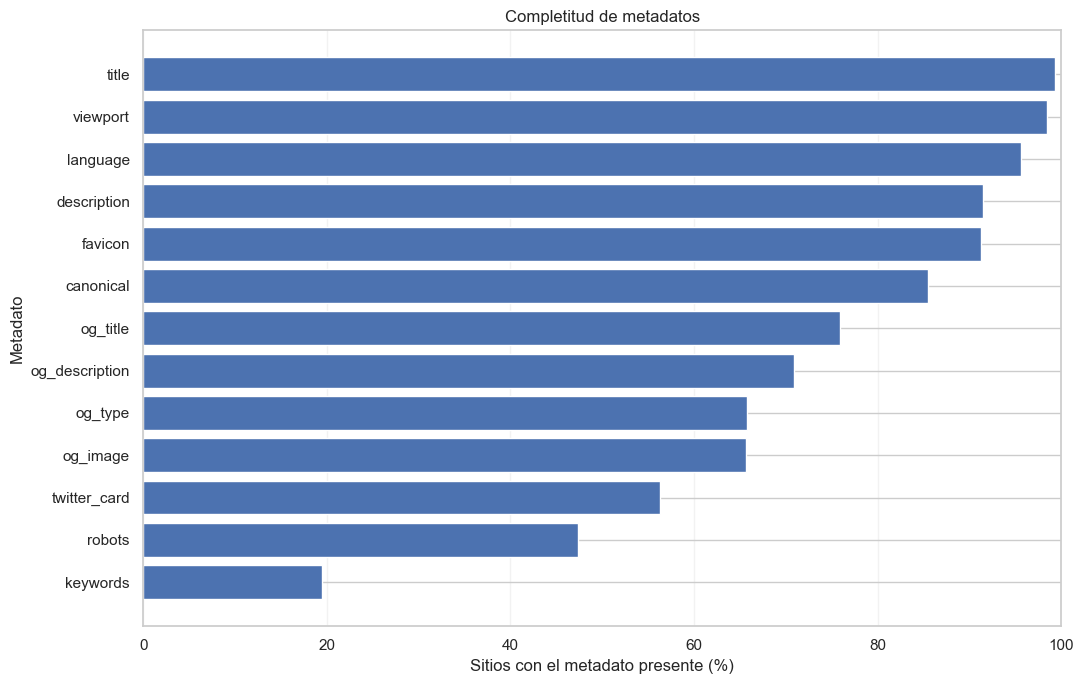

,field,n,mean_chars,median_chars,std_chars,min_chars,max_chars,p25_chars,p75_chars,mean_words
0,title,901,52.37,54.0,21.29,3,226,41.00,63.0,7.41
1,description,830,149.77,148.0,53.38,4,513,130.00,161.0,23.02
2,keywords,177,160.54,122.0,197.87,5,2042,58.00,200.0,22.22
3,og_title,688,45.97,49.5,23.15,3,240,29.75,61.0,6.61
4,og_description,643,147.68,148.0,53.98,17,475,127.00,160.5,22.82


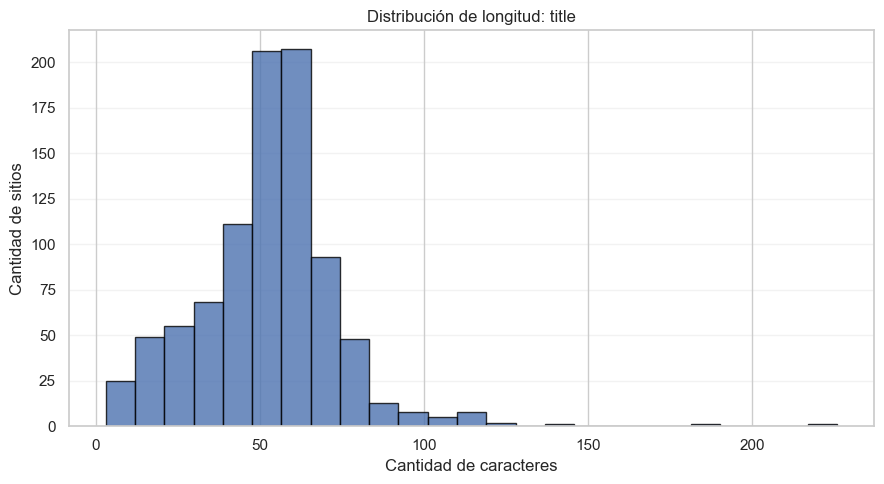

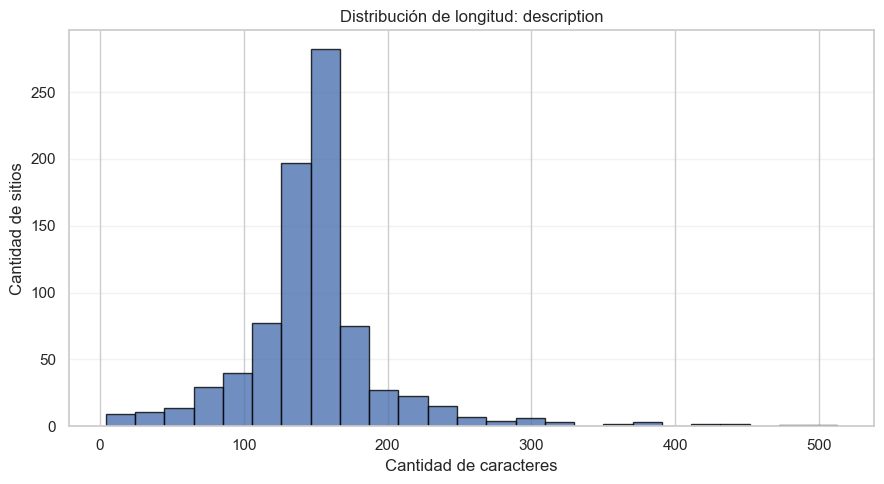

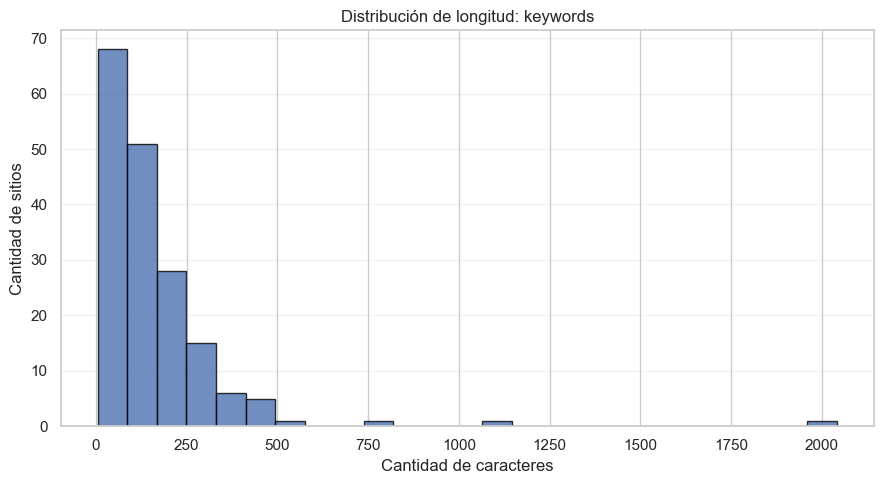

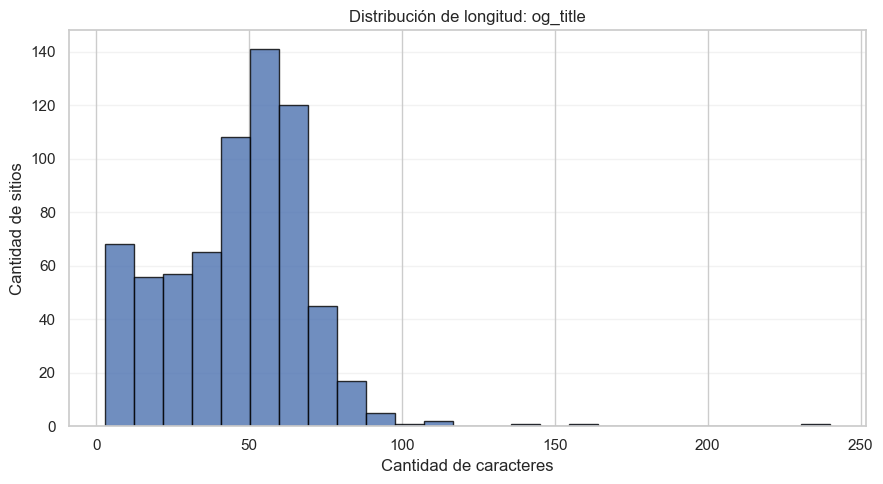

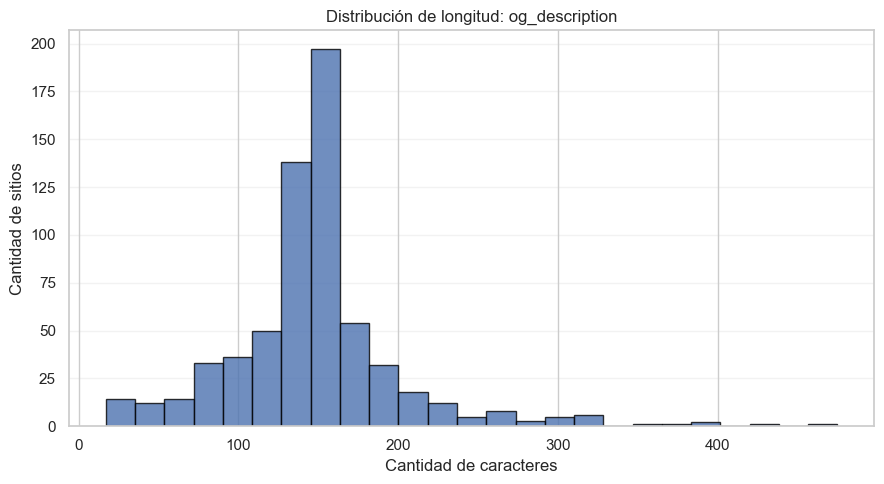

,domain_normalized,keywords,keywords_count
228,primeraplus.com.mx,"boletos de autobus, central del norte, central...",302
116,ugandairlines.com,"Book flight tickets, flights to Nairobi, fligh...",158
326,irishferries.com,ferry to france\ndover to calais ferry tickets...,131
289,peru.travel,"Peru, travel to Peru, official page of Peru, w...",79
797,tourismcambodia.com,"Cambodia, Cambodian, Cheap Hotels, Cheap Fligh...",71
147,oyorooms.com,"OYO Rooms, OYO Hotels, OYO Inn, Budget Hotels,...",70
154,reddoorz.com,"RedDoorz, RedDoorz Jakarta, RedDoorz indonesia...",60
334,fredolsen.es,"Fast Ferry canarias, barcos canarias, Fred Ols...",57
430,gha.com,"luxury resorts & hotels, luxury hotels & resor...",54
162,baolau.com,"flights, cheap flights, flights to hanoi, flig...",53


,keyword,frequency
0,de,82
1,to,77
2,hotels,65
3,ferry,64
4,flights,61
5,travel,53
6,airport,50
7,cheap,49
8,flight,43
9,booking,40


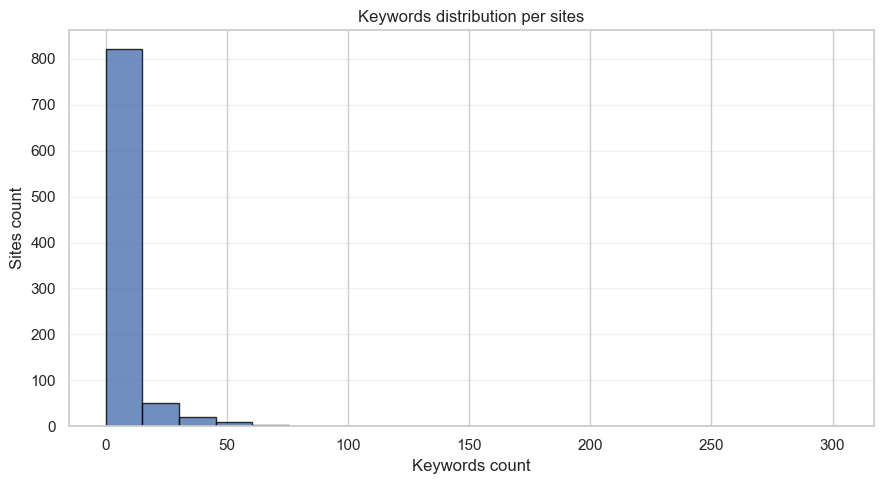

,metric,count,percentage
0,og_title,688,75.85
1,og_description,643,70.89
2,og_image,596,65.71
3,og_type,597,65.82
4,twitter_card,511,56.34
5,og_complete,458,50.50


,og_type,frequency
0,website,535
1,article,47
2,place,1
3,site root,1
4,uttarakhand tourism development board,1
5,city,1
6,country,1
7,business.business,1
8,touristdestination,1
9,homepage,1


,twitter_card,frequency
0,summary_large_image,375
1,summary,127
2,app,2
3,application,1
4,europcar,1
5,https://images.railyatri.in/ry_images_prod/rai...,1
6,https://images.ireland.com/media/images/sligo/...,1
7,product,1
8,website,1
9,uttarakhand tourism development board,1


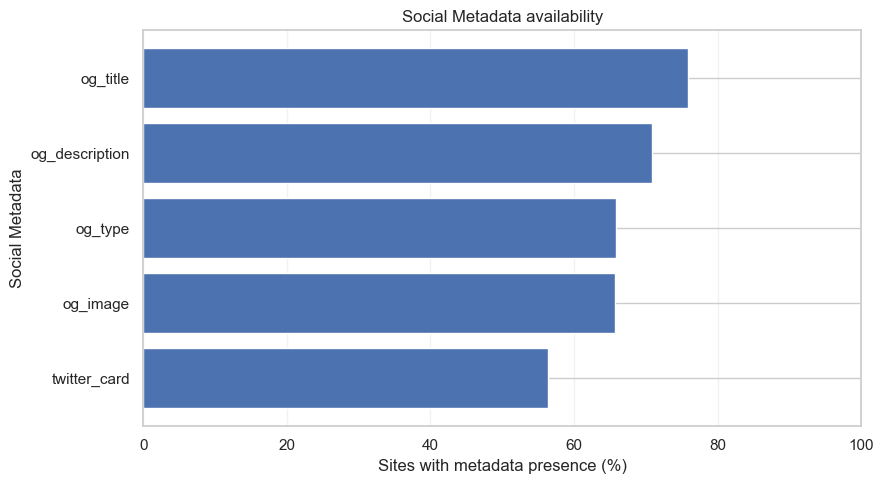

,comparison,valid_pairs,mean_similarity,median_similarity
0,title_vs_og_title,675,0.839,1.0
1,description_vs_og_description,618,0.913,1.0


,metric,count,percentage
0,favicon_present,828,91.29
1,favicon_external,210,23.15
2,canonical_present,775,85.45
3,canonical_external,65,7.17


,extension,frequency
0,png,385
1,ico,365
2,unknown,93
3,svg,40
4,jpg,9
5,webp,9
6,ico/a24318ac-7ec0-3c0f-581d-930009528883,1
7,ico/bb939f90-0a09-ff99-0a50-bdc706dd0ddd,1
8,ico/39873259-1664-f361-86a2-9f79a1cdc645,1
9,aspx,1


,viewport_class,frequency,percentage
0,device_width,883,97.35
1,missing,14,1.54
2,custom_width,9,0.99
3,other,1,0.11


,directive,frequency,percentage
0,noindex,5,0.55
1,nofollow,2,0.22
2,index,351,38.70
3,follow,339,37.38
4,noarchive,1,0.11
5,nosnippet,0,0.00
6,noimageindex,0,0.00


,robots_status,frequency
0,available,824
1,not_found,42
2,unavailable,41


,metric,count,percentage
0,json_ld_present,907,100.0
1,json_ld_missing,0,0.0
2,json_ld_with_detected_type,0,0.0


,schema_type,frequency


,domain_normalized,basic_metadata_score,social_metadata_score,metadata_total_score,metadata_total_possible,metadata_completeness_pct
0,agoda.com,6,5,11,11,100.0
805,choosechicago.com,6,5,11,11,100.0
238,europapark.de,6,5,11,11,100.0
634,outwardbound.org,6,5,11,11,100.0
747,iamsterdam.com,6,5,11,11,100.0
430,gha.com,6,5,11,11,100.0
630,alpineascents.com,6,5,11,11,100.0
750,visitoslo.com,6,5,11,11,100.0
751,myhelsinki.fi,6,5,11,11,100.0
227,etn.com.mx,6,5,11,11,100.0


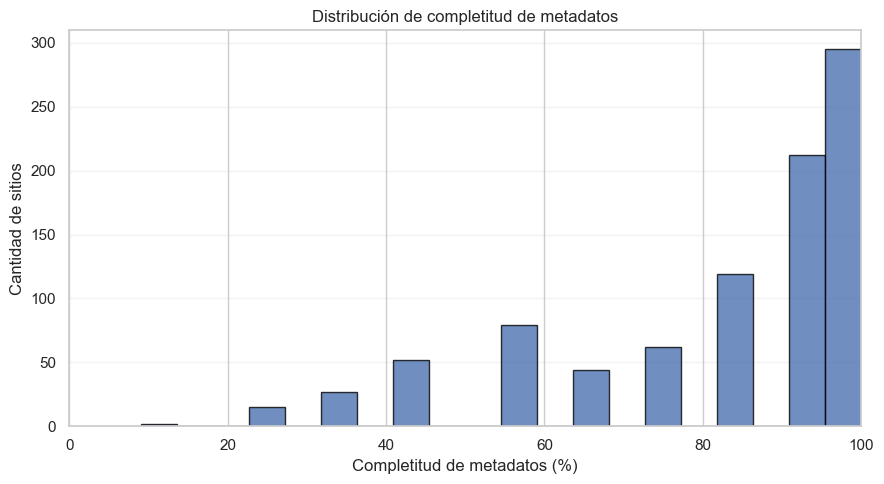

Result saved in: D:\chapa.com\analisis-front\analysis\metadata


In [14]:
INPUT = Path("analysis/quality/valid_candidates.csv")
OUTPUT = Path("analysis/metadata")

OUTPUT.mkdir(parents=True, exist_ok=True)
(OUTPUT / "tables").mkdir(exist_ok=True)
(OUTPUT / "plots").mkdir(exist_ok=True)

if not INPUT.exists():
    raise FileNotFoundError(f"No se encontró el archivo: {INPUT}")

df = pd.read_csv(INPUT)

print(f"Dataset cargado: {len(df)} registros")
print(f"Columnas disponibles: {len(df.columns)}")

# Helpers

def is_missing(value):
    """Detect missing values without failling."""
    if value is None:
        return True

    if isinstance(value, (list, dict, tuple, set)):
        return len(value) == 0

    try:
        return bool(pd.isna(value))
    except (TypeError, ValueError):
        return False


def clean_text(value):
    """Normalize value to text."""
    if is_missing(value):
        return ""

    if isinstance(value, (dict, list)):
        return json.dumps(value, ensure_ascii=False)

    return str(value).strip()


def parse_serialized(value):
    """
    Json convert.
    """
    if is_missing(value):
        return None

    if isinstance(value, (dict, list, tuple)):
        return value

    if not isinstance(value, str):
        return value

    value = value.strip()

    if not value:
        return None

    for parser in (json.loads, ast.literal_eval):
        try:
            return parser(value)
        except (ValueError, SyntaxError, TypeError, json.JSONDecodeError):
            pass

    return value


def normalize_text(value):
    """Normalization to text comparations."""
    text = clean_text(value).lower()
    text = unicodedata.normalize("NFKD", text)
    text = "".join(c for c in text if not unicodedata.combining(c))
    text = re.sub(r"[^a-z0-9áéíóúüñ]+", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def word_count(value):
    text = clean_text(value)
    return len(re.findall(r"\b[\wáéíóúüñÁÉÍÓÚÜÑ-]+\b", text))


def get_domain(value):
    """Extracr url."""
    value = clean_text(value)

    if not value:
        return ""

    if not re.match(r"^[a-zA-Z][a-zA-Z0-9+.-]*://", value):
        value = "https://" + value.lstrip("/")

    try:
        return urlparse(value).netloc.lower().split(":")[0].removeprefix("www.")
    except Exception:
        return ""


def has_value(value):
    return not is_missing(value) and clean_text(value) != ""


def extract_tokens(value):
    """Extract tokens."""
    text = clean_text(value)

    if not text:
        return []

    return [
        token.strip().lower()
        for token in re.split(r"[,;\s]+", text)
        if token.strip()
    ]


def flatten_dict_keys(data, prefix=""):
    """Get json keys."""
    keys = []

    if isinstance(data, dict):
        for key, value in data.items():
            full_key = f"{prefix}.{key}" if prefix else str(key)
            keys.append(full_key)
            keys.extend(flatten_dict_keys(value, full_key))

    elif isinstance(data, list):
        for item in data:
            keys.extend(flatten_dict_keys(item, prefix))

    return keys


def extract_schema_types(value):
    """get Json-LD @type"""
    parsed = parse_serialized(value)
    types = []

    def walk(node):
        if isinstance(node, dict):
            schema_type = node.get("@type")

            if isinstance(schema_type, str):
                types.append(schema_type)

            elif isinstance(schema_type, list):
                types.extend(str(item) for item in schema_type)

            for child in node.values():
                walk(child)

        elif isinstance(node, list):
            for child in node:
                walk(child)

    walk(parsed)
    return sorted(set(types))

# Variables

metadata_columns = [
    "original_url",
    "final_url",
    "domain",
    "title",
    "description",
    "keywords",
    "language",
    "canonical",
    "robots",
    "og_title",
    "og_description",
    "og_image",
    "og_type",
    "twitter_card",
    "favicon",
    "viewport",
    "robots_status",
    "json_ld",
    "json_ld_parsed",
]

meta = df.copy()

for column in metadata_columns:
    if column not in meta.columns:
        meta[column] = None

meta = meta[metadata_columns].copy()

# Normalization
text_columns = [
    "title",
    "description",
    "keywords",
    "language",
    "canonical",
    "robots",
    "og_title",
    "og_description",
    "og_image",
    "og_type",
    "twitter_card",
    "favicon",
    "viewport",
    "robots_status",
]

for column in text_columns:
    meta[column] = meta[column].apply(clean_text)

# Normalized domain
meta["domain_normalized"] = meta.apply(
    lambda row: (
        clean_text(row["domain"])
        or get_domain(row["final_url"])
        or get_domain(row["original_url"])
    ).lower().removeprefix("www."),
    axis=1
)

print("Variables setted.")

# Metada presence test

presence_fields = [
    "title",
    "description",
    "keywords",
    "language",
    "canonical",
    "robots",
    "og_title",
    "og_description",
    "og_image",
    "og_type",
    "twitter_card",
    "favicon",
    "viewport",
]

for column in presence_fields:
    meta[f"has_{column}"] = meta[column].apply(has_value)

presence_summary = pd.DataFrame({
    "field": presence_fields,
    "present_count": [
        meta[f"has_{column}"].sum()
        for column in presence_fields
    ],
    "missing_count": [
        (~meta[f"has_{column}"]).sum()
        for column in presence_fields
    ],
})

presence_summary["present_pct"] = (
    presence_summary["present_count"] / len(meta) * 100
).round(2)

presence_summary["missing_pct"] = (
    100 - presence_summary["present_pct"]
).round(2)

presence_summary = presence_summary.sort_values(
    "present_pct",
    ascending=False
)

presence_summary.to_csv(
    OUTPUT / "tables" / "metadata_presence.csv",
    index=False
)

display(presence_summary)

plot_data = presence_summary.sort_values("present_pct")

plt.figure(figsize=(11, 7))

plt.barh(
    plot_data["field"],
    plot_data["present_pct"]
)

plt.xlabel("Sitios con el metadato presente (%)")
plt.ylabel("Metadato")
plt.title("Completitud de metadatos")

plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT / "plots" / "metadata_presence.png",
    dpi=160
)

plt.show()

# Length analysis

length_fields = [
    "title",
    "description",
    "keywords",
    "og_title",
    "og_description",
]

for column in length_fields:
    meta[f"{column}_chars"] = meta[column].str.len()
    meta[f"{column}_words"] = meta[column].apply(word_count)

length_summary = []

for column in length_fields:
    values = meta.loc[
        meta[column].apply(has_value),
        f"{column}_chars"
    ].dropna()

    if values.empty:
        continue

    length_summary.append({
        "field": column,
        "n": len(values),
        "mean_chars": values.mean(),
        "median_chars": values.median(),
        "std_chars": values.std(),
        "min_chars": values.min(),
        "max_chars": values.max(),
        "p25_chars": values.quantile(0.25),
        "p75_chars": values.quantile(0.75),
        "mean_words": meta.loc[
            values.index,
            f"{column}_words"
        ].mean(),
    })

length_summary = pd.DataFrame(length_summary).round(2)

length_summary.to_csv(
    OUTPUT / "tables" / "metadata_length_summary.csv",
    index=False
)

display(length_summary)

# Length Distribution check

for column in length_fields:
    values = meta.loc[
        meta[column].apply(has_value),
        f"{column}_chars"
    ].dropna()

    if values.empty:
        continue

    plt.figure(figsize=(9, 5))

    plt.hist(
        values,
        bins=25,
        edgecolor="black",
        alpha=0.8
    )

    plt.xlabel("Cantidad de caracteres")
    plt.ylabel("Cantidad de sitios")
    plt.title(f"Distribución de longitud: {column}")

    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        OUTPUT / "plots" / f"length_{column}.png",
        dpi=160
    )

    plt.show()

# Keywords

meta["keywords_parsed"] = meta["keywords"].apply(extract_tokens)
meta["keywords_count"] = meta["keywords_parsed"].apply(len)

keyword_summary = meta[[
    "domain_normalized",
    "keywords",
    "keywords_count"
]].copy()

keyword_summary.to_csv(
    OUTPUT / "tables" / "keywords_by_site.csv",
    index=False
)

all_keywords = [
    keyword
    for keywords in meta["keywords_parsed"]
    for keyword in keywords
]

keyword_counter = Counter(all_keywords)

keywords_frequency = pd.DataFrame(
    keyword_counter.most_common(),
    columns=["keyword", "frequency"]
)

keywords_frequency.to_csv(
    OUTPUT / "tables" / "keywords_frequency.csv",
    index=False
)

display(keyword_summary.sort_values(
    "keywords_count",
    ascending=False
).head(20))

display(keywords_frequency.head(30))

# Keywords distribution

values = meta["keywords_count"]

plt.figure(figsize=(9, 5))

plt.hist(
    values,
    bins=20,
    edgecolor="black",
    alpha=0.8
)

plt.xlabel("Keywords count")
plt.ylabel("Sites count")
plt.title("Keywords distribution per sites")

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT / "plots" / "keywords_count_distribution.png",
    dpi=160
)

plt.show()

# Open Graph and Twitter cards

social_fields = [
    "og_title",
    "og_description",
    "og_image",
    "og_type",
    "twitter_card",
]

meta["og_complete"] = meta[
    ["og_title", "og_description", "og_image", "og_type"]
].apply(
    lambda row: all(has_value(value) for value in row),
    axis=1
)

meta["og_partial_count"] = meta[
    ["og_title", "og_description", "og_image", "og_type"]
].apply(
    lambda row: sum(has_value(value) for value in row),
    axis=1
)

meta["social_metadata_count"] = meta[
    social_fields
].apply(
    lambda row: sum(has_value(value) for value in row),
    axis=1
)

social_summary = pd.DataFrame({
    "metric": [
        "og_title",
        "og_description",
        "og_image",
        "og_type",
        "twitter_card",
        "og_complete",
    ],
    "count": [
        meta[f"has_{field}"].sum()
        if f"has_{field}" in meta.columns
        else meta[field].apply(has_value).sum()
        for field in social_fields
    ] + [
        meta["og_complete"].sum()
    ]
})

social_summary["percentage"] = (
    social_summary["count"] / len(meta) * 100
).round(2)

social_summary.to_csv(
    OUTPUT / "tables" / "social_metadata_summary.csv",
    index=False
)

display(social_summary)

# Types

og_type_frequency = (
    meta["og_type"]
    .replace("", np.nan)
    .dropna()
    .str.lower()
    .value_counts()
    .rename_axis("og_type")
    .reset_index(name="frequency")
)

og_type_frequency.to_csv(
    OUTPUT / "tables" / "og_type_frequency.csv",
    index=False
)

display(og_type_frequency)

# Types (Twitter)

twitter_frequency = (
    meta["twitter_card"]
    .replace("", np.nan)
    .dropna()
    .str.lower()
    .value_counts()
    .rename_axis("twitter_card")
    .reset_index(name="frequency")
)

twitter_frequency.to_csv(
    OUTPUT / "tables" / "twitter_card_frequency.csv",
    index=False
)

display(twitter_frequency)

# Visualization

social_plot = social_summary[
    social_summary["metric"] != "og_complete"
].sort_values("percentage")

plt.figure(figsize=(9, 5))

plt.barh(
    social_plot["metric"],
    social_plot["percentage"]
)

plt.xlabel("Sites with metadata presence (%)")
plt.ylabel("Social Metadata")
plt.title("Social Metadata availability")

plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT / "plots" / "social_metadata_presence.png",
    dpi=160
)

plt.show()

# Consistence

def jaccard_similarity(text_a, text_b):
    a = set(normalize_text(text_a).split())
    b = set(normalize_text(text_b).split())

    if not a or not b:
        return np.nan

    union = a | b

    if not union:
        return np.nan

    return len(a & b) / len(union)


meta["title_og_similarity"] = meta.apply(
    lambda row: jaccard_similarity(
        row["title"],
        row["og_title"]
    ),
    axis=1
)

meta["description_og_similarity"] = meta.apply(
    lambda row: jaccard_similarity(
        row["description"],
        row["og_description"]
    ),
    axis=1
)

consistency_columns = [
    "domain_normalized",
    "title",
    "og_title",
    "title_og_similarity",
    "description",
    "og_description",
    "description_og_similarity",
]

consistency = meta[consistency_columns].copy()

consistency.to_csv(
    OUTPUT / "tables" / "metadata_consistency.csv",
    index=False
)

consistency_summary = pd.DataFrame({
    "comparison": [
        "title_vs_og_title",
        "description_vs_og_description",
    ],
    "valid_pairs": [
        meta["title_og_similarity"].notna().sum(),
        meta["description_og_similarity"].notna().sum(),
    ],
    "mean_similarity": [
        meta["title_og_similarity"].mean(),
        meta["description_og_similarity"].mean(),
    ],
    "median_similarity": [
        meta["title_og_similarity"].median(),
        meta["description_og_similarity"].median(),
    ],
}).round(3)

consistency_summary.to_csv(
    OUTPUT / "tables" / "metadata_consistency_summary.csv",
    index=False
)

display(consistency_summary)

# Favicon and canonical

meta["favicon_domain"] = meta["favicon"].apply(get_domain)
meta["canonical_domain"] = meta["canonical"].apply(get_domain)

meta["favicon_is_external"] = meta.apply(
    lambda row: (
        bool(row["favicon_domain"])
        and bool(row["domain_normalized"])
        and row["favicon_domain"] != row["domain_normalized"]
    ),
    axis=1
)

meta["canonical_is_external"] = meta.apply(
    lambda row: (
        bool(row["canonical_domain"])
        and bool(row["domain_normalized"])
        and row["canonical_domain"] != row["domain_normalized"]
    ),
    axis=1
)

meta["favicon_extension"] = meta["favicon"].apply(
    lambda value: (
        urlparse(value).path.rsplit(".", 1)[-1].lower()
        if has_value(value) and "." in urlparse(value).path
        else "unknown"
    )
)

favicon_extensions = (
    meta["favicon_extension"]
    .value_counts()
    .rename_axis("extension")
    .reset_index(name="frequency")
)

favicon_extensions.to_csv(
    OUTPUT / "tables" / "favicon_extensions.csv",
    index=False
)

url_identity_summary = pd.DataFrame({
    "metric": [
        "favicon_present",
        "favicon_external",
        "canonical_present",
        "canonical_external",
    ],
    "count": [
        meta["favicon"].apply(has_value).sum(),
        meta["favicon_is_external"].sum(),
        meta["canonical"].apply(has_value).sum(),
        meta["canonical_is_external"].sum(),
    ],
})

url_identity_summary["percentage"] = (
    url_identity_summary["count"] / len(meta) * 100
).round(2)

url_identity_summary.to_csv(
    OUTPUT / "tables" / "favicon_canonical_summary.csv",
    index=False
)

display(url_identity_summary)
display(favicon_extensions)

# Viewport

def classify_viewport(value):
    text = clean_text(value).lower()

    if not text:
        return "missing"

    if "width=device-width" in text:
        return "device_width"

    if "width" in text:
        return "custom_width"

    return "other"


meta["viewport_class"] = meta["viewport"].apply(
    classify_viewport
)

viewport_summary = (
    meta["viewport_class"]
    .value_counts()
    .rename_axis("viewport_class")
    .reset_index(name="frequency")
)

viewport_summary["percentage"] = (
    viewport_summary["frequency"] / len(meta) * 100
).round(2)

viewport_summary.to_csv(
    OUTPUT / "tables" / "viewport_summary.csv",
    index=False
)

display(viewport_summary)

# Robots and index

def parse_robots_directives(value):
    text = clean_text(value).lower()

    if not text:
        return []

    return [
        token.strip()
        for token in re.split(r"[,;\s]+", text)
        if token.strip()
    ]


meta["robots_directives"] = meta["robots"].apply(
    parse_robots_directives
)

robots_directive_names = [
    "noindex",
    "nofollow",
    "index",
    "follow",
    "noarchive",
    "nosnippet",
    "noimageindex",
]

for directive in robots_directive_names:
    meta[f"robots_{directive}"] = meta[
        "robots_directives"
    ].apply(
        lambda directives: directive in directives
    )

robots_summary = pd.DataFrame({
    "directive": robots_directive_names,
    "frequency": [
        meta[f"robots_{directive}"].sum()
        for directive in robots_directive_names
    ],
})

robots_summary["percentage"] = (
    robots_summary["frequency"] / len(meta) * 100
).round(2)

robots_status_summary = (
    meta["robots_status"]
    .replace("", np.nan)
    .dropna()
    .value_counts()
    .rename_axis("robots_status")
    .reset_index(name="frequency")
)

robots_summary.to_csv(
    OUTPUT / "tables" / "robots_directives_summary.csv",
    index=False
)

robots_status_summary.to_csv(
    OUTPUT / "tables" / "robots_status_summary.csv",
    index=False
)

display(robots_summary)
display(robots_status_summary)

# JSON-LD

json_ld_column = (
    "json_ld_parsed"
    if "json_ld_parsed" in meta.columns
    else "json_ld"
)

meta["json_ld_types"] = meta[json_ld_column].apply(
    extract_schema_types
)

meta["json_ld_present"] = meta[
    json_ld_column
].apply(
    lambda value: parse_serialized(value) is not None
)

meta["json_ld_type_count"] = meta[
    "json_ld_types"
].apply(len)

jsonld_by_site = meta[[
    "domain_normalized",
    "json_ld_present",
    "json_ld_type_count",
    "json_ld_types",
]].copy()

jsonld_by_site["json_ld_types"] = jsonld_by_site[
    "json_ld_types"
].apply(
    lambda values: " | ".join(values)
)

jsonld_by_site.to_csv(
    OUTPUT / "tables" / "jsonld_by_site.csv",
    index=False
)

all_schema_types = [
    schema_type
    for types in meta["json_ld_types"]
    for schema_type in types
]

schema_counter = Counter(all_schema_types)

schema_summary = pd.DataFrame(
    schema_counter.most_common(),
    columns=["schema_type", "frequency"]
)

schema_summary.to_csv(
    OUTPUT / "tables" / "jsonld_schema_types.csv",
    index=False
)

jsonld_presence_summary = pd.DataFrame({
    "metric": [
        "json_ld_present",
        "json_ld_missing",
        "json_ld_with_detected_type",
    ],
    "count": [
        meta["json_ld_present"].sum(),
        (~meta["json_ld_present"]).sum(),
        (meta["json_ld_type_count"] > 0).sum(),
    ],
})

jsonld_presence_summary["percentage"] = (
    jsonld_presence_summary["count"] / len(meta) * 100
).round(2)

jsonld_presence_summary.to_csv(
    OUTPUT / "tables" / "jsonld_presence_summary.csv",
    index=False
)

display(jsonld_presence_summary)
display(schema_summary.head(40))

# Descriptive index

basic_fields = [
    "title",
    "description",
    "language",
    "canonical",
    "favicon",
    "viewport",
]

social_fields_for_score = [
    "og_title",
    "og_description",
    "og_image",
    "og_type",
    "twitter_card",
]

for field in basic_fields + social_fields_for_score:
    meta[f"score_{field}"] = meta[field].apply(has_value).astype(int)

meta["basic_metadata_score"] = meta[
    [f"score_{field}" for field in basic_fields]
].sum(axis=1)

meta["social_metadata_score"] = meta[
    [f"score_{field}" for field in social_fields_for_score]
].sum(axis=1)

meta["metadata_total_score"] = (
    meta["basic_metadata_score"]
    + meta["social_metadata_score"]
)

meta["metadata_total_possible"] = (
    len(basic_fields) + len(social_fields_for_score)
)

meta["metadata_completeness_pct"] = (
    meta["metadata_total_score"]
    / meta["metadata_total_possible"]
    * 100
).round(2)

metadata_scores = meta[[
    "domain_normalized",
    "basic_metadata_score",
    "social_metadata_score",
    "metadata_total_score",
    "metadata_total_possible",
    "metadata_completeness_pct",
]].copy()

metadata_scores = metadata_scores.sort_values(
    "metadata_completeness_pct",
    ascending=False
)

metadata_scores.to_csv(
    OUTPUT / "tables" / "metadata_completeness_by_site.csv",
    index=False
)

display(metadata_scores.head(30))

# Index distribution

plt.figure(figsize=(9, 5))

plt.hist(
    meta["metadata_completeness_pct"].dropna(),
    bins=20,
    edgecolor="black",
    alpha=0.8
)

plt.xlabel("Completitud de metadatos (%)")
plt.ylabel("Cantidad de sitios")
plt.title("Distribución de completitud de metadatos")

plt.xlim(0, 100)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT / "plots" / "metadata_completeness_distribution.png",
    dpi=160
)

plt.show()

# Consolidate site table

site_metadata = meta[[
    "domain_normalized",
    "title",
    "description",
    "language",
    "canonical",
    "favicon",
    "viewport",
    "og_title",
    "og_description",
    "og_image",
    "og_type",
    "twitter_card",
    "robots",
    "robots_status",
    "keywords_count",
    "title_chars",
    "description_chars",
    "og_title_chars",
    "og_description_chars",
    "title_og_similarity",
    "description_og_similarity",
    "basic_metadata_score",
    "social_metadata_score",
    "metadata_total_score",
    "metadata_completeness_pct",
    "json_ld_present",
    "json_ld_type_count",
]].copy()

site_metadata.to_csv(
    OUTPUT / "tables" / "metadata_by_site.csv",
    index=False
)

print(f"Result saved in: {OUTPUT.resolve()}")




Navigation Structure

Registros cargados: 907
Columnas disponibles: 70
Dataset ready.


,row_index,domain,page_url,position,level,heading_text,word_count,has_text
0,0,agoda.com,https://www.agoda.com/,0,None,,0,False
1,1,airbnb.com,https://www.airbnb.com/,0,None,,0,False
2,2,ryanair.com,https://www.ryanair.com/ie/en,0,None,,0,False
3,3,flightradar24.com,https://www.flightradar24.com/,0,None,,0,False
4,4,flightaware.com,https://www.flightaware.com/,0,None,,0,False
5,5,skyscanner.com,https://www.skyscanner.com/,0,None,,0,False
6,6,bahn.de,https://www.bahn.de/,0,None,,0,False
7,7,traveloka.com,https://www.traveloka.com/en-en,0,None,,0,False
8,8,kayak.com,https://www.kayak.com/,0,None,,0,False
9,9,thetrainline.com,https://www.thetrainline.com/,0,None,,0,False


,row_index,domain,page_url,heading_count,headings_with_text,headings_without_text,has_h1,h1_count,multiple_h1,max_heading_level,h2_count,h3_count,h4_count,h5_count,h6_count
0,0,agoda.com,https://www.agoda.com/,1,0,1,False,0,False,NaN,0,0,0,0,0
1,1,airbnb.com,https://www.airbnb.com/,1,0,1,False,0,False,NaN,0,0,0,0,0
2,2,ryanair.com,https://www.ryanair.com/ie/en,1,0,1,False,0,False,NaN,0,0,0,0,0
3,3,flightradar24.com,https://www.flightradar24.com/,1,0,1,False,0,False,NaN,0,0,0,0,0
4,4,flightaware.com,https://www.flightaware.com/,1,0,1,False,0,False,NaN,0,0,0,0,0
5,5,skyscanner.com,https://www.skyscanner.com/,1,0,1,False,0,False,NaN,0,0,0,0,0
6,6,bahn.de,https://www.bahn.de/,1,0,1,False,0,False,NaN,0,0,0,0,0
7,7,traveloka.com,https://www.traveloka.com/en-en,1,0,1,False,0,False,NaN,0,0,0,0,0
8,8,kayak.com,https://www.kayak.com/,1,0,1,False,0,False,NaN,0,0,0,0,0
9,9,thetrainline.com,https://www.thetrainline.com/,1,0,1,False,0,False,NaN,0,0,0,0,0


,heading_level,frequency,percentage
0,1,0,0.0
1,2,0,0.0
2,3,0,0.0
3,4,0,0.0
4,5,0,0.0
5,6,0,0.0


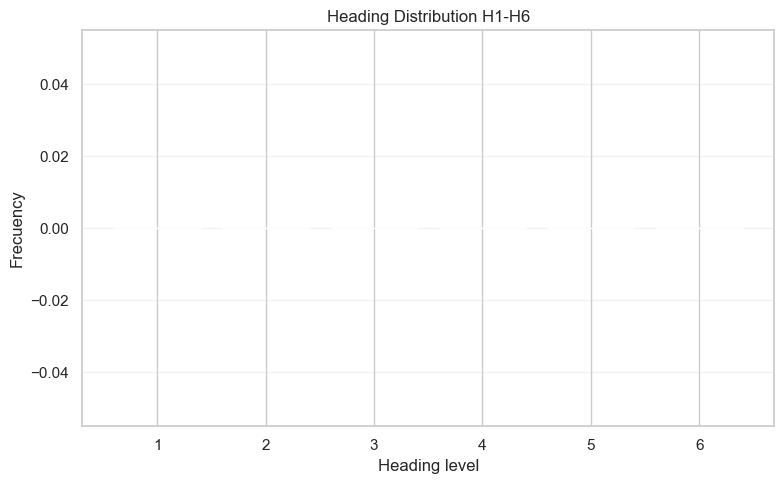

,row_index,domain,heading_sequence,heading_transitions,downward_jumps,upward_jumps,same_level_transitions
0,0,agoda.com,,0,0,0,0
1,1,airbnb.com,,0,0,0,0
2,2,ryanair.com,,0,0,0,0
3,3,flightradar24.com,,0,0,0,0
4,4,flightaware.com,,0,0,0,0
5,5,skyscanner.com,,0,0,0,0
6,6,bahn.de,,0,0,0,0
7,7,traveloka.com,,0,0,0,0
8,8,kayak.com,,0,0,0,0
9,9,thetrainline.com,,0,0,0,0


,from_level,to_level,frequency


,row_index,domain,page_url,position,anchor_text,href,resolved_url,title,rel,link_type,anchor_word_count,has_anchor_text
0,0,agoda.com,https://www.agoda.com/,0,,Hotels & Homes,https://www.agoda.com/Hotels & Homes,,,internal,0,False
1,0,agoda.com,https://www.agoda.com/,1,,Things to do,https://www.agoda.com/Things to do,,,internal,0,False
2,0,agoda.com,https://www.agoda.com/,2,,Coupons & Deals,https://www.agoda.com/Coupons & Deals,,,internal,0,False
3,0,agoda.com,https://www.agoda.com/,3,,Apartments,https://www.agoda.com/Apartments,,,internal,0,False
4,0,agoda.com,https://www.agoda.com/,4,,eSIM,https://www.agoda.com/eSIM,,,internal,0,False
5,0,agoda.com,https://www.agoda.com/,5,,Travel Guides,https://www.agoda.com/Travel Guides,,,internal,0,False
6,0,agoda.com,https://www.agoda.com/,6,,Travel Itineraries,https://www.agoda.com/Travel Itineraries,,,internal,0,False
7,2,ryanair.com,https://www.ryanair.com/ie/en,0,,Help centre,https://www.ryanair.com/ie/Help centre,,,internal,0,False
8,2,ryanair.com,https://www.ryanair.com/ie/en,1,,Flight info,https://www.ryanair.com/ie/Flight info,,,internal,0,False
9,2,ryanair.com,https://www.ryanair.com/ie/en,2,,Say YES! to Zadar,https://www.ryanair.com/ie/Say YES! to Zadar,,,internal,0,False


,row_index,domain,page_url,nav_link_count,internal_links,external_links,relative_links,anchor_links,special_links,missing_href,links_with_text,links_without_text,unique_destinations
0,0,agoda.com,https://www.agoda.com/,7,7,0,0,0,0,0,0,7,7
1,1,airbnb.com,https://www.airbnb.com/,0,0,0,0,0,0,0,0,0,0
2,2,ryanair.com,https://www.ryanair.com/ie/en,38,38,0,0,0,0,0,0,38,37
3,3,flightradar24.com,https://www.flightradar24.com/,13,13,0,0,0,0,0,0,13,13
4,4,flightaware.com,https://www.flightaware.com/,0,0,0,0,0,0,0,0,0,0
5,5,skyscanner.com,https://www.skyscanner.com/,1,1,0,0,0,0,0,0,1,1
6,6,bahn.de,https://www.bahn.de/,2,2,0,0,0,0,0,0,2,2
7,7,traveloka.com,https://www.traveloka.com/en-en,0,0,0,0,0,0,0,0,0,0
8,8,kayak.com,https://www.kayak.com/,1,1,0,0,0,0,0,0,1,1
9,9,thetrainline.com,https://www.thetrainline.com/,37,37,0,0,0,0,0,0,37,37


,anchor_text,frequency


,link_type,frequency,percentage
0,internal,20585,94.88
1,external,1100,5.07
2,missing,10,0.05


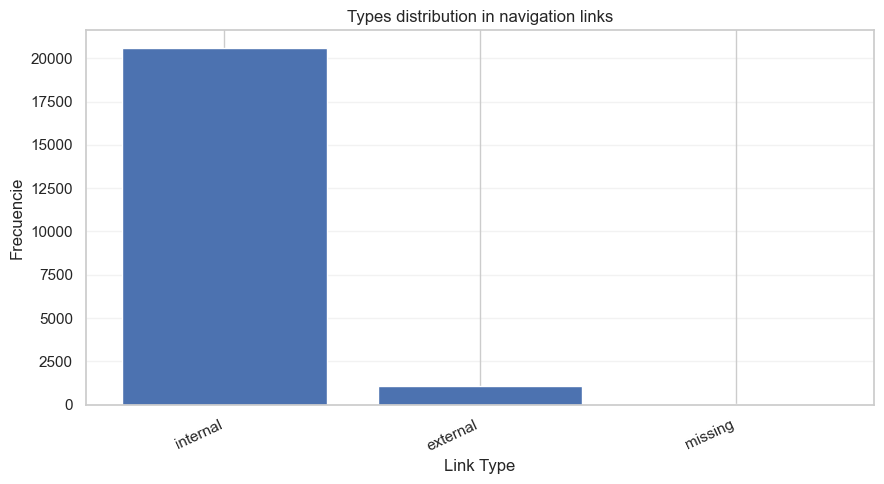

,row_index,domain,url,path,path_depth,path_segments,query_present,fragment_present,extension,path_segments_text
0,0,agoda.com,https://www.agoda.com/,/,0,[],False,False,,
1,1,airbnb.com,https://www.airbnb.com/,/,0,[],False,False,,
2,2,ryanair.com,https://www.ryanair.com/ie/en,/ie/en,2,"[ie, en]",False,False,,ie / en
3,3,flightradar24.com,https://www.flightradar24.com/,/,0,[],False,False,,
4,4,flightaware.com,https://www.flightaware.com/,/,0,[],False,False,,
5,5,skyscanner.com,https://www.skyscanner.com/,/,0,[],False,False,,
6,6,bahn.de,https://www.bahn.de/,/,0,[],False,False,,
7,7,traveloka.com,https://www.traveloka.com/en-en,/en-en,1,[en-en],False,False,,en-en
8,8,kayak.com,https://www.kayak.com/,/,0,[],False,False,,
9,9,thetrainline.com,https://www.thetrainline.com/,/,0,[],False,False,,


,path_depth,frequency,percentage
0,0,694,76.52
1,1,176,19.40
2,2,33,3.64
3,3,4,0.44


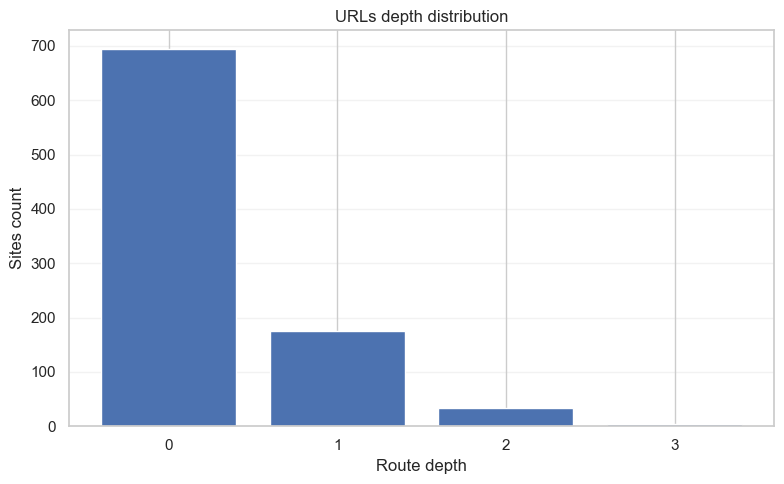

,segment,frequency
0,en,78
1,es,22
2,fr,9
3,en-us,8
4,de,8
5,home.html,6
6,home,6
7,ar,5
8,en-gb,4
9,index.php,3


,site_domain,base_url,body_text_length_metric,row_index,heading_count,h1_count,h2_count,h3_count,nav_link_count,internal_links,external_links,headings_per_1000_chars,nav_links_per_1000_chars,chars_per_heading
0,agoda.com,https://www.agoda.com/,1847.0,0,1,0,0,0,7,7,0,0.541419,3.789930,1847.0
1,airbnb.com,https://www.airbnb.com/,3589.0,1,1,0,0,0,0,0,0,0.278629,0.000000,3589.0
2,ryanair.com,https://www.ryanair.com/ie/en,2971.0,2,1,0,0,0,38,38,0,0.336587,12.790306,2971.0
3,flightradar24.com,https://www.flightradar24.com/,698.0,3,1,0,0,0,13,13,0,1.432665,18.624642,698.0
4,flightaware.com,https://www.flightaware.com/,1477.0,4,1,0,0,0,0,0,0,0.677048,0.000000,1477.0
5,skyscanner.com,https://www.skyscanner.com/,1855.0,5,1,0,0,0,1,1,0,0.539084,0.539084,1855.0
6,bahn.de,https://www.bahn.de/,2671.0,6,1,0,0,0,2,2,0,0.374392,0.748783,2671.0
7,traveloka.com,https://www.traveloka.com/en-en,6644.0,7,1,0,0,0,0,0,0,0.150512,0.000000,6644.0
8,kayak.com,https://www.kayak.com/,2511.0,8,1,0,0,0,1,1,0,0.398248,0.398248,2511.0
9,thetrainline.com,https://www.thetrainline.com/,3750.0,9,1,0,0,0,37,37,0,0.266667,9.866667,3750.0


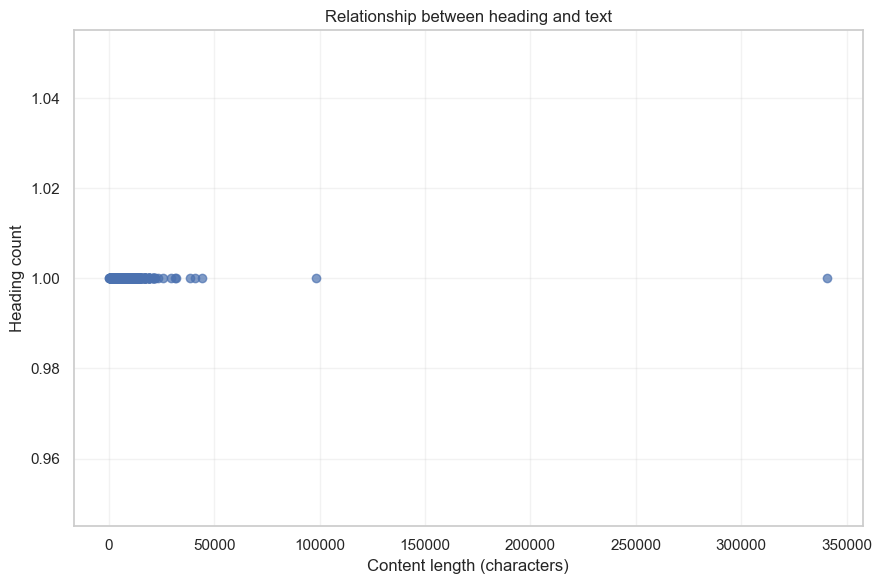

,metric,n,mean,median,std,min,p25,p75,max
0,heading_count,907,1.00,1.00,0.00,1.0,1.00,1.00,1.00
1,h1_count,907,0.00,0.00,0.00,0.0,0.00,0.00,0.00
2,h2_count,907,0.00,0.00,0.00,0.0,0.00,0.00,0.00
3,h3_count,907,0.00,0.00,0.00,0.0,0.00,0.00,0.00
4,nav_link_count,907,23.92,5.00,59.51,0.0,0.00,21.50,842.00
5,internal_links,907,22.70,4.00,58.88,0.0,0.00,20.00,842.00
6,external_links,907,1.21,0.00,10.85,0.0,0.00,0.00,251.00
7,path_depth,907,0.28,0.00,0.55,0.0,0.00,0.00,3.00
8,body_text_length_metric,907,6603.67,4944.00,12512.33,317.0,3040.50,7926.50,340717.00
9,headings_per_1000_chars,907,0.31,0.20,0.37,0.0,0.13,0.33,3.15


,site_domain,base_url,body_text_length_metric,row_index,heading_count,h1_count,h2_count,h3_count,nav_link_count,internal_links,...,headings_per_1000_chars,nav_links_per_1000_chars,chars_per_heading,path_depth,query_present,fragment_present,extension,heading_sequence,downward_jumps,upward_jumps
0,agoda.com,https://www.agoda.com/,1847.0,0,1,0,0,0,7,7,...,0.541419,3.789930,1847.0,0,False,False,,,0,0
1,airbnb.com,https://www.airbnb.com/,3589.0,1,1,0,0,0,0,0,...,0.278629,0.000000,3589.0,0,False,False,,,0,0
2,ryanair.com,https://www.ryanair.com/ie/en,2971.0,2,1,0,0,0,38,38,...,0.336587,12.790306,2971.0,2,False,False,,,0,0
3,flightradar24.com,https://www.flightradar24.com/,698.0,3,1,0,0,0,13,13,...,1.432665,18.624642,698.0,0,False,False,,,0,0
4,flightaware.com,https://www.flightaware.com/,1477.0,4,1,0,0,0,0,0,...,0.677048,0.000000,1477.0,0,False,False,,,0,0
5,skyscanner.com,https://www.skyscanner.com/,1855.0,5,1,0,0,0,1,1,...,0.539084,0.539084,1855.0,0,False,False,,,0,0
6,bahn.de,https://www.bahn.de/,2671.0,6,1,0,0,0,2,2,...,0.374392,0.748783,2671.0,0,False,False,,,0,0
7,traveloka.com,https://www.traveloka.com/en-en,6644.0,7,1,0,0,0,0,0,...,0.150512,0.000000,6644.0,1,False,False,,,0,0
8,kayak.com,https://www.kayak.com/,2511.0,8,1,0,0,0,1,1,...,0.398248,0.398248,2511.0,0,False,False,,,0,0
9,thetrainline.com,https://www.thetrainline.com/,3750.0,9,1,0,0,0,37,37,...,0.266667,9.866667,3750.0,0,False,False,,,0,0


Results saved in: D:\chapa.com\analisis-front\analysis\content_architecture


In [15]:
INPUT = Path("analysis/quality/valid_candidates.csv")
OUTPUT = Path("analysis/content_architecture")

OUTPUT.mkdir(parents=True, exist_ok=True)
(OUTPUT / "tables").mkdir(exist_ok=True)
(OUTPUT / "plots").mkdir(exist_ok=True)

if not INPUT.exists():
    raise FileNotFoundError(f"No se encontró el archivo: {INPUT}")

df = pd.read_csv(INPUT)

print(f"Registros cargados: {len(df)}")
print(f"Columnas disponibles: {len(df.columns)}")

# Helpers

def is_missing(value):
    if value is None:
        return True

    if isinstance(value, (list, dict, tuple, set)):
        return len(value) == 0

    try:
        return bool(pd.isna(value))
    except (TypeError, ValueError):
        return False


def clean_text(value):
    if is_missing(value):
        return ""

    if isinstance(value, (dict, list)):
        return json.dumps(value, ensure_ascii=False)

    return str(value).strip()


def parse_serialized(value):
    if is_missing(value):
        return None

    if isinstance(value, (dict, list, tuple)):
        return value

    if not isinstance(value, str):
        return value

    value = value.strip()

    if not value:
        return None

    for parser in (json.loads, ast.literal_eval):
        try:
            return parser(value)
        except (ValueError, SyntaxError, TypeError, json.JSONDecodeError):
            pass

    return value


def get_domain(value):
    value = clean_text(value)

    if not value:
        return ""

    if not re.match(r"^[a-zA-Z][a-zA-Z0-9+.-]*://", value):
        value = "https://" + value.lstrip("/")

    try:
        return urlparse(value).netloc.lower().split(":")[0].removeprefix("www.")
    except Exception:
        return ""


def normalize_domain(value):
    return clean_text(value).lower().removeprefix("www.").split(":")[0]


def normalize_whitespace(value):
    return re.sub(r"\s+", " ", clean_text(value)).strip()


def word_count(value):
    return len(re.findall(
        r"\b[\wáéíóúüñÁÉÍÓÚÜÑ-]+\b",
        clean_text(value)
    ))


def safe_int(value, default=0):
    try:
        return int(float(value))
    except (TypeError, ValueError):
        return default


def get_first(data, keys, default=None):
    """Return first available field in a dict"""
    if not isinstance(data, dict):
        return default

    for key in keys:
        if key in data and not is_missing(data[key]):
            return data[key]

    return default


def flatten_records(value):
    """
    Transform lists y diccionaries in a record list.
    The not serialized strings keeps as individual elements.
    """
    parsed = parse_serialized(value)

    if parsed is None:
        return []

    if isinstance(parsed, list):
        result = []

        for item in parsed:
            result.extend(flatten_records(item))

        return result

    if isinstance(parsed, dict):
        return [parsed]

    if isinstance(parsed, str):
        text = parsed.strip()

        if not text:
            return []

        return [text]

    return [parsed]


def normalize_heading_level(record):
    """Get the H1-H6 level of diferent representations."""
    if not isinstance(record, dict):
        return None

    raw = get_first(
        record,
        ["tag", "level", "heading", "element", "type"]
    )

    if raw is None:
        return None

    raw = str(raw).strip().lower()

    match = re.search(r"h([1-6])", raw)

    if match:
        return int(match.group(1))

    if raw in {"1", "2", "3", "4", "5", "6"}:
        return int(raw)

    return None


def extract_heading_text(record):
    if isinstance(record, str):
        return normalize_whitespace(record)

    if isinstance(record, dict):
        value = get_first(
            record,
            [
                "text",
                "title",
                "content",
                "inner_text",
                "innerText",
                "label",
                "value",
            ],
            default=""
        )

        return normalize_whitespace(value)

    return ""


def extract_link_data(record):
    """
    Normalize a link to:
    text, href, title, rel
    """
    if isinstance(record, str):
        return {
            "text": "",
            "href": record.strip(),
            "title": "",
            "rel": "",
        }

    if not isinstance(record, dict):
        return {
            "text": "",
            "href": "",
            "title": "",
            "rel": "",
        }

    return {
        "text": normalize_whitespace(
            get_first(
                record,
                ["text", "inner_text", "innerText", "label", "name"],
                default=""
            )
        ),
        "href": clean_text(
            get_first(
                record,
                ["href", "url", "link", "destination"],
                default=""
            )
        ),
        "title": clean_text(record.get("title")),
        "rel": clean_text(record.get("rel")),
    }


def resolve_link(href, base_url):
    href = clean_text(href)

    if not href:
        return ""

    try:
        return urljoin(base_url, href)
    except Exception:
        return href


def classify_link(href, site_domain):
    href = clean_text(href).strip().lower()

    if not href:
        return "missing"

    if href.startswith("#"):
        return "anchor"

    if href.startswith(("mailto:", "tel:", "javascript:")):
        return "special"

    if href.startswith(("data:", "blob:")):
        return "non_web"

    link_domain = get_domain(href)

    if not link_domain:
        return "relative"

    if link_domain == site_domain:
        return "internal"

    return "external"

# Setting the dataset

work = df.copy()

required_columns = [
    "original_url",
    "final_url",
    "domain",
    "domain_clean",
    "headings",
    "headings_parsed",
    "nav_links",
    "nav_links_parsed",
    "body_text_length",
    "body_text_length_num",
]

for column in required_columns:
    if column not in work.columns:
        work[column] = None

def select_parsed_column(data, parsed_column, raw_column):
    if parsed_column not in data.columns:
        return data[raw_column]

    if raw_column not in data.columns:
        return data[parsed_column]

    parsed = data[parsed_column]
    raw = data[raw_column]

    return parsed.where(
        parsed.apply(lambda value: not is_missing(value)),
        raw
    )


work["base_url"] = work["final_url"].apply(
    lambda value: clean_text(value)
) 

work["base_url"] = work.apply(
    lambda row: (
        row["base_url"]
        or clean_text(row["original_url"])
    ),
    axis=1
)

work["site_domain"] = work.apply(
    lambda row: (
        normalize_domain(row["domain_clean"])
        if clean_text(row["domain_clean"])
        else normalize_domain(row["domain"])
        if clean_text(row["domain"])
        else get_domain(row["base_url"])
    ),
    axis=1
)

work["headings_source"] = select_parsed_column(
    work,
    "headings_parsed",
    "headings"
)

work["nav_links_source"] = select_parsed_column(
    work,
    "nav_links_parsed",
    "nav_links"
)

# Content Length
if "body_text_length_num" in work.columns:
    work["body_text_length_metric"] = pd.to_numeric(
        work["body_text_length_num"],
        errors="coerce"
    )
else:
    work["body_text_length_metric"] = pd.to_numeric(
        work["body_text_length"],
        errors="coerce"
    )

print("Dataset ready.")

# Headers herarchy

heading_records = []

for row_index, row in work.iterrows():
    records = flatten_records(row["headings_source"])

    for position, record in enumerate(records):
        level = normalize_heading_level(record)
        text = extract_heading_text(record)

        heading_records.append({
            "row_index": row_index,
            "domain": row["site_domain"],
            "page_url": row["base_url"],
            "position": position,
            "level": level,
            "heading_text": text,
            "word_count": word_count(text),
            "has_text": bool(text),
        })

headings_df = pd.DataFrame(heading_records)

if headings_df.empty:
    headings_df = pd.DataFrame(columns=[
        "row_index",
        "domain",
        "page_url",
        "position",
        "level",
        "heading_text",
        "word_count",
        "has_text",
    ])

headings_df.to_csv(
    OUTPUT / "tables" / "headings_detail.csv",
    index=False
)

display(headings_df.head(20))

# Heading metrics

heading_site_rows = []

for row_index, row in work.iterrows():
    site_headings = headings_df[
        headings_df["row_index"] == row_index
    ]

    valid_levels = site_headings["level"].dropna()

    counts = {
        f"h{i}_count": int((valid_levels == i).sum())
        for i in range(1, 7)
    }

    heading_site_rows.append({
        "row_index": row_index,
        "domain": row["site_domain"],
        "page_url": row["base_url"],
        "heading_count": len(site_headings),
        "headings_with_text": int(site_headings["has_text"].sum()),
        "headings_without_text": int((~site_headings["has_text"]).sum()),
        "has_h1": bool((valid_levels == 1).any()),
        "h1_count": counts["h1_count"],
        "multiple_h1": counts["h1_count"] > 1,
        "max_heading_level": (
            int(valid_levels.max())
            if not valid_levels.empty
            else np.nan
        ),
        **counts,
    })

heading_metrics = pd.DataFrame(heading_site_rows)

heading_metrics.to_csv(
    OUTPUT / "tables" / "heading_metrics_by_site.csv",
    index=False
)

display(heading_metrics.head(20))

# Heading level distribution

heading_level_summary = (
    headings_df["level"]
    .dropna()
    .astype(int)
    .value_counts()
    .reindex(range(1, 7), fill_value=0)
    .rename_axis("heading_level")
    .reset_index(name="frequency")
)

heading_level_summary["percentage"] = (
    heading_level_summary["frequency"]
    / max(heading_level_summary["frequency"].sum(), 1)
    * 100
).round(2)

heading_level_summary.to_csv(
    OUTPUT / "tables" / "heading_level_distribution.csv",
    index=False
)

display(heading_level_summary)

plt.figure(figsize=(8, 5))

plt.bar(
    heading_level_summary["heading_level"].astype(str),
    heading_level_summary["frequency"]
)

plt.xlabel("Heading level")
plt.ylabel("Frecuency")
plt.title("Heading Distribution H1-H6")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT / "plots" / "heading_level_distribution.png",
    dpi=160
)

plt.show()

# Sequences

heading_sequence_rows = []

for row_index, row in work.iterrows():
    site_headings = headings_df[
        (headings_df["row_index"] == row_index)
        & (headings_df["level"].notna())
    ].sort_values("position")

    levels = site_headings["level"].astype(int).tolist()

    jumps = [
        levels[i] - levels[i - 1]
        for i in range(1, len(levels))
    ]

    heading_sequence_rows.append({
        "row_index": row_index,
        "domain": row["site_domain"],
        "heading_sequence": " > ".join(
            f"H{level}" for level in levels
        ),
        "heading_transitions": len(jumps),
        "downward_jumps": sum(jump > 1 for jump in jumps),
        "upward_jumps": sum(jump < 0 for jump in jumps),
        "same_level_transitions": sum(jump == 0 for jump in jumps),
    })

heading_sequences = pd.DataFrame(heading_sequence_rows)

heading_sequences.to_csv(
    OUTPUT / "tables" / "heading_sequences.csv",
    index=False
)

display(heading_sequences.head(20))

# Transitions

transition_counter = Counter()

for row_index in work.index:
    site_headings = headings_df[
        (headings_df["row_index"] == row_index)
        & (headings_df["level"].notna())
    ].sort_values("position")

    levels = site_headings["level"].astype(int).tolist()

    for i in range(1, len(levels)):
        transition_counter[
            (f"H{levels[i - 1]}", f"H{levels[i]}")
        ] += 1

# Build transition summary safely

transition_summary = pd.DataFrame(
    [
        {
            "from_level": source,
            "to_level": target,
            "frequency": frequency,
        }
        for (source, target), frequency in transition_counter.items()
    ],
    columns=[
        "from_level",
        "to_level",
        "frequency",
    ]
)

transition_summary = transition_summary.sort_values(
    "frequency",
    ascending=False
).reset_index(drop=True)

transition_summary.to_csv(
    OUTPUT / "tables" / "heading_transitions.csv",
    index=False
)

display(transition_summary.head(30))

# Navigation Analysis

navigation_records = []

for row_index, row in work.iterrows():
    records = flatten_records(row["nav_links_source"])

    for position, record in enumerate(records):
        link = extract_link_data(record)

        resolved_url = resolve_link(
            link["href"],
            row["base_url"]
        )

        link_type = classify_link(
            resolved_url or link["href"],
            row["site_domain"]
        )

        navigation_records.append({
            "row_index": row_index,
            "domain": row["site_domain"],
            "page_url": row["base_url"],
            "position": position,
            "anchor_text": link["text"],
            "href": link["href"],
            "resolved_url": resolved_url,
            "title": link["title"],
            "rel": link["rel"],
            "link_type": link_type,
            "anchor_word_count": word_count(link["text"]),
            "has_anchor_text": bool(link["text"]),
        })

navigation_df = pd.DataFrame(navigation_records)

if navigation_df.empty:
    navigation_df = pd.DataFrame(columns=[
        "row_index",
        "domain",
        "page_url",
        "position",
        "anchor_text",
        "href",
        "resolved_url",
        "title",
        "rel",
        "link_type",
        "anchor_word_count",
        "has_anchor_text",
    ])

navigation_df.to_csv(
    OUTPUT / "tables" / "navigation_links_detail.csv",
    index=False
)

display(navigation_df.head(20))

# Navigation matrics per site

navigation_site_rows = []

for row_index, row in work.iterrows():
    site_links = navigation_df[
        navigation_df["row_index"] == row_index
    ]

    type_counts = site_links["link_type"].value_counts()

    navigation_site_rows.append({
        "row_index": row_index,
        "domain": row["site_domain"],
        "page_url": row["base_url"],
        "nav_link_count": len(site_links),
        "internal_links": int(type_counts.get("internal", 0)),
        "external_links": int(type_counts.get("external", 0)),
        "relative_links": int(type_counts.get("relative", 0)),
        "anchor_links": int(type_counts.get("anchor", 0)),
        "special_links": int(type_counts.get("special", 0)),
        "missing_href": int(type_counts.get("missing", 0)),
        "links_with_text": int(site_links["has_anchor_text"].sum()),
        "links_without_text": int((~site_links["has_anchor_text"]).sum()),
        "unique_destinations": site_links[
            "resolved_url"
        ].replace("", np.nan).nunique(),
    })

navigation_metrics = pd.DataFrame(navigation_site_rows)

navigation_metrics.to_csv(
    OUTPUT / "tables" / "navigation_metrics_by_site.csv",
    index=False
)

display(navigation_metrics.head(20))

# Links Typology

def normalize_anchor(value):
    text = clean_text(value).lower()
    text = re.sub(r"https?://", "", text)
    text = re.sub(r"[^a-záéíóúüñ0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


navigation_df["anchor_normalized"] = (
    navigation_df["anchor_text"].apply(normalize_anchor)
)

anchor_frequency = (
    navigation_df[
        navigation_df["anchor_normalized"] != ""
    ]["anchor_normalized"]
    .value_counts()
    .rename_axis("anchor_text")
    .reset_index(name="frequency")
)

anchor_frequency.to_csv(
    OUTPUT / "tables" / "navigation_anchor_frequency.csv",
    index=False
)

display(anchor_frequency.head(50))

link_type_summary = (
    navigation_df["link_type"]
    .value_counts()
    .rename_axis("link_type")
    .reset_index(name="frequency")
)

link_type_summary["percentage"] = (
    link_type_summary["frequency"]
    / max(link_type_summary["frequency"].sum(), 1)
    * 100
).round(2)

link_type_summary.to_csv(
    OUTPUT / "tables" / "navigation_link_types.csv",
    index=False
)

display(link_type_summary)

plt.figure(figsize=(9, 5))

plt.bar(
    link_type_summary["link_type"],
    link_type_summary["frequency"]
)

plt.xlabel("Link Type")
plt.ylabel("Frecuencie")
plt.title("Types distribution in navigation links")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT / "plots" / "navigation_link_types.png",
    dpi=160
)

plt.show()

# Deepness and structure

def analyze_url(url):
    url = clean_text(url)

    if not url:
        return {
            "path": "",
            "path_depth": np.nan,
            "path_segments": [],
            "query_present": False,
            "fragment_present": False,
            "extension": "",
        }

    try:
        parsed = urlparse(url)
        path = unquote(parsed.path)

        segments = [
            segment
            for segment in path.split("/")
            if segment.strip()
        ]

        extension = ""

        if segments and "." in segments[-1]:
            extension = segments[-1].rsplit(".", 1)[-1].lower()

        return {
            "path": path,
            "path_depth": len(segments),
            "path_segments": segments,
            "query_present": bool(parsed.query),
            "fragment_present": bool(parsed.fragment),
            "extension": extension,
        }

    except Exception:
        return {
            "path": "",
            "path_depth": np.nan,
            "path_segments": [],
            "query_present": False,
            "fragment_present": False,
            "extension": "",
        }


url_rows = []

for row_index, row in work.iterrows():
    url = row["base_url"]
    parsed = analyze_url(url)

    url_rows.append({
        "row_index": row_index,
        "domain": row["site_domain"],
        "url": url,
        "path": parsed["path"],
        "path_depth": parsed["path_depth"],
        "path_segments": parsed["path_segments"],
        "query_present": parsed["query_present"],
        "fragment_present": parsed["fragment_present"],
        "extension": parsed["extension"],
    })

url_structure = pd.DataFrame(url_rows)

url_structure["path_segments_text"] = (
    url_structure["path_segments"].apply(
        lambda segments: " / ".join(segments)
    )
)

url_structure.drop(
    columns=["path_segments"]
).to_csv(
    OUTPUT / "tables" / "url_structure_by_site.csv",
    index=False
)

display(url_structure.head(20))

# Depth distribution

depth_values = url_structure["path_depth"].dropna()

depth_summary = (
    depth_values
    .value_counts()
    .sort_index()
    .rename_axis("path_depth")
    .reset_index(name="frequency")
)

depth_summary["percentage"] = (
    depth_summary["frequency"]
    / max(depth_summary["frequency"].sum(), 1)
    * 100
).round(2)

depth_summary.to_csv(
    OUTPUT / "tables" / "url_depth_distribution.csv",
    index=False
)

display(depth_summary)

plt.figure(figsize=(8, 5))

plt.bar(
    depth_summary["path_depth"].astype(int).astype(str),
    depth_summary["frequency"]
)

plt.xlabel("Route depth")
plt.ylabel("Sites count")
plt.title("URLs depth distribution")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT / "plots" / "url_depth_distribution.png",
    dpi=160
)

plt.show()

all_segments = [
    segment.lower()
    for segments in url_structure["path_segments"]
    for segment in segments
]

segment_counter = Counter(all_segments)

url_segments_frequency = pd.DataFrame(
    segment_counter.most_common(100),
    columns=["segment", "frequency"]
)

url_segments_frequency.to_csv(
    OUTPUT / "tables" / "url_segments_frequency.csv",
    index=False
)

display(url_segments_frequency.head(40))

# Content density

content_metrics = work[[
    "site_domain",
    "base_url",
    "body_text_length_metric",
]].copy()

content_metrics["row_index"] = work.index

content_metrics = content_metrics.merge(
    heading_metrics[[
        "row_index",
        "heading_count",
        "h1_count",
        "h2_count",
        "h3_count",
    ]],
    on="row_index",
    how="left"
)

content_metrics = content_metrics.merge(
    navigation_metrics[[
        "row_index",
        "nav_link_count",
        "internal_links",
        "external_links",
    ]],
    on="row_index",
    how="left"
)

metric_columns = [
    "heading_count",
    "h1_count",
    "h2_count",
    "h3_count",
    "nav_link_count",
    "internal_links",
    "external_links",
]

content_metrics[metric_columns] = (
    content_metrics[metric_columns].fillna(0)
)

content_metrics["body_text_length_metric"] = pd.to_numeric(
    content_metrics["body_text_length_metric"],
    errors="coerce"
)

content_metrics["headings_per_1000_chars"] = np.where(
    content_metrics["body_text_length_metric"] > 0,
    content_metrics["heading_count"]
    / content_metrics["body_text_length_metric"] * 1000,
    np.nan
)

content_metrics["nav_links_per_1000_chars"] = np.where(
    content_metrics["body_text_length_metric"] > 0,
    content_metrics["nav_link_count"]
    / content_metrics["body_text_length_metric"] * 1000,
    np.nan
)

content_metrics["chars_per_heading"] = np.where(
    content_metrics["heading_count"] > 0,
    content_metrics["body_text_length_metric"]
    / content_metrics["heading_count"],
    np.nan
)

content_metrics.to_csv(
    OUTPUT / "tables" / "content_density_by_site.csv",
    index=False
)

display(content_metrics.head(20))

# Heading and text relation

valid_content = content_metrics[
    content_metrics["body_text_length_metric"].notna()
    & (content_metrics["body_text_length_metric"] > 0)
]

plt.figure(figsize=(9, 6))

plt.scatter(
    valid_content["body_text_length_metric"],
    valid_content["heading_count"],
    alpha=0.7
)

plt.xlabel("Content length (characters)")
plt.ylabel("Heading count")
plt.title("Relationship between heading and text")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT / "plots" / "content_length_vs_headings.png",
    dpi=160
)

plt.show()

# Stats

numeric_metrics = [
    "heading_count",
    "h1_count",
    "h2_count",
    "h3_count",
    "nav_link_count",
    "internal_links",
    "external_links",
    "path_depth",
    "body_text_length_metric",
    "headings_per_1000_chars",
    "nav_links_per_1000_chars",
    "chars_per_heading",
]

summary_frames = []

for column in numeric_metrics:
    if column not in content_metrics.columns:
        source = url_structure[column]
    elif column == "path_depth":
        source = url_structure[column]
    else:
        source = content_metrics[column]

    values = pd.to_numeric(source, errors="coerce").dropna()

    if values.empty:
        continue

    summary_frames.append({
        "metric": column,
        "n": len(values),
        "mean": values.mean(),
        "median": values.median(),
        "std": values.std(),
        "min": values.min(),
        "p25": values.quantile(0.25),
        "p75": values.quantile(0.75),
        "max": values.max(),
    })

architecture_summary = pd.DataFrame(
    summary_frames
).round(2)

architecture_summary.to_csv(
    OUTPUT / "tables" / "architecture_summary.csv",
    index=False
)

display(architecture_summary)

# Consolidated table per site

architecture_by_site = (
    content_metrics
    .merge(
        url_structure[[
            "row_index",
            "path_depth",
            "query_present",
            "fragment_present",
            "extension",
        ]],
        on="row_index",
        how="left"
    )
    .merge(
        heading_sequences[[
            "row_index",
            "heading_sequence",
            "downward_jumps",
            "upward_jumps",
        ]],
        on="row_index",
        how="left"
    )
)

architecture_by_site.to_csv(
    OUTPUT / "tables" / "architecture_by_site.csv",
    index=False
)

display(architecture_by_site.head(20))

print(f"Results saved in: {OUTPUT.resolve()}")



Finals Conclussions

In [16]:
"""
Consolidates the analyses developed in `design_analisis.ipynb` into
report-ready tables (CSV + Excel), publication-quality charts (PNG, 300 DPI),
a validation report and a manifest of every generated artifact.

Source of truth: analysis/quality/valid_candidates.csv (valid candidate sites,
the same input used by every analysis module of the notebook) and, for the
dataset overview, analysis/quality/site_quality.csv (all scraped records).

Nothing in this module is hardcoded about findings: every number, ranking and
chart is computed at execution time from the dataset that is on disk.
The original datasets are never modified.


"""



warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# =============================================================================
# 0. CONFIGURATION
# =============================================================================
PROJECT_ROOT = Path(os.environ.get("TOURISM_PROJECT_ROOT", "."))
ANALYSIS_DIR = PROJECT_ROOT / "analysis"
VALID_PATH = ANALYSIS_DIR / "quality" / "valid_candidates.csv"
QUALITY_PATH = ANALYSIS_DIR / "quality" / "site_quality.csv"
AUDITED_PATH = ANALYSIS_DIR / "dataset_audited.csv"

REPORT_DIR = ANALYSIS_DIR / "final_report"
TABLES_DIR = REPORT_DIR / "tables"
CHARTS_DIR = REPORT_DIR / "charts"

DPI = 300
TOP_N = 15          # default length of ranked lists in charts
TOP_TABLE = 30      # default length of ranked lists in tables

DIMENSIONS = {
    "A": "A. Dataset overview",
    "B": "B. Visual identity",
    "C": "C. UI components and UX patterns",
    "D": "D. Images and graphical resources",
    "E": "E. Digital identity and metadata",
    "F": "F. Content architecture and navigation",
    "V": "Validation",
}
SHEET_NAMES = {
    "A": "A_Dataset_Overview", "B": "B_Visual_Identity", "C": "C_UI_Components",
    "D": "D_Imagery", "E": "E_Metadata", "F": "F_Content_Architecture",
    "V": "Validation",
}

# Same JSON-like columns that the notebook parses.
JSON_COLUMNS = [
    "background_colors", "text_colors", "border_colors", "font_families",
    "loaded_fonts", "nav_links", "search_inputs", "images", "large_images",
    "logo_candidates", "hero", "headings", "json_ld",
]

# Columns expected by each research dimension (verified against the notebook).
EXPECTED_COLUMNS = {
    "A": ["domain", "original_url", "final_url", "http_status", "http_class",
          "content_quality", "review_reasons"],
    "B": ["background_colors", "text_colors", "border_colors",
          "font_families", "loaded_fonts"],
    "C": ["card_candidate_count", "button_count", "nav_links", "search_present",
          "search_inputs", "header_position", "hero", "sticky_elements",
          "grid_elements", "flex_elements", "video_count", "svg_count"],
    "D": ["images", "large_images", "logo_candidates", "image_count",
          "large_image_count", "logo_candidate_count", "hero", "favicon",
          "og_image"],
    "E": ["title", "description", "keywords", "language", "canonical",
          "robots", "robots_status", "og_title", "og_description", "og_image",
          "og_type", "twitter_card", "favicon", "viewport", "json_ld"],
    "F": ["headings", "nav_links", "body_text_length", "body_text_length_num",
          "final_url", "domain", "domain_clean"],
}

# Consistent visual style ------------------------------------------------------
C_PRIMARY, C_SECONDARY, C_ACCENT, C_GREY = "#1F4E79", "#2E86AB", "#F18F01", "#8D99AE"
CATEGORY_COLORS = ["#1F4E79", "#2E86AB", "#F18F01", "#6A994E", "#BC4749",
                   "#7B6D8D", "#8D99AE", "#E9C46A", "#264653", "#A8DADC"]
FAMILY_COLORS = {
    "Neutral": "#9E9E9E", "Red": "#D32F2F", "Orange": "#F57C00",
    "Yellow": "#FBC02D", "Green": "#388E3C", "Cyan": "#00ACC1",
    "Blue": "#1976D2", "Purple": "#7B1FA2", "Pink": "#E91E63",
}
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelsize": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
    "axes.axisbelow": True, "legend.fontsize": 9, "legend.frameon": False,
    "figure.dpi": 100, "savefig.dpi": DPI,
})

# Global registries ------------------------------------------------------------
MANIFEST, VALIDATION, SHEETS, R = [], [], {}, {}


# =============================================================================
# 1. GENERIC HELPERS
# =============================================================================
EMPTY_TOKENS = {"", "[]", "{}", "none", "nan", "null", "nat", "<na>"}


def is_nonempty(value):
    """True when a value carries information (handles lists, dicts, NaN, '[]')."""
    if value is None:
        return False
    if isinstance(value, (list, dict, tuple, set)):
        return len(value) > 0
    if isinstance(value, str):
        return value.strip().lower() not in EMPTY_TOKENS
    try:
        return not bool(pd.isna(value))
    except (TypeError, ValueError):
        return True


def clean_text(value):
    if not is_nonempty(value):
        return ""
    if isinstance(value, (list, dict, tuple)):
        return json.dumps(value, ensure_ascii=False, default=str)
    return str(value).strip()


def parse_serialized(value):
    """JSON first, Python literal second (the notebook stores both styles)."""
    if isinstance(value, (list, dict, tuple)):
        return value
    if not is_nonempty(value):
        return None
    if not isinstance(value, str):
        return value
    text = value.strip()
    for parser in (json.loads, ast.literal_eval):
        try:
            return parser(text)
        except (ValueError, SyntaxError, TypeError, MemoryError, RecursionError):
            continue
    return text


def norm_key(key):
    return re.sub(r"[-_\s]", "", str(key).lower())


def jget(record, aliases, allow_empty=False):
    """First scalar value found in a dict for any alias (key-style agnostic)."""
    if not isinstance(record, dict):
        return None
    normalized = {norm_key(k): v for k, v in record.items()}
    for alias in aliases:
        value = normalized.get(norm_key(alias))
        if value is None or isinstance(value, (dict, list)):
            continue
        if allow_empty:
            if not (isinstance(value, float) and np.isnan(value)):
                return value
        elif is_nonempty(value):
            return value
    return None


def jhas(record, aliases):
    """True when the scraper captured the key (even if its value is empty)."""
    if not isinstance(record, dict):
        return False
    keys = {norm_key(k) for k in record}
    return any(norm_key(a) in keys for a in aliases)


def to_count(value, default=1):
    number = pd.to_numeric(value, errors="coerce")
    return default if pd.isna(number) else max(1, int(number))


def flatten(value, signature_keys=None, str_key="text"):
    """
    Extract record dictionaries from heterogeneous nested structures.
    With `signature_keys`, dicts lacking those keys are searched recursively.
    Plain strings become {str_key: string}.
    """
    if value is None:
        return []
    if isinstance(value, (list, tuple)):
        out = []
        for item in value:
            out.extend(flatten(item, signature_keys, str_key))
        return out
    if isinstance(value, dict):
        if signature_keys is None or {norm_key(k) for k in value} & signature_keys:
            return [value]
        out = []
        for item in value.values():
            out.extend(flatten(item, signature_keys, str_key))
        return out
    if isinstance(value, str) and value.strip():
        return [{str_key: value.strip()}]
    return []


def as_items(value):
    """Items of a color/font field: list as-is, {key: count} dict expanded."""
    if value is None:
        return []
    if isinstance(value, (list, tuple)):
        return list(value)
    if isinstance(value, dict):
        if value and all(isinstance(v, (int, float)) for v in value.values()):
            return [{"value": k, "count": v} for k, v in value.items()]
        return [value]
    return [value] if is_nonempty(value) else []


def num(frame, column):
    if column in frame.columns:
        return pd.to_numeric(frame[column], errors="coerce")
    return pd.Series(np.nan, index=frame.index, dtype=float)


def pct(part, base):
    return round(100.0 * part / base, 2) if base else np.nan


def describe(series, metric, total=None):
    """Descriptive statistics row with explicit sample size."""
    values = pd.to_numeric(series, errors="coerce").dropna()
    total = len(series) if total is None else total
    row = {"Metric": metric, "Valid values (n)": int(len(values)),
           "Missing (n)": int(total - len(values))}
    if len(values):
        row.update({
            "Values > 0 (n)": int((values > 0).sum()),
            "Values > 0 (%)": pct((values > 0).sum(), len(values)),
            "Mean": values.mean(), "Median": values.median(),
            "Std. dev.": values.std(), "Min": values.min(),
            "P25": values.quantile(0.25), "P75": values.quantile(0.75),
            "P90": values.quantile(0.90), "Max": values.max(),
        })
    return row


def top_with_other(table, label_col, count_col, top_n):
    """Keep top_n rows and aggregate the remainder in an 'Other' row."""
    if len(table) <= top_n:
        return table
    head, tail = table.head(top_n), table.iloc[top_n:]
    other = {c: np.nan for c in table.columns}
    other[label_col] = f"Other ({len(tail)} categories)"
    other[count_col] = tail[count_col].sum()
    return pd.concat([head, pd.DataFrame([other])], ignore_index=True)


def normalize_label(value):
    text = clean_text(value).lower()
    text = re.sub(r"https?://", "", text)
    text = re.sub(r"[^\w\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def get_domain(value):
    value = clean_text(value)
    if not value:
        return ""
    if not re.match(r"^[a-zA-Z][a-zA-Z0-9+.-]*://", value):
        value = "https://" + value.lstrip("/")
    try:
        return urlparse(value).netloc.lower().split(":")[0].removeprefix("www.")
    except ValueError:
        return ""


def parse_boolean(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if not is_nonempty(value):
        return np.nan
    text = str(value).strip().lower()
    if text in ("true", "1", "yes", "si", "sí"):
        return True
    if text in ("false", "0", "no"):
        return False
    return np.nan


# =============================================================================
# 2. REGISTRIES: VALIDATION, TABLES, CHARTS, EXCEL
# =============================================================================
def validate(dim, item, status, detail="", n=np.nan):
    VALIDATION.append({
        "Research dimension": DIMENSIONS.get(dim, dim), "Item": item,
        "Status": status, "Detail": detail, "Records with data (n)": n,
    })


def save_table(df, filename, dim, description):
    """Round, export to CSV, register in manifest and Excel buffer."""
    if df is None or len(df) == 0:
        validate(dim, filename, "NOT_GENERATED", f"No rows available: {description}")
        return None
    df = df.copy()
    for col in df.select_dtypes(include=["float"]).columns:
        df[col] = df[col].round(2)
    path = TABLES_DIR / filename
    df.to_csv(path, index=False, encoding="utf-8-sig")
    MANIFEST.append({"Research dimension": DIMENSIONS[dim], "Artifact type": "table",
                     "Filename": f"tables/{filename}", "Rows": len(df),
                     "Description": description})
    SHEETS.setdefault(dim, []).append((filename.replace(".csv", ""), description, df))
    return df


def start_figure(rows, cols, title, figsize=None):
    figsize = figsize or (7.5 * cols, 5.2 * rows)
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    fig.suptitle(title, fontsize=15, fontweight="bold", y=0.995)
    return fig, np.atleast_1d(axes).ravel()


def save_figure(fig, filename, dim, description, n_label):
    fig.text(0.01, 0.005, f"Source: scraped tourism websites dataset. {n_label}",
             fontsize=8, color="#555555", ha="left", va="bottom")
    fig.tight_layout(rect=[0, 0.025, 1, 0.965])
    fig.savefig(CHARTS_DIR / filename, dpi=DPI, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    MANIFEST.append({"Research dimension": DIMENSIONS[dim], "Artifact type": "chart",
                     "Filename": f"charts/{filename}", "Rows": np.nan,
                     "Description": description})


def empty_panel(ax, title, reason="No data available"):
    ax.set_title(title, loc="left")
    ax.text(0.5, 0.5, reason, ha="center", va="center", color="#777777",
            transform=ax.transAxes)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)


def short(label, width=34):
    label = str(label)
    return label if len(label) <= width else label[: width - 1] + "…"


def panel_hbar(ax, labels, values, title, xlabel, n=None, colors=None,
               value_fmt="{:.1f}%", xmax=None):
    labels, values = list(labels), list(values)
    full_title = f"{title} (n = {n})" if n is not None else title
    if not labels:
        return empty_panel(ax, full_title)
    y = np.arange(len(labels))
    bars = ax.barh(y, values, color=colors or C_PRIMARY, edgecolor="#333333", linewidth=0.4)
    ax.set_yticks(y)
    ax.set_yticklabels([short(l) for l in labels])
    ax.invert_yaxis()
    ax.set_xlabel(xlabel)
    ax.set_title(full_title, loc="left")
    top = xmax or (max(values) * 1.18 if max(values) > 0 else 1)
    ax.set_xlim(0, top)
    for bar, value in zip(bars, values):
        ax.text(bar.get_width() + top * 0.01, bar.get_y() + bar.get_height() / 2,
                value_fmt.format(value), va="center", fontsize=8)
    ax.grid(axis="y", visible=False)


def panel_hist(ax, values, title, xlabel, ylabel="Websites (n)", bins=20,
               log_x=False, clip=None):
    values = pd.to_numeric(pd.Series(values), errors="coerce").dropna()
    if clip is not None:
        values = values[(values >= clip[0]) & (values <= clip[1])]
    if log_x:
        values = values[values > 0]
    full_title = f"{title} (n = {len(values)})"
    if values.empty:
        return empty_panel(ax, full_title)
    if log_x:
        edges = np.logspace(np.log10(values.min()), np.log10(values.max() + 1e-9),
                            bins + 1) if values.max() > values.min() else bins
        ax.hist(values, bins=edges, color=C_PRIMARY, edgecolor="white")
        ax.set_xscale("log")
    else:
        ax.hist(values, bins=bins, color=C_PRIMARY, edgecolor="white")
    median = values.median()
    ax.axvline(median, color=C_ACCENT, linestyle="--", linewidth=1.5,
               label=f"Median = {median:,.1f}")
    ax.legend()
    ax.set_title(full_title, loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)


def panel_stacked(ax, share_table, title, xlabel, n_text="", color_map=None):
    """Horizontal 100% stacked bars. Rows = groups, columns = categories."""
    full_title = f"{title}{n_text}"
    if share_table is None or share_table.empty:
        return empty_panel(ax, full_title)
    left = np.zeros(len(share_table))
    palette = CATEGORY_COLORS
    for i, col in enumerate(share_table.columns):
        color = (color_map or {}).get(col, palette[i % len(palette)])
        ax.barh(range(len(share_table)), share_table[col].values, left=left,
                color=color, edgecolor="white", label=str(col))
        left += share_table[col].values
    ax.set_yticks(range(len(share_table)))
    ax.set_yticklabels([short(i) for i in share_table.index])
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel(xlabel)
    ax.set_title(full_title, loc="left")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18),
              ncol=min(len(share_table.columns), 4))
    ax.grid(axis="y", visible=False)


def panel_heatmap(ax, matrix, title, cbar_label, fmt="{:.2f}", vmin=None, vmax=None,
                  cmap="Blues"):
    if matrix is None or matrix.empty or matrix.isna().all().all():
        return empty_panel(ax, title)
    im = ax.imshow(matrix.values.astype(float), cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(matrix.shape[1]))
    ax.set_yticks(range(matrix.shape[0]))
    ax.set_xticklabels([short(c, 16) for c in matrix.columns], rotation=35, ha="right")
    ax.set_yticklabels([short(i, 16) for i in matrix.index])
    ax.grid(False)
    ax.set_title(title, loc="left")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label=cbar_label)
    mid = np.nanmean([np.nanmin(matrix.values.astype(float)),
                      np.nanmax(matrix.values.astype(float))])
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            v = matrix.values[i, j]
            if pd.notna(v):
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8,
                        color="white" if v > mid else "black")


# =============================================================================
# 3. LOADING, PREPARATION AND COLUMN VALIDATION
# =============================================================================
def read_csv_safe(path):
    return pd.read_csv(path, encoding="utf-8-sig", low_memory=False)


def load_inputs():
    if not VALID_PATH.exists():
        raise FileNotFoundError(
            f"Required input not found: {VALID_PATH}. "
            "Run the notebook quality assessment first (it creates valid_candidates.csv).")
    valid = read_csv_safe(VALID_PATH)
    if valid.empty:
        raise ValueError("valid_candidates.csv contains no records.")
    all_records = None
    for candidate in (QUALITY_PATH, AUDITED_PATH):
        if candidate.exists():
            all_records = read_csv_safe(candidate)
            break
    if all_records is None:
        validate("A", "All scraped records file", "MISSING",
                 f"Neither {QUALITY_PATH} nor {AUDITED_PATH} found; the overview is "
                 "limited to valid candidate records.")
    elif "content_quality" not in all_records.columns:
        validate("A", "content_quality column in all-records file", "MISSING",
                 "Valid/review/invalid breakdown cannot be reproduced.")
    return valid, all_records


def validate_columns(S, all_records):
    """Check every expected column; report presence and non-empty counts."""
    for dim, columns in EXPECTED_COLUMNS.items():
        for column in columns:
            source = all_records if (dim == "A" and column in ("http_class", "content_quality",
                                      "review_reasons", "http_status")
                                     and all_records is not None) else S
            if column not in source.columns:
                validate(dim, f"Column '{column}'", "MISSING",
                         "Column absent; dependent metrics are skipped or flagged.")
                continue
            filled = int(source[column].apply(is_nonempty).sum())
            status = "OK" if filled == len(source) else ("EMPTY" if filled == 0 else "PARTIAL")
            validate(dim, f"Column '{column}'", status,
                     f"{filled} of {len(source)} records contain data.", filled)


def prepare_sites(valid):
    """One row = one website record. Parses every JSON-like column once."""
    S = valid.reset_index(drop=True).copy()
    S["site_id"] = np.arange(len(S))
    for col in ("domain", "domain_clean", "final_url", "original_url"):
        if col not in S.columns:
            S[col] = ""
    S["base_url"] = S["final_url"].apply(clean_text)
    S["base_url"] = np.where(S["base_url"] == "", S["original_url"].apply(clean_text),
                             S["base_url"])
    S["site_domain"] = [
        clean_text(dc).lower().removeprefix("www.").split(":")[0]
        or clean_text(d).lower().removeprefix("www.").split(":")[0]
        or get_domain(b)
        for dc, d, b in zip(S["domain_clean"], S["domain"], S["base_url"])
    ]
    for col in JSON_COLUMNS:
        source = col if col in S.columns else (col + "_parsed" if col + "_parsed" in S.columns else None)
        if source is None:
            S[col + "__p"] = pd.Series([None] * len(S), index=S.index, dtype=object)
        else:
            S[col + "__p"] = S[source].apply(parse_serialized)
    return S


def coverage_flags(S):
    """Boolean availability of each analysed dimension per website."""
    flags = {}

    def nonempty(col):
        return S[col + "__p"].apply(is_nonempty)

    def has(col):
        return col in S.columns or (col + "__p" in S.columns and S[col + "__p"].apply(is_nonempty).any())

    colors = [c for c in ("background_colors", "text_colors", "border_colors") if has(c)]
    if colors:
        flags["Colors (background / text / border)"] = np.logical_or.reduce([nonempty(c) for c in colors])
    if has("font_families"):
        flags["Typography (font families)"] = nonempty("font_families")
    if "card_candidate_count" in S.columns and "button_count" in S.columns:
        flags["UI counts (cards and buttons)"] = num(S, "card_candidate_count").notna() & num(S, "button_count").notna()
    if has("nav_links"):
        flags["Navigation links"] = nonempty("nav_links")
    if "search_present" in S.columns or has("search_inputs"):
        flags["Search signal (reported or inputs)"] = (
            S.get("search_present", pd.Series(np.nan, index=S.index)).apply(parse_boolean).notna()
            | nonempty("search_inputs"))
    if has("images"):
        flags["Images"] = nonempty("images")
    if "title" in S.columns and "description" in S.columns:
        flags["Title and description"] = S["title"].apply(is_nonempty) & S["description"].apply(is_nonempty)
    social = [c for c in ("og_title", "og_description", "og_image", "og_type", "twitter_card") if c in S.columns]
    if social:
        flags["Social metadata (any Open Graph / Twitter field)"] = np.logical_or.reduce(
            [S[c].apply(is_nonempty) for c in social])
    if "viewport" in S.columns:
        flags["Viewport declaration"] = S["viewport"].apply(is_nonempty)
    if has("headings"):
        flags["Headings"] = nonempty("headings")
    body = "body_text_length_num" if "body_text_length_num" in S.columns else "body_text_length"
    if body in S.columns:
        flags["Body text length"] = num(S, body).notna()
    return pd.DataFrame(flags, index=S.index).fillna(False).astype(bool)


# =============================================================================
# 4. SECTION A - DATASET OVERVIEW
# =============================================================================
def section_a(S, all_records):
    dim = "A"
    N = len(S)
    cov = coverage_flags(S)
    R["coverage_flags"] = cov
    complete = cov.all(axis=1) if cov.shape[1] else pd.Series(False, index=S.index)
    rows = []

    def add(metric, count, base, share=True):
        rows.append({"Metric": metric, "Count (n)": int(count),
                     "Share (%)": pct(count, base) if share else np.nan,
                     "Base (n)": int(base)})

    base_all = len(all_records) if all_records is not None else N
    if all_records is not None:
        add("Websites scraped (all records)", base_all, base_all)
        if "domain" in all_records.columns:
            add("Unique domains among scraped records", all_records["domain"].nunique(), base_all, False)
            add("Duplicate domain rows among scraped records",
                all_records["domain"].duplicated().sum(), base_all)
        if "content_quality" in all_records.columns:
            for label, count in all_records["content_quality"].value_counts(dropna=False).items():
                add(f"Records classified as '{label}'", count, base_all)
    add("Valid records analysed in this report", N, base_all)
    add("Unique domains among analysed records", S["site_domain"].replace("", np.nan).nunique(), N, False)
    add("Duplicate domain rows among analysed records",
        S["site_domain"].replace("", np.nan).dropna().duplicated().sum(), N)
    add("Analysed records with data in every assessed dimension", complete.sum(), N)
    add("Analysed records missing at least one assessed dimension", (~complete).sum(), N)
    overview = pd.DataFrame(rows)
    save_table(overview, "dataset_overview.csv", dim,
               "Headline counts: scraped, valid, review, invalid, and completeness of analysed records.")

    coverage = pd.DataFrame({
        "Dimension / field": cov.columns,
        "Websites with data (n)": cov.sum().values,
        "Websites with data (%)": [pct(v, N) for v in cov.sum().values],
        "Websites missing (n)": (~cov).sum().values,
        "Websites missing (%)": [pct(v, N) for v in (~cov).sum().values],
        "Base (n)": N,
    }).sort_values("Websites with data (%)", ascending=False)
    save_table(coverage, "data_coverage.csv", dim,
               "Availability of each analysed dimension across valid records.")
    R["coverage_table"] = coverage

    if all_records is not None:
        for column, label, fname in (("http_class", "HTTP response class", "http_class_distribution.csv"),
                                     ("content_quality", "Content quality class", "content_quality_distribution.csv")):
            if column in all_records.columns:
                t = all_records[column].fillna("missing").value_counts().rename_axis(label).reset_index(name="Websites (n)")
                t["Websites (%)"] = [pct(v, len(all_records)) for v in t["Websites (n)"]]
                t["Base (n)"] = len(all_records)
                save_table(t, fname, dim, f"Distribution of {label.lower()} across all scraped records.")
                R[column] = t
        if "review_reasons" in all_records.columns:
            reasons = (all_records["review_reasons"].dropna().astype(str).str.split(";").explode().str.strip())
            reasons = reasons[reasons != ""]
            t = reasons.value_counts().rename_axis("Review reason").reset_index(name="Records flagged (n)")
            t["Records flagged (%)"] = [pct(v, len(all_records)) for v in t["Records flagged (n)"]]
            t["Base (n)"] = len(all_records)
            save_table(t, "review_reasons.csv", dim,
                       "Reasons why scraped records were flagged (a record can have several).")
    R["N"], R["N_all"] = N, base_all


# =============================================================================
# 5. SECTION B - VISUAL IDENTITY (COLORS AND TYPOGRAPHY)
# =============================================================================
COLOR_FIELDS = {"background_colors": "Background", "text_colors": "Text", "border_colors": "Border"}
_RGB = re.compile(r"RGBA?\(\s*(\d{1,3})\s*[, ]\s*(\d{1,3})\s*[, ]\s*(\d{1,3})\s*(?:[,/]\s*([\d.]+%?))?\s*\)")


def to_hex(raw):
    """Normalise #RGB / #RRGGBB / rgb() / rgba(). Returns (hex, reason_if_discarded)."""
    if not isinstance(raw, str):
        return None, "not_a_color_value"
    text = raw.strip().upper()
    if re.fullmatch(r"#[0-9A-F]{3}", text):
        return "#" + "".join(c * 2 for c in text[1:]), None
    if re.fullmatch(r"#[0-9A-F]{6}", text):
        return text, None
    if re.fullmatch(r"#[0-9A-F]{8}", text):
        return ("#" + text[1:7], None) if text[7:] != "00" else (None, "transparent")
    match = _RGB.fullmatch(text)
    if match:
        r, g, b = (int(match.group(i)) for i in (1, 2, 3))
        alpha = match.group(4)
        if alpha is not None and float(alpha.rstrip("%")) == 0:
            return None, "transparent"
        if max(r, g, b) <= 255:
            return f"#{r:02X}{g:02X}{b:02X}", None
    return None, "unsupported_format"


def classify_color(hex_color):
    """Family / saturation / luminance (identical rules to the notebook)."""
    rgb = tuple(int(hex_color[i:i + 2], 16) / 255 for i in (1, 3, 5))
    h, s, _ = colorsys.rgb_to_hsv(*rgb)
    hue = h * 360
    if s < 0.10:
        family = "Neutral"
    elif hue < 15 or hue >= 345:
        family = "Red"
    elif hue < 45:
        family = "Orange"
    elif hue < 70:
        family = "Yellow"
    elif hue < 160:
        family = "Green"
    elif hue < 200:
        family = "Cyan"
    elif hue < 255:
        family = "Blue"
    elif hue < 290:
        family = "Purple"
    else:
        family = "Pink"
    lin = [c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4 for c in rgb]
    luminance = 0.2126 * lin[0] + 0.7152 * lin[1] + 0.0722 * lin[2]
    return family, s, luminance


def extract_colors(S):
    records, dropped, cache = [], Counter(), {}
    for field, role in COLOR_FIELDS.items():
        for sid, value in zip(S["site_id"], S[field + "__p"]):
            for item in as_items(value):
                raw = jget(item, ["value", "color", "hex"]) if isinstance(item, dict) else item
                count = to_count(jget(item, ["count"])) if isinstance(item, dict) else 1
                hex_value, reason = to_hex(raw)
                if hex_value is None:
                    dropped[(role, reason)] += 1
                    continue
                if hex_value not in cache:
                    cache[hex_value] = classify_color(hex_value)
                family, sat, lum = cache[hex_value]
                records.append((sid, role, hex_value, count, family, sat, lum))
    df = pd.DataFrame(records, columns=["site_id", "role", "color", "elements", "family",
                                        "saturation", "luminance"])
    for (role, reason), n in dropped.items():
        validate("B", f"Color values discarded ({role}: {reason})", "PARTIAL",
                 f"{n} color values could not be normalised to HEX and were excluded.", n)
    return df


def section_b_colors(S):
    dim = "B"
    colors = extract_colors(S)
    R["colors"] = colors
    if colors.empty:
        validate(dim, "Color analysis", "NOT_GENERATED", "No parseable color observations.")
        return
    n_sites = colors["site_id"].nunique()
    total_elements = colors["elements"].sum()
    R["n_color_sites"] = n_sites

    top = (colors.groupby("color").agg(
        **{"Color family": ("family", "first"), "Sites (n)": ("site_id", "nunique"),
           "Elements (n)": ("elements", "sum")}).reset_index().rename(columns={"color": "Color (HEX)"}))
    top["Sites (%)"] = [pct(v, n_sites) for v in top["Sites (n)"]]
    top["Element share (%)"] = [pct(v, total_elements) for v in top["Elements (n)"]]
    top["Base sites (n)"] = n_sites
    top = top.sort_values(["Sites (n)", "Elements (n)"], ascending=False).reset_index(drop=True)
    R["top_colors"] = top
    save_table(top.head(TOP_TABLE)[["Color (HEX)", "Color family", "Sites (n)", "Sites (%)",
                                    "Elements (n)", "Element share (%)", "Base sites (n)"]],
               "visual_identity.csv", dim, "Most frequent colors across background, text and border roles.")

    fam = colors.groupby("family").agg(sites=("site_id", "nunique"), elements=("elements", "sum"),
                                       distinct=("color", "nunique")).reset_index()
    fam_table = pd.DataFrame({
        "Color family": fam["family"], "Sites (n)": fam["sites"],
        "Sites (%)": [pct(v, n_sites) for v in fam["sites"]],
        "Distinct colors (n)": fam["distinct"], "Elements (n)": fam["elements"],
        "Element share (%)": [pct(v, total_elements) for v in fam["elements"]],
        "Base sites (n)": n_sites}).sort_values("Sites (n)", ascending=False)
    R["families"] = fam_table
    save_table(fam_table, "color_families.csv", dim, "Color families by number of sites and element share.")

    role_fam = colors.groupby(["role", "family"]).agg(elements=("elements", "sum"),
                                                       sites=("site_id", "nunique")).reset_index()
    role_totals = role_fam.groupby("role")["elements"].transform("sum")
    role_sites = colors.groupby("role")["site_id"].nunique()
    role_fam_table = pd.DataFrame({
        "Color role": role_fam["role"], "Color family": role_fam["family"],
        "Elements (n)": role_fam["elements"],
        "Share of role elements (%)": (role_fam["elements"] / role_totals * 100).round(2),
        "Sites (n)": role_fam["sites"],
        "Sites (%)": [pct(v, role_sites[r]) for v, r in zip(role_fam["sites"], role_fam["role"])],
        "Base sites (n)": [int(role_sites[r]) for r in role_fam["role"]],
    }).sort_values(["Color role", "Elements (n)"], ascending=[True, False])
    R["family_by_role"] = role_fam_table
    save_table(role_fam_table, "color_family_by_role.csv", dim,
               "Color family composition within background, text and border roles.")

    per_role_site = colors.groupby(["role", "site_id"])["color"].nunique().reset_index()
    roles = colors.groupby("role").agg(obs=("color", "size"), unique=("color", "nunique"),
                                       sites=("site_id", "nunique")).reset_index()
    roles_table = pd.DataFrame({
        "Color role": roles["role"], "Sites with data (n)": roles["sites"],
        "Sites with data (%)": [pct(v, len(S)) for v in roles["sites"]],
        "Observations (n)": roles["obs"], "Distinct colors (n)": roles["unique"],
        "Mean distinct colors per site": [per_role_site.loc[per_role_site.role == r, "color"].mean() for r in roles["role"]],
        "Median distinct colors per site": [per_role_site.loc[per_role_site.role == r, "color"].median() for r in roles["role"]],
        "Base sites (n)": len(S)})
    save_table(roles_table, "color_roles.csv", dim, "Color usage summary by role.")

    ranked = colors.groupby(["role", "color"]).agg(
        **{"Color family": ("family", "first"), "Sites (n)": ("site_id", "nunique"),
           "Elements (n)": ("elements", "sum")}).reset_index()
    ranked = ranked.sort_values(["role", "Sites (n)", "Elements (n)"], ascending=[True, False, False])
    ranked["Rank"] = ranked.groupby("role").cumcount() + 1
    ranked = ranked[ranked["Rank"] <= 10].copy()
    ranked["Sites (%)"] = [pct(v, role_sites[r]) for v, r in zip(ranked["Sites (n)"], ranked["role"])]
    ranked["Base sites (n)"] = [int(role_sites[r]) for r in ranked["role"]]
    ranked = ranked.rename(columns={"role": "Color role", "color": "Color (HEX)"})
    save_table(ranked[["Color role", "Rank", "Color (HEX)", "Color family", "Sites (n)", "Sites (%)",
                       "Elements (n)", "Base sites (n)"]],
               "color_top10_by_role.csv", dim, "Top 10 colors within each color role.")

    # Palette statistics ------------------------------------------------------
    g = colors.assign(w_sat=colors["saturation"] * colors["elements"],
                      w_lum=colors["luminance"] * colors["elements"],
                      neutral_el=np.where(colors["family"] == "Neutral", colors["elements"], 0))
    per_site = g.groupby("site_id").agg(
        distinct=("color", "nunique"), elements=("elements", "sum"),
        w_sat=("w_sat", "sum"), w_lum=("w_lum", "sum"), neutral_el=("neutral_el", "sum"))
    per_site["chromatic_families"] = (colors[colors.family != "Neutral"]
                                      .groupby("site_id")["family"].nunique()
                                      .reindex(per_site.index).fillna(0))
    per_site["mean_saturation"] = per_site["w_sat"] / per_site["elements"]
    per_site["mean_luminance"] = per_site["w_lum"] / per_site["elements"]
    per_site["neutral_share"] = per_site["neutral_el"] / per_site["elements"] * 100
    R["color_per_site"] = per_site
    stats = pd.DataFrame([
        describe(per_site["distinct"], "Distinct colors per site", n_sites),
        describe(per_site["chromatic_families"], "Distinct chromatic families per site", n_sites),
        describe(per_site["neutral_share"], "Neutral share of color elements per site (%)", n_sites),
        describe(per_site["mean_saturation"], "Element-weighted mean saturation per site (0-1)", n_sites),
        describe(per_site["mean_luminance"], "Element-weighted mean relative luminance per site (0-1)", n_sites)])
    save_table(stats, "color_palette_stats.csv", dim, "Palette size, neutrality, saturation and luminance statistics per site.")

    chromatic = colors[colors["family"] != "Neutral"].groupby(["site_id", "family"])["elements"].sum().reset_index()
    dominant = pd.Series("None (neutral only)", index=per_site.index)
    if not chromatic.empty:
        idx = chromatic.groupby("site_id")["elements"].idxmax()
        dominant.loc[chromatic.loc[idx, "site_id"].values] = chromatic.loc[idx, "family"].values
    dom_table = dominant.value_counts().rename_axis("Dominant chromatic family").reset_index(name="Sites (n)")
    dom_table["Sites (%)"] = [pct(v, n_sites) for v in dom_table["Sites (n)"]]
    dom_table["Base sites (n)"] = n_sites
    R["dominant_family"] = dom_table
    save_table(dom_table, "color_dominant_family.csv", dim,
               "Most used non-neutral color family per site (by element count).")


# Typography ------------------------------------------------------------------
ICON_PATTERN = re.compile(r"icon|awesome|glyph|icomoon|symbol|font.?awesome|slick|videojs|dnicons|wel-icon", re.I)
ALIASES_V2 = {
    "intervariable": "Inter", "inter variable": "Inter", "roboto fallback": "Roboto",
    "helvetica neue": "Helvetica Neue", "airbnb cereal vf": "Airbnb Cereal", "system-ui": "System UI",
    "ui-sans-serif": "System UI", "-apple-system": "System UI", "blinkmacsystemfont": "System UI",
    "arial": "Arial", "open sans": "Open Sans", "gt eesti": "GT Eesti", "google sans": "Google Sans",
    "times new roman": "Times New Roman", "source sans": "Source Sans", "source-sans": "Source Sans"}
FONT_ALIASES = {
    "roboto": "Roboto", "inter": "Inter", "open sans": "Open Sans", "open_sans": "Open Sans", "lato": "Lato",
    "montserrat": "Montserrat", "poppins": "Poppins", "airbnb cereal vf": "Airbnb Cereal",
    "airbnb cereal": "Airbnb Cereal", "google sans": "Google Sans", "google sans text": "Google Sans",
    "helvetica neue": "Helvetica Neue", "system-ui": "System UI", "-apple-system": "System UI",
    "arial": "Arial", "gt eesti": "GT Eesti", "tt hoves variable": "TT Hoves",
    "southwest sans": "Southwest Sans", "albert sans": "Albert Sans", "bernina sans": "Bernina Sans",
    "fira sans": "Fira Sans", "dm sans": "DM Sans", "sora": "Sora", "merriweather": "Merriweather",
    "unna": "Unna", "larken": "Larken", "subjectivity": "Subjectivity", "palmer lake": "Palmer Lake",
    "godwit": "Godwit", "boing": "Boing", "tccircular": "TLCircular", "tlcircular": "TLCircular",
    "ixi-sans": "ixi-sans", "skyscanner relative": "Skyscanner Relative"}
FONT_PATTERNS = [
    (r"^roboto(?:\s+(?:thin|light|regular|medium|bold|black).*)?$", "Roboto"),
    (r"^open.?sans(?:\s+.*)?$", "Open Sans"),
    (r"^inter(?:\s+(?:variable|regular|medium|bold).*)?$", "Inter"),
    (r"^discover[- ]?sans.*$", "DiscoverSans"),
    (r"^gotham(?:[- ]?(?:book|bold|medium|black|light))?$", "Gotham"),
    (r"^source[- ]?sans(?:[- ]?\d+.*)?$", "Source Sans"),
    (r"^dbscreen(?:head|sans)$", "DB Screen")]
ICON_ROLE_PATTERNS = ["icon", "icons", "fontawesome", "glyph", "icomoon", "dnicons", "wel-icon", "slick", "filled"]
FALLBACK_PATTERNS = ["fallback", "adjusted", "system ui", "sans-serif", "serif", "monospace"]
SERIF_FONTS = {"Merriweather", "Unna", "Larken", "Times New Roman", "Noto Serif"}
MONO_FONTS = {"DM Mono"}
SANS_FONTS = {"Roboto", "Inter", "Open Sans", "Lato", "Montserrat", "Poppins", "Airbnb Cereal", "Google Sans",
              "Helvetica Neue", "Arial", "GT Eesti", "TT Hoves", "Southwest Sans", "Albert Sans",
              "Bernina Sans", "Fira Sans", "DM Sans", "Sora", "TLCircular", "Skyscanner Relative",
              "Godwit", "DiscoverSans", "Gotham"}


def normalize_font_v2(font):
    name = str(font).strip().strip("'\"")
    if name.lower() in ALIASES_V2:
        return ALIASES_V2[name.lower()]
    name = re.sub(r"__[A-Za-z0-9]+_[a-f0-9]{4,}$", "", name)
    name = re.sub(r"[-_](regular|medium|bold|semibold|light|thin|italic|extrabold)$", "", name, flags=re.I)
    return name.strip()


def normalize_font_final(name):
    name = re.sub(r"^__([^_]+)_[a-f0-9]{4,}$", r"\1", str(name).strip(), flags=re.I)
    if name.lower() in FONT_ALIASES:
        return FONT_ALIASES[name.lower()]
    for pattern, family in FONT_PATTERNS:
        if re.match(pattern, name, re.I):
            return family
    return name


def classify_font(font):
    if font in SERIF_FONTS:
        return "Serif"
    if font in MONO_FONTS:
        return "Monospace"
    if font in SANS_FONTS:
        return "Sans-serif"
    return "Unknown / Custom"


def classify_font_role(family, source, original):
    original = str(original).lower()
    if any(p in original for p in ICON_ROLE_PATTERNS):
        return "icon"
    if any(p in original for p in FALLBACK_PATTERNS):
        return "fallback"
    if source == "loaded_fonts":
        return "secondary"
    if str(family).lower() == "times new roman":
        return "unknown"
    return "primary"


def extract_fonts(S):
    records, icon_excluded = [], 0
    for field in ("font_families", "loaded_fonts"):
        for sid, value in zip(S["site_id"], S[field + "__p"]):
            for item in as_items(value):
                if isinstance(item, dict):
                    raw, count = jget(item, ["value", "family", "name"]), to_count(jget(item, ["count"]))
                else:
                    raw, count = item, 1
                if not is_nonempty(raw):
                    continue
                raw = str(raw)
                if ICON_PATTERN.search(raw):
                    icon_excluded += 1
                    continue
                original = normalize_font_v2(raw)
                if len(original) < 2:
                    continue
                family = normalize_font_final(original)
                records.append((sid, original, family, classify_font(family),
                                classify_font_role(family, field, original), field, count))
    df = pd.DataFrame(records, columns=["site_id", "font_original", "font_family", "font_type",
                                        "font_role", "font_source", "elements"]).drop_duplicates()
    if icon_excluded:
        validate("B", "Icon fonts excluded from typography", "INFO",
                 f"{icon_excluded} icon/auxiliary font observations excluded (notebook rule).", icon_excluded)
    return df


def section_b_typography(S):
    dim = "B"
    fonts = extract_fonts(S)
    R["fonts"] = fonts
    if fonts.empty:
        validate(dim, "Typography analysis", "NOT_GENERATED", "No usable font observations.")
        return
    primary = fonts[(fonts["font_role"] == "primary")]
    n_sites = primary["site_id"].nunique()
    R["n_font_sites"] = n_sites
    if primary.empty:
        validate(dim, "Primary fonts", "NOT_GENERATED", "No fonts classified as primary.")
    else:
        total_el = primary["elements"].sum()
        freq = primary.groupby("font_family").agg(
            **{"Classification": ("font_type", "first"), "Sites (n)": ("site_id", "nunique"),
               "Elements (n)": ("elements", "sum")}).reset_index().rename(columns={"font_family": "Font family"})
        freq["Sites (%)"] = [pct(v, n_sites) for v in freq["Sites (n)"]]
        freq["Element share (%)"] = [pct(v, total_el) for v in freq["Elements (n)"]]
        freq["Base sites (n)"] = n_sites
        freq = freq.sort_values(["Sites (n)", "Elements (n)"], ascending=False).reset_index(drop=True)
        R["font_freq"] = freq
        save_table(freq.head(TOP_TABLE), "typography.csv", dim, "Most frequent primary font families (icon and fallback fonts excluded).")

        types = primary.groupby("font_type").agg(sites=("site_id", "nunique"), families=("font_family", "nunique"),
                                                 elements=("elements", "sum")).reset_index()
        types_table = pd.DataFrame({
            "Font classification": types["font_type"], "Sites (n)": types["sites"],
            "Sites (%)": [pct(v, n_sites) for v in types["sites"]], "Families (n)": types["families"],
            "Element share (%)": [pct(v, total_el) for v in types["elements"]], "Base sites (n)": n_sites,
        }).sort_values("Sites (n)", ascending=False)
        R["font_types"] = types_table
        save_table(types_table, "typography_classification.csv", dim,
                   "Primary fonts by classification (serif, sans-serif, monospace, unknown/custom).")
        share_unknown = pct(primary.loc[primary.font_type == "Unknown / Custom", "font_family"].nunique(),
                            primary["font_family"].nunique())
        validate(dim, "Font classification coverage", "PARTIAL",
                 f"{share_unknown}% of distinct primary font families are 'Unknown / Custom' because "
                 "classification relies on the notebook's curated dictionaries.", n_sites)

        combos = (primary.groupby("site_id")["font_type"].apply(lambda s: " + ".join(sorted(set(s)))))
        combo_table = combos.value_counts().rename_axis("Classification combination per site").reset_index(name="Sites (n)")
        combo_table["Sites (%)"] = [pct(v, n_sites) for v in combo_table["Sites (n)"]]
        combo_table["Base sites (n)"] = n_sites
        R["font_combos"] = combo_table
        save_table(combo_table, "typography_combinations.csv", dim, "Combinations of font classifications used on the same site.")

        per_site = primary.groupby("site_id")["font_family"].nunique()
        custom_sites = primary[primary["font_type"] == "Unknown / Custom"]["site_id"].nunique()
        R["primary_per_site"] = per_site
        metrics = pd.DataFrame([describe(per_site, "Primary font families per site", n_sites)])
        extra = pd.DataFrame([
            {"Metric": "Sites with at least one 'Unknown / Custom' primary family", "Valid values (n)": n_sites,
             "Values > 0 (n)": custom_sites, "Values > 0 (%)": pct(custom_sites, n_sites)}])
        save_table(pd.concat([metrics, extra], ignore_index=True), "typography_metrics.csv", dim,
                   "Typography metrics: families per site and custom-font adoption.")

    roles = fonts.groupby("font_role").agg(obs=("font_family", "size"), sites=("site_id", "nunique")).reset_index()
    roles_table = pd.DataFrame({"Font role": roles["font_role"], "Observations (n)": roles["obs"],
                                "Sites (n)": roles["sites"], "Sites (%)": [pct(v, len(S)) for v in roles["sites"]],
                                "Base sites (n)": len(S)}).sort_values("Sites (n)", ascending=False)
    save_table(roles_table, "typography_roles.csv", dim, "Font observations by role (primary, secondary, fallback, icon, unknown).")

    loaded = fonts[fonts["font_source"] == "loaded_fonts"]
    if not loaded.empty:
        n_loaded = loaded["site_id"].nunique()
        lt = loaded.groupby("font_family").agg(**{"Classification": ("font_type", "first"),
                                                  "Sites (n)": ("site_id", "nunique")}).reset_index()
        lt["Sites (%)"] = [pct(v, n_loaded) for v in lt["Sites (n)"]]
        lt["Base sites (n)"] = n_loaded
        save_table(lt.rename(columns={"font_family": "Loaded font family"}).sort_values("Sites (n)", ascending=False).head(TOP_TABLE),
                   "typography_loaded_fonts.csv", dim, "Web fonts explicitly loaded by sites.")
    else:
        validate(dim, "Loaded fonts", "NOT_GENERATED", "No loaded font observations.")


# =============================================================================
# 6. SECTION C - UI COMPONENTS AND UX PATTERNS
# =============================================================================
NAV_KEYS = {"href", "url", "link", "text", "label", "title", "name", "innertext", "destination"}


def classify_link(href, site_domain):
    href = clean_text(href).lower()
    if not href:
        return "missing"
    if href.startswith("#"):
        return "anchor"
    if href.startswith(("mailto:", "tel:", "javascript:")):
        return "special"
    if href.startswith(("data:", "blob:")):
        return "non_web"
    link_domain = get_domain(href)
    if not link_domain:
        return "relative"
    if site_domain and (link_domain == site_domain or link_domain.endswith("." + site_domain)):
        return "internal"
    return "external"


def build_nav(S):
    rows = []
    for sid, domain, base, parsed in zip(S["site_id"], S["site_domain"], S["base_url"], S["nav_links__p"]):
        for position, rec in enumerate(flatten(parsed, NAV_KEYS, "href")):
            href = clean_text(jget(rec, ["href", "url", "link", "destination"]))
            text = re.sub(r"\s+", " ", clean_text(jget(rec, ["text", "innerText", "label", "name", "title"])))
            try:
                resolved = urljoin(base, href) if href and base else href
            except ValueError:
                resolved = href
            rows.append((sid, position, text, href, resolved, classify_link(resolved or href, domain)))
    return pd.DataFrame(rows, columns=["site_id", "position", "anchor_text", "href", "resolved_url", "link_type"])


def classify_input_type(record):
    itype = clean_text(jget(record, ["type"])).lower()
    tag = clean_text(jget(record, ["tag", "tag_name"])).lower()
    hint = clean_text(jget(record, ["placeholder", "aria-label", "name"])).lower()
    combined = " ".join([itype, tag, hint])
    if any(x in combined for x in ["search", "buscar", "destination", "destino", "location", "where"]):
        return "search"
    return itype or tag or "unknown"


SEARCH_KEYS = {"href", "url", "text", "label", "title", "placeholder", "type", "name", "arialabel", "tag"}


def build_search(S):
    rows = []
    for sid, parsed in zip(S["site_id"], S["search_inputs__p"]):
        for rec in flatten(parsed, SEARCH_KEYS, "text"):
            rows.append({
                "site_id": sid, "input_type": classify_input_type(rec),
                "placeholder": clean_text(jget(rec, ["placeholder"])),
                "has_placeholder": is_nonempty(jget(rec, ["placeholder"])),
                "has_aria_label": is_nonempty(jget(rec, ["aria-label", "aria_label"])),
                "has_autocomplete": is_nonempty(jget(rec, ["autocomplete"])),
                "has_name": is_nonempty(jget(rec, ["name"])),
                "is_type_search": clean_text(jget(rec, ["type"])).lower() == "search"})
    return pd.DataFrame(rows)


def build_ui_frame(S, nav, search):
    U = pd.DataFrame({"site_id": S["site_id"]}).set_index("site_id")
    U["card_count"] = num(S, "card_candidate_count").values
    U["button_count"] = num(S, "button_count").values
    nav_counts = nav.groupby("site_id").size() if len(nav) else pd.Series(dtype=int)
    U["nav_link_count"] = pd.Series(S["nav_links__p"].apply(is_nonempty).values, index=U.index).map(
        {True: 0, False: np.nan})
    U["nav_link_count"] = nav_counts.reindex(U.index)
    U.loc[S["nav_links__p"].apply(is_nonempty).values & U["nav_link_count"].isna(), "nav_link_count"] = 0
    U["nav_link_count"] = np.where(S["nav_links__p"].apply(is_nonempty).values,
                                   U["nav_link_count"].fillna(0), np.nan)
    sc = search.groupby("site_id").size() if len(search) else pd.Series(dtype=int)
    has_search_col = "search_inputs" in S.columns
    U["search_input_count"] = sc.reindex(U.index).fillna(0).values if has_search_col else np.nan
    reported = S["search_present"].apply(parse_boolean) if "search_present" in S.columns else pd.Series(np.nan, index=S.index)
    U["search_reported"] = reported.values
    U["search_inputs_detected"] = U["search_input_count"] > 0
    U["search_any"] = (pd.Series(U["search_reported"].values, index=U.index).fillna(False).astype(bool)
                       | U["search_inputs_detected"])
    header = (S["header_position"].fillna("missing").astype(str).str.lower().str.strip()
              if "header_position" in S.columns else pd.Series("missing", index=S.index))
    U["header_position"] = header.values
    U["header_detected"] = ~header.isin(["not_found", "missing", ""]).values
    hero_records = [flatten(v, None, "text") for v in S["hero__p"]]
    U["hero_detected"] = [len(r) > 0 for r in hero_records]
    first = [r[0] if r else {} for r in hero_records]
    U["hero_tag"] = [clean_text(jget(h, ["tag"])).lower() for h in first]
    U["hero_class"] = [clean_text(jget(h, ["class_name", "class", "className"])) for h in first]
    U["hero_width"] = [pd.to_numeric(jget(h, ["width"]), errors="coerce") for h in first]
    U["hero_height"] = [pd.to_numeric(jget(h, ["height"]), errors="coerce") for h in first]
    U["hero_keyword"] = U["hero_class"].str.contains(r"\bhero\b|hero-|heroimage", case=False, regex=True)
    U["hero_has_url"] = [is_nonempty(jget(h, ["src", "url", "currentSrc", "image", "backgroundImage"])) for h in first]
    for col in ("card_candidate_count", "button_count"):
        pass
    U["cards_detected"] = U["card_count"] > 0
    U["buttons_detected"] = U["button_count"] > 0
    U["nav_detected"] = U["nav_link_count"] > 0
    return U


def range_table(series, bins, labels, label_name, N):
    cut = pd.cut(series, bins=bins, labels=labels)
    counts = cut.value_counts(sort=False)
    table = pd.DataFrame({label_name: counts.index.astype(str), "Sites (n)": counts.values})
    table = pd.concat([table, pd.DataFrame([{label_name: "Missing / not captured", "Sites (n)": int(series.isna().sum())}])],
                      ignore_index=True)
    table["Sites (%)"] = [pct(v, N) for v in table["Sites (n)"]]
    table["Base (n)"] = N
    return table


def section_c(S, U, nav, search):
    dim = "C"
    N = len(S)
    R["U"], R["nav"], R["search"] = U, nav, search

    adoption_rows = []
    for label, col, basis in [
        ("Cards", "cards_detected", "card_candidate_count > 0"),
        ("Buttons", "buttons_detected", "button_count > 0"),
        ("Navigation links", "nav_detected", "at least one parsed nav link"),
        ("Search (any signal)", "search_any", "scraper flag OR parsed search input"),
        ("Search (scraper flag only)", "search_reported", "search_present reported true"),
        ("Search (parsed input detected)", "search_inputs_detected", "at least one parsed search input"),
        ("Header detected", "header_detected", "header_position not 'not_found'"),
        ("Hero container detected", "hero_detected", "hero object present"),
        ("Hero container with 'hero' class keyword", "hero_keyword", "class name contains 'hero'")]:
        series = U[col]
        base_series = series.dropna()
        if col == "search_reported":
            known, positive = int(base_series.notna().sum()), int((base_series == True).sum())
        else:
            known = int(base_series.notna().sum())
            positive = int(base_series.astype(bool).sum())
        adoption_rows.append({"Component": label, "Detection basis": basis, "Sites detected (n)": positive,
                              "Sites detected (%)": pct(positive, known), "Base (n)": known})
    adoption = pd.DataFrame(adoption_rows)
    R["adoption"] = adoption
    save_table(adoption, "ui_components.csv", dim,
               "Prevalence of cards, buttons, navigation, search, header and hero detection.")

    dist = pd.DataFrame([
        describe(U["card_count"], "Card candidates per site", N),
        describe(U["button_count"], "Buttons per site", N),
        describe(U["nav_link_count"], "Navigation links per site", N),
        describe(U["search_input_count"], "Search inputs per site", N)])
    save_table(dist, "ui_component_distributions.csv", dim, "Descriptive statistics of component counts per site.")

    save_table(range_table(U["card_count"], [-0.001, 0, 5, 10, 20, 50, 100, np.inf],
                           ["0", "1-5", "6-10", "11-20", "21-50", "51-100", "100+"], "Card count range", N),
               "ui_card_count_ranges.csv", dim, "Sites grouped by number of detected card candidates.")
    R["card_ranges"] = pd.read_csv(TABLES_DIR / "ui_card_count_ranges.csv") if (TABLES_DIR / "ui_card_count_ranges.csv").exists() else None
    save_table(range_table(U["button_count"], [-0.001, 0, 5, 10, 20, 40, 80, np.inf],
                           ["0", "1-5", "6-10", "11-20", "21-40", "41-80", "80+"], "Button count range", N),
               "ui_button_count_ranges.csv", dim, "Sites grouped by number of detected buttons.")
    R["button_ranges"] = pd.read_csv(TABLES_DIR / "ui_button_count_ranges.csv") if (TABLES_DIR / "ui_button_count_ranges.csv").exists() else None

    # Navigation -----------------------------------------------------------------
    if len(nav):
        n_nav_sites = nav["site_id"].nunique()
        types = nav["link_type"].value_counts().rename_axis("Link type").reset_index(name="Links (n)")
        types["Links (%)"] = [pct(v, len(nav)) for v in types["Links (n)"]]
        types["Sites with this type (n)"] = [nav.loc[nav.link_type == t, "site_id"].nunique() for t in types["Link type"]]
        types["Sites with this type (%)"] = [pct(v, n_nav_sites) for v in types["Sites with this type (n)"]]
        types["Base links (n)"], types["Base sites (n)"] = len(nav), n_nav_sites
        R["nav_types"] = types
        save_table(types, "navigation_link_types.csv", dim, "Navigation links by type (internal, external, anchor, special...).")
        labels = nav[nav["anchor_text"].str.strip() != ""].copy()
        labels["label"] = labels["anchor_text"].apply(normalize_label)
        labels = labels[labels["label"] != ""]
        if len(labels):
            n_label_sites = labels["site_id"].nunique()
            lt = labels.groupby("label").agg(**{"Sites (n)": ("site_id", "nunique"), "Occurrences (n)": ("site_id", "size")}).reset_index()
            lt["Sites (%)"] = [pct(v, n_label_sites) for v in lt["Sites (n)"]]
            lt["Base sites (n)"] = n_label_sites
            lt = lt.rename(columns={"label": "Navigation label"}).sort_values(["Sites (n)", "Occurrences (n)"], ascending=False).reset_index(drop=True)
            R["nav_labels"] = lt
            save_table(lt.head(TOP_TABLE), "navigation_labels.csv", dim, "Most common navigation labels (normalised, by number of sites).")
    else:
        validate(dim, "Navigation links", "NOT_GENERATED", "No parseable navigation links.")

    # Search ---------------------------------------------------------------------
    known_reported = U["search_reported"].notna().sum()
    presence = pd.DataFrame([
        {"Metric": "Search reported present by scraper", "Sites (n)": int((U["search_reported"] == True).sum()), "Base (n)": int(known_reported)},
        {"Metric": "Search reported absent by scraper", "Sites (n)": int((U["search_reported"] == False).sum()), "Base (n)": int(known_reported)},
        {"Metric": "Search flag not reported", "Sites (n)": int(U["search_reported"].isna().sum()), "Base (n)": N},
        {"Metric": "Parsed search inputs detected", "Sites (n)": int(U["search_inputs_detected"].sum()), "Base (n)": N},
        {"Metric": "Any search signal", "Sites (n)": int(U["search_any"].sum()), "Base (n)": N}])
    presence["Sites (%)"] = [pct(a, b) for a, b in zip(presence["Sites (n)"], presence["Base (n)"])]
    R["search_presence"] = presence
    save_table(presence[["Metric", "Sites (n)", "Sites (%)", "Base (n)"]], "search_presence.csv", dim,
               "Search availability by scraper flag, parsed inputs and combined signal.")
    if len(search):
        n_inputs = len(search)
        itypes = search.groupby("input_type").agg(**{"Inputs (n)": ("site_id", "size"), "Sites (n)": ("site_id", "nunique")}).reset_index()
        itypes["Inputs (%)"] = [pct(v, n_inputs) for v in itypes["Inputs (n)"]]
        itypes["Sites (%)"] = [pct(v, N) for v in itypes["Sites (n)"]]
        itypes["Base inputs (n)"], itypes["Base sites (n)"] = n_inputs, N
        R["input_types"] = itypes.rename(columns={"input_type": "Input type"}).sort_values("Inputs (n)", ascending=False)
        save_table(R["input_types"], "search_input_types.csv", dim, "Parsed search/form input types.")
        attrs = pd.DataFrame([{"Input attribute": label, "Inputs with attribute (n)": int(search[col].sum()),
                               "Inputs with attribute (%)": pct(search[col].sum(), n_inputs), "Base inputs (n)": n_inputs}
                              for label, col in [("Placeholder", "has_placeholder"), ("ARIA label", "has_aria_label"),
                                                 ("Autocomplete attribute", "has_autocomplete"), ("Name attribute", "has_name"),
                                                 ("type = search", "is_type_search")]])
        R["search_attrs"] = attrs
        save_table(attrs, "search_input_attributes.csv", dim, "Attributes present on parsed search inputs.")
        ph = search[search["placeholder"].str.strip() != ""].copy()
        if len(ph):
            ph["placeholder"] = ph["placeholder"].str.lower().str.strip()
            n_ph = ph["site_id"].nunique()
            pt = ph.groupby("placeholder").agg(**{"Sites (n)": ("site_id", "nunique"), "Inputs (n)": ("site_id", "size")}).reset_index()
            pt["Sites (%)"] = [pct(v, n_ph) for v in pt["Sites (n)"]]
            pt["Base sites (n)"] = n_ph
            save_table(pt.rename(columns={"placeholder": "Search placeholder"}).sort_values(["Sites (n)", "Inputs (n)"], ascending=False).head(TOP_TABLE),
                       "search_placeholders.csv", dim, "Most common search placeholder texts.")
    else:
        validate(dim, "Search inputs", "NOT_GENERATED", "No parsed search inputs.")

    # Layout patterns -------------------------------------------------------------
    hp = U["header_position"].value_counts().rename_axis("Header position").reset_index(name="Sites (n)")
    n_det = int(U["header_detected"].sum())
    hp["Sites (% of all)"] = [pct(v, N) for v in hp["Sites (n)"]]
    hp["Sites (% of detected)"] = [pct(v, n_det) if h not in ("not_found", "missing", "") else np.nan
                                   for v, h in zip(hp["Sites (n)"], hp["Header position"])]
    hp["Base (n)"] = N
    R["header_position"] = hp
    save_table(hp, "layout_header_position.csv", dim, "Detected header position (fixed, sticky, static...).")
    hero_rows = [
        {"Metric": "Hero container detected", "Sites (n)": int(U["hero_detected"].sum()), "Base (n)": N},
        {"Metric": "Hero with 'hero' keyword in class", "Sites (n)": int(U["hero_keyword"].sum()), "Base (n)": N},
        {"Metric": "Hero with an image URL captured", "Sites (n)": int(U["hero_has_url"].sum()), "Base (n)": N}]
    for tag, count in U.loc[U.hero_detected & (U.hero_tag != ""), "hero_tag"].value_counts().items():
        hero_rows.append({"Metric": f"Hero container tag: <{tag}>", "Sites (n)": int(count), "Base (n)": int(U["hero_detected"].sum())})
    hero_t = pd.DataFrame(hero_rows)
    hero_t["Sites (%)"] = [pct(a, b) for a, b in zip(hero_t["Sites (n)"], hero_t["Base (n)"])]
    save_table(hero_t, "layout_hero.csv", dim, "Hero container detection and container tags.")
    hero_dims = pd.DataFrame([describe(U["hero_width"], "Hero container width (px)", int(U["hero_detected"].sum())),
                              describe(U["hero_height"], "Hero container height (px)", int(U["hero_detected"].sum()))])
    ratio = U["hero_width"] / U["hero_height"].replace(0, np.nan)
    hero_dims = pd.concat([hero_dims, pd.DataFrame([describe(ratio, "Hero container aspect ratio (W/H)", int(U["hero_detected"].sum()))])],
                          ignore_index=True)
    save_table(hero_dims, "layout_hero_dimensions.csv", dim, "Dimensions of detected hero containers.")
    tech = pd.DataFrame([describe(num(S, c), label, N) for c, label in [
        ("sticky_elements", "Sticky elements per site"), ("grid_elements", "CSS grid elements per site"),
        ("flex_elements", "Flexbox elements per site"), ("video_count", "Videos per site"), ("svg_count", "SVG elements per site")]
        if c in S.columns])
    if len(tech):
        save_table(tech, "layout_technique_adoption.csv", dim, "Adoption of sticky, grid, flex, video and SVG elements.")

    # Relationships ---------------------------------------------------------------
    cols = {"card_count": "Card candidates", "button_count": "Buttons", "nav_link_count": "Navigation links",
            "search_input_count": "Search inputs"}
    usable = [c for c in cols if U[c].notna().sum() >= 5]
    if len(usable) >= 2:
        corr = U[usable].rename(columns=cols).corr(method="spearman", min_periods=5)
        R["corr"] = corr
        pairs = []
        for a, b in combinations(usable, 2):
            pair = U[[a, b]].dropna()
            if len(pair) >= 5:
                pairs.append({"Variable 1": cols[a], "Variable 2": cols[b],
                              "Spearman rho": pair[a].corr(pair[b], method="spearman"), "Valid pairs (n)": len(pair)})
        save_table(pd.DataFrame(pairs), "ui_component_correlations.csv", dim, "Pairwise Spearman correlations between component counts.")
    else:
        validate(dim, "Component correlations", "NOT_GENERATED", "Fewer than two components with at least 5 valid values.")
    flags = {"Cards": "cards_detected", "Buttons": "buttons_detected", "Navigation links": "nav_detected",
             "Search (any signal)": "search_any", "Header detected": "header_detected", "Hero detected": "hero_detected"}
    co_rows, cond = [], pd.DataFrame(index=list(flags), columns=list(flags), dtype=float)
    for a, b in combinations(flags, 2):
        both = int((U[flags[a]].fillna(False) & U[flags[b]].fillna(False)).sum())
        co_rows.append({"Component A": a, "Component B": b, "Sites with both (n)": both, "Sites with both (%)": pct(both, N),
                        "Sites with A (n)": int(U[flags[a]].sum()), "Sites with B (n)": int(U[flags[b]].sum()), "Base (n)": N})
    for a in flags:
        for b in flags:
            base_a = int(U[flags[a]].fillna(False).sum())
            cond.loc[a, b] = pct(int((U[flags[a]].fillna(False) & U[flags[b]].fillna(False)).sum()), base_a)
    R["cooccurrence"] = cond
    save_table(pd.DataFrame(co_rows), "ui_component_cooccurrence.csv", dim, "Co-occurrence of detected UI components.")
    grp = U.groupby("search_any").agg(**{"Sites (n)": ("card_count", "size"), "Mean nav links": ("nav_link_count", "mean"),
                                         "Median nav links": ("nav_link_count", "median"), "Mean card candidates": ("card_count", "mean"),
                                         "Median card candidates": ("card_count", "median")}).reset_index()
    grp["search_any"] = grp["search_any"].map({True: "Search present (any signal)", False: "No search signal"})
    save_table(grp.rename(columns={"search_any": "Group"}), "ui_search_vs_density.csv", dim,
               "Navigation and card density compared between sites with and without search.")


# =============================================================================
# 7. SECTION D - IMAGES AND GRAPHICAL RESOURCES
# =============================================================================
ASSET_KEYS = {"src", "currentsrc", "url", "href", "image", "imageurl", "srcset", "backgroundimage"}
FORMATS = {"jpg": "jpeg", "jpeg": "jpeg", "png": "png", "webp": "webp", "avif": "avif", "svg": "svg",
           "gif": "gif", "ico": "ico", "bmp": "bmp", "tif": "tiff", "tiff": "tiff"}


def classify_format(url, record=None):
    mime = clean_text(jget(record, ["mimeType", "mime_type", "contentType", "content_type", "type"])).lower()
    for key in ("svg", "webp", "avif", "jpeg", "jpg", "png", "gif"):
        if key in mime:
            return "jpeg" if key == "jpg" else key
    suffix = Path(urlparse(url).path.lower()).suffix.lstrip(".")
    return FORMATS.get(suffix, "unknown")


def classify_origin(url, site_domain):
    if not url:
        return "unknown"
    parsed = urlparse(url)
    if parsed.scheme in ("data", "blob"):
        return "embedded"
    host = (parsed.hostname or "").lower().removeprefix("www.")
    if not host:
        return "relative_or_unknown"
    return "internal" if site_domain and (host == site_domain or host.endswith("." + site_domain)) else "external"


def classify_orientation(w, h):
    if pd.isna(w) or pd.isna(h):
        return "unknown"
    if w <= 0 or h <= 0:
        return "invalid"
    ratio = w / h
    return "landscape" if ratio >= 1.3 else ("portrait" if ratio <= 0.77 else "square")


def classify_size(w, h):
    if pd.isna(w) or pd.isna(h):
        return "unknown"
    if w <= 0 or h <= 0:
        return "invalid"
    pixels = w * h
    return "small" if pixels < 40000 else "medium" if pixels < 300000 else "large" if pixels < 1000000 else "very_large"


def build_images(S):
    rows = []
    for asset_type, col in (("images", "images__p"), ("large_images", "large_images__p"),
                            ("logo_candidates", "logo_candidates__p")):
        for sid, domain, value in zip(S["site_id"], S["site_domain"], S[col]):
            for rec in flatten(value, ASSET_KEYS, "src"):
                url = clean_text(jget(rec, ["src", "currentSrc", "url", "href", "image", "imageUrl", "image_url"]))
                w = pd.to_numeric(jget(rec, ["width", "naturalWidth", "natural_width"]), errors="coerce")
                h = pd.to_numeric(jget(rec, ["height", "naturalHeight", "natural_height"]), errors="coerce")
                loading = clean_text(jget(rec, ["loading"])).lower()
                rows.append({
                    "site_id": sid, "asset_type": asset_type, "url": url, "format": classify_format(url, rec),
                    "origin": classify_origin(url, domain), "width": w, "height": h,
                    "aspect_ratio": w / h if pd.notna(w) and pd.notna(h) and h > 0 else np.nan,
                    "orientation": classify_orientation(w, h), "size_class": classify_size(w, h),
                    "alt_captured": jhas(rec, ["alt", "altText", "alt_text"]),
                    "has_alt": is_nonempty(jget(rec, ["alt", "altText", "alt_text"])),
                    "loading_captured": jhas(rec, ["loading"]), "loading": loading,
                    "srcset_captured": jhas(rec, ["srcset"]),
                    "has_srcset": is_nonempty(jget(rec, ["srcset"]))})
    return pd.DataFrame(rows)


ASSET_LABELS = {"images": "General images", "large_images": "Large images", "logo_candidates": "Logo candidates"}


def asset_distribution(obs, column, label, N):
    rows = []
    for asset_type, label_a in ASSET_LABELS.items():
        sub = obs[obs["asset_type"] == asset_type]
        if sub.empty:
            continue
        g = sub.groupby(column).agg(a=("site_id", "size"), s=("site_id", "nunique")).reset_index()
        for _, r in g.iterrows():
            rows.append({"Asset type": label_a, label: r[column], "Assets (n)": int(r["a"]),
                         "Assets (%)": pct(r["a"], len(sub)), "Sites (n)": int(r["s"]),
                         "Sites (%)": pct(r["s"], N), "Base assets (n)": len(sub), "Base sites (n)": N})
    table = pd.DataFrame(rows)
    return table.sort_values(["Asset type", "Assets (n)"], ascending=[True, False]) if len(table) else table


def reference_urls(value):
    parsed = parse_serialized(value)
    urls = []
    for rec in flatten(parsed, ASSET_KEYS, "src"):
        url = clean_text(jget(rec, ["src", "url", "href", "image", "imageUrl", "image_url"]))
        if url:
            urls.append(url)
    return urls


def section_d(S, U):
    dim = "D"
    N = len(S)
    obs = build_images(S)
    R["images"] = obs
    counts = pd.DataFrame({"site_id": S["site_id"]}).set_index("site_id")
    for asset_type in ASSET_LABELS:
        counts[asset_type] = (obs[obs.asset_type == asset_type].groupby("site_id").size().reindex(counts.index).fillna(0)
                              if len(obs) else 0)
    R["image_counts"] = counts

    summary_rows = []
    for asset_type, label in ASSET_LABELS.items():
        values = counts[asset_type]
        d = describe(values, label + " per site", N)
        summary_rows.append({"Asset type": label, "Sites with at least one (n)": int((values > 0).sum()),
                             "Sites with at least one (%)": pct((values > 0).sum(), N), "Total assets (n)": int(values.sum()),
                             "Mean per site": d.get("Mean"), "Median per site": d.get("Median"), "P25": d.get("P25"),
                             "P75": d.get("P75"), "P90": d.get("P90"), "Max": d.get("Max"), "Base sites (n)": N})
    save_table(pd.DataFrame(summary_rows), "imagery.csv", dim, "Image availability and quantity per site (parsed assets).")

    comparisons = []
    for asset_type, source in (("images", "image_count"), ("large_images", "large_image_count"),
                               ("logo_candidates", "logo_candidate_count")):
        if source not in S.columns:
            validate(dim, f"Reported count '{source}'", "MISSING", "Parsed-vs-reported count check skipped.")
            continue
        reported = num(S, source)
        valid_mask = reported.notna()
        consistent = int((reported[valid_mask].values == counts.loc[valid_mask.values, asset_type].values).sum())
        comparisons.append({"Asset type": ASSET_LABELS[asset_type], "Sites compared (n)": int(valid_mask.sum()),
                            "Parsed equals reported (n)": consistent, "Parsed equals reported (%)": pct(consistent, valid_mask.sum())})
    if comparisons:
        save_table(pd.DataFrame(comparisons), "imagery_count_consistency.csv", dim,
                   "Agreement between scraper-reported counts and parsed asset lists.")

    if obs.empty:
        validate(dim, "Image observations", "NOT_GENERATED", "No parseable image assets; asset-level tables skipped.")
    else:
        for column, label, fname, desc in (
                ("format", "Format", "imagery_formats.csv", "Image format distribution by asset type."),
                ("orientation", "Orientation", "imagery_orientation.csv", "Orientation (landscape/portrait/square) by asset type."),
                ("size_class", "Size class", "imagery_size_classes.csv", "Size class by pixel area (small < 40k, medium < 300k, large < 1M, very large)."),
                ("origin", "Origin", "imagery_origin.csv", "Image hosting origin (internal/external/embedded).")):
            table = asset_distribution(obs, column, label, N)
            R[fname] = table
            save_table(table, fname, dim, desc)
            unknown = obs[column].isin(["unknown", "invalid"]).mean() * 100
            if unknown > 0:
                validate(dim, f"Image {label.lower()} classification", "PARTIAL",
                         f"{unknown:.2f}% of image assets have unknown/invalid {label.lower()} (attribute not captured).", len(obs))
        dims_rows = []
        for asset_type, label in ASSET_LABELS.items():
            sub = obs[obs.asset_type == asset_type]
            valid_dims = sub[(sub.width > 0) & (sub.height > 0)]
            if sub.empty:
                continue
            dims_rows.append({"Asset type": label, "Assets (n)": len(sub), "Assets with dimensions (n)": len(valid_dims),
                              "Assets with dimensions (%)": pct(len(valid_dims), len(sub)),
                              "Median width (px)": valid_dims.width.median(), "P25 width": valid_dims.width.quantile(.25),
                              "P75 width": valid_dims.width.quantile(.75), "Median height (px)": valid_dims.height.median(),
                              "Median aspect ratio (W/H)": valid_dims.aspect_ratio.median(),
                              "P25 aspect ratio": valid_dims.aspect_ratio.quantile(.25),
                              "P75 aspect ratio": valid_dims.aspect_ratio.quantile(.75)})
        save_table(pd.DataFrame(dims_rows), "imagery_dimensions.csv", dim, "Dimensions and aspect ratios of image assets.")

        attr_rows = []
        for asset_type, label in ASSET_LABELS.items():
            sub = obs[obs.asset_type == asset_type]
            if sub.empty:
                continue
            for name, cap, positive in (("Non-empty alt text", "alt_captured", sub["has_alt"]),
                                        ("srcset present", "srcset_captured", sub["has_srcset"]),
                                        ("loading = lazy", "loading_captured", sub["loading"] == "lazy"),
                                        ("loading = eager", "loading_captured", sub["loading"] == "eager")):
                captured = int(sub[cap].sum())
                attr_rows.append({"Asset type": label, "Attribute": name, "Assets (n)": len(sub),
                                  "Assets with attribute captured (n)": captured,
                                  "Assets with attribute (n)": int(positive[sub[cap]].sum()),
                                  "Assets with attribute (% of captured)": pct(positive[sub[cap]].sum(), captured)})
        R["image_attrs"] = pd.DataFrame(attr_rows)
        save_table(R["image_attrs"], "imagery_attributes.csv", dim, "Alt text, srcset and lazy loading among assets where the attribute was captured.")

        logos = obs[obs.asset_type == "logo_candidates"]
        per_site_logo = counts["logo_candidates"]
        svg_sites = logos[logos.format == "svg"]["site_id"].nunique()
        logo_rows = [
            ("Sites with at least one logo candidate", int((per_site_logo > 0).sum()), N),
            ("Sites without logo candidates", int((per_site_logo == 0).sum()), N),
            ("Sites with multiple logo candidates", int((per_site_logo > 1).sum()), N),
            ("Sites with at least one SVG logo candidate", svg_sites, N)]
        save_table(pd.DataFrame([{"Metric": m, "Sites (n)": c, "Sites (%)": pct(c, b), "Base (n)": b} for m, c, b in logo_rows]),
                   "imagery_logos.csv", dim, "Logo candidate availability and SVG usage.")

    # Favicon and Open Graph image references ---------------------------------------
    ref_rows, ref_obs = [], []
    for ref_type, col in (("Favicon", "favicon"), ("Open Graph image", "og_image")):
        if col not in S.columns:
            validate(dim, f"Reference asset '{col}'", "MISSING", "Presence/format analysis skipped.")
            continue
        urls_by_site = S[col].apply(reference_urls)
        present = urls_by_site.apply(len) > 0
        ref_rows.append({"Reference asset": ref_type, "Sites with reference (n)": int(present.sum()),
                         "Sites with reference (%)": pct(present.sum(), N), "Sites without reference (n)": int((~present).sum()),
                         "Base (n)": N})
        for sid, domain, urls in zip(S["site_id"], S["site_domain"], urls_by_site):
            for url in urls:
                ref_obs.append({"site_id": sid, "reference": ref_type, "format": classify_format(url),
                                "origin": classify_origin(url, domain), "url": url})
        R["urls_" + col] = {sid: set(u) for sid, u in zip(S["site_id"], urls_by_site)}
    R["ref_presence"] = pd.DataFrame(ref_rows)
    save_table(R["ref_presence"], "imagery_reference_assets.csv", dim, "Favicon and Open Graph image availability.")
    ref_df = pd.DataFrame(ref_obs)
    R["ref_obs"] = ref_df
    if len(ref_df):
        rows = []
        for ref_type, sub in ref_df.groupby("reference"):
            for column in ("format", "origin"):
                g = sub.groupby(column).agg(n=("site_id", "size"), s=("site_id", "nunique")).reset_index()
                for _, r in g.iterrows():
                    rows.append({"Reference asset": ref_type, "Attribute": column.capitalize(), "Value": r[column],
                                 "References (n)": int(r["n"]), "References (%)": pct(r["n"], len(sub)),
                                 "Sites (n)": int(r["s"]), "Base references (n)": len(sub)})
        save_table(pd.DataFrame(rows), "imagery_reference_formats.csv", dim, "Format and origin of favicon and Open Graph image URLs.")

    # Cross-asset overlap -----------------------------------------------------------
    if len(obs) and "urls_og_image" in R:
        img_urls = obs[obs.asset_type == "images"].groupby("site_id")["url"].apply(set).to_dict()
        logo_urls = obs[obs.asset_type == "logo_candidates"].groupby("site_id")["url"].apply(set).to_dict()
        og_urls = R["urls_og_image"]
        fav_urls = R.get("urls_favicon", {})
        checks = [("Open Graph image also appears among page images", og_urls, img_urls),
                  ("Favicon also appears among logo candidates", fav_urls, logo_urls)]
        rows = []
        for label, a, b in checks:
            comparable = [s for s in S["site_id"] if a.get(s) and b.get(s)]
            matches = sum(1 for s in comparable if a[s] & b[s])
            rows.append({"Check": label, "Sites compared (n)": len(comparable), "Sites with match (n)": matches,
                         "Sites with match (%)": pct(matches, len(comparable))})
        save_table(pd.DataFrame(rows), "imagery_cross_asset.csv", dim, "Overlap between asset types (exact URL match; both assets must exist).")

    # Presence summary -------------------------------------------------------------
    pres = [("Page images (at least one)", counts["images"] > 0), ("Large images", counts["large_images"] > 0),
            ("Logo candidates", counts["logo_candidates"] > 0), ("Hero container detected", U["hero_detected"])]
    for ref in R["ref_presence"].itertuples():
        pres.append((ref._1, pd.Series(R["ref_presence"].set_index("Reference asset").loc[ref._1, "Sites with reference (n)"] / N, index=[0])))
    rows = []
    for label, series in pres:
        if isinstance(series, pd.Series) and len(series) == 1 and series.index[0] == 0 and N != 1:
            rows.append({"Asset": label, "Sites with asset (n)": int(round(series.iloc[0] * N)),
                         "Sites with asset (%)": round(series.iloc[0] * 100, 2), "Base (n)": N})
        else:
            rows.append({"Asset": label, "Sites with asset (n)": int(series.sum()),
                         "Sites with asset (%)": pct(series.sum(), N), "Base (n)": N})
    R["asset_presence"] = pd.DataFrame(rows)
    save_table(R["asset_presence"], "imagery_presence_summary.csv", dim, "Sites with each visual asset type.")


# =============================================================================
# 8. SECTION E - DIGITAL IDENTITY AND METADATA
# =============================================================================
def jaccard(a, b):
    sa, sb = set(normalize_label(a).split()), set(normalize_label(b).split())
    return len(sa & sb) / len(sa | sb) if sa and sb else np.nan


def schema_types(value):
    found = []

    def walk(node):
        if isinstance(node, dict):
            t = node.get("@type")
            if isinstance(t, str):
                found.append(t)
            elif isinstance(t, list):
                found.extend(str(i) for i in t)
            for child in node.values():
                walk(child)
        elif isinstance(node, list):
            for child in node:
                walk(child)
    walk(value)
    return found


def section_e(S):
    dim = "E"
    N = len(S)
    M = pd.DataFrame(index=S.index)
    text_fields = ["title", "description", "keywords", "language", "canonical", "robots", "robots_status",
                   "og_title", "og_description", "og_image", "og_type", "twitter_card", "favicon", "viewport"]
    for col in text_fields:
        M[col] = S[col].apply(clean_text) if col in S.columns else ""
    M["site_domain"] = S["site_domain"]
    M["json_ld_types"] = S["json_ld__p"].apply(schema_types)
    M["json_ld_present"] = S["json_ld__p"].apply(is_nonempty)
    for col in text_fields:
        M["has_" + col] = M[col] != ""
    present_fields = [c for c in text_fields if c != "robots_status" and c in S.columns]
    missing_fields = [c for c in text_fields if c not in S.columns]
    for col in missing_fields:
        validate(dim, f"Metadata field '{col}'", "MISSING", "Field absent; reported as 0% present in tables where listed.")

    rows = [{"Metadata field": c, "Sites with field (n)": int(M["has_" + c].sum()),
             "Sites with field (%)": pct(M["has_" + c].sum(), N), "Sites missing field (n)": int((~M["has_" + c]).sum()),
             "Sites missing field (%)": pct((~M["has_" + c]).sum(), N), "Base (n)": N}
            for c in [c for c in text_fields if c != "robots_status"]]
    rows.append({"Metadata field": "json_ld", "Sites with field (n)": int(M["json_ld_present"].sum()),
                 "Sites with field (%)": pct(M["json_ld_present"].sum(), N),
                 "Sites missing field (n)": int((~M["json_ld_present"]).sum()),
                 "Sites missing field (%)": pct((~M["json_ld_present"]).sum(), N), "Base (n)": N})
    presence = pd.DataFrame(rows).sort_values("Sites with field (%)", ascending=False)
    R["meta_presence"] = presence
    save_table(presence, "metadata.csv", dim, "Availability of each metadata field.")

    # Lengths ------------------------------------------------------------------
    length_rows = []
    for col in ("title", "description", "og_title", "og_description", "keywords"):
        values = M.loc[M["has_" + col], col]
        if values.empty:
            continue
        chars, words = values.str.len(), values.apply(lambda v: len(re.findall(r"\b[\w-]+\b", v)))
        length_rows.append({"Field": col, "Sites with field (n)": len(values), "Mean characters": chars.mean(),
                            "Median characters": chars.median(), "Std. dev. characters": chars.std(), "Min characters": chars.min(),
                            "P25 characters": chars.quantile(.25), "P75 characters": chars.quantile(.75),
                            "Max characters": chars.max(), "Mean words": words.mean(), "Base (n)": N})
        M[col + "_chars"] = chars
    save_table(pd.DataFrame(length_rows), "metadata_lengths.csv", dim, "Length statistics for titles, descriptions and keywords.")

    keyword_lists = M["keywords"].apply(lambda v: [k.strip().lower() for k in re.split(r"[,;|]", v) if k.strip()])
    kw_sites = int((keyword_lists.apply(len) > 0).sum())
    if kw_sites:
        save_table(pd.DataFrame([describe(keyword_lists.apply(len).where(keyword_lists.apply(len) > 0), "Keywords per site (sites declaring keywords)", N)]),
                   "metadata_keywords_summary.csv", dim, "Number of keywords declared per site.")
        kc = Counter()
        for site_kw in keyword_lists:
            kc.update(set(site_kw))
        kt = pd.DataFrame(kc.most_common(TOP_TABLE), columns=["Keyword", "Sites (n)"])
        kt["Sites (%)"] = [pct(v, kw_sites) for v in kt["Sites (n)"]]
        kt["Base sites (n)"] = kw_sites
        save_table(kt, "metadata_keywords_top.csv", dim, "Most frequent meta keywords (by number of sites).")

    # Social ----------------------------------------------------------------------
    og_fields = ["og_title", "og_description", "og_image", "og_type"]
    M["og_complete"] = M[["has_" + c for c in og_fields]].all(axis=1)
    social = [{"Metric": c, "Sites (n)": int(M["has_" + c].sum()), "Sites (%)": pct(M["has_" + c].sum(), N), "Base (n)": N}
              for c in og_fields + ["twitter_card"]]
    social.append({"Metric": "og_complete (title + description + image + type)", "Sites (n)": int(M["og_complete"].sum()),
                   "Sites (%)": pct(M["og_complete"].sum(), N), "Base (n)": N})
    both = int((M["og_complete"] & M["has_twitter_card"]).sum())
    social.append({"Metric": "Complete Open Graph and Twitter Card", "Sites (n)": both, "Sites (%)": pct(both, N), "Base (n)": N})
    R["social"] = pd.DataFrame(social)
    save_table(R["social"], "metadata_social.csv", dim, "Open Graph and Twitter Card availability.")
    for col, label, fname in (("og_type", "Open Graph type", "metadata_og_types.csv"),
                              ("twitter_card", "Twitter Card type", "metadata_twitter_cards.csv")):
        vals = M.loc[M["has_" + col], col].str.lower()
        if len(vals):
            t = vals.value_counts().rename_axis(label).reset_index(name="Sites (n)")
            t["Sites (%)"] = [pct(v, len(vals)) for v in t["Sites (n)"]]
            t["Base sites (n)"] = len(vals)
            R[col + "_t"] = t
            save_table(t, fname, dim, f"Distribution of {label.lower()} values.")
    M["title_og_similarity"] = [jaccard(a, b) for a, b in zip(M["title"], M["og_title"])]
    M["description_og_similarity"] = [jaccard(a, b) for a, b in zip(M["description"], M["og_description"])]
    save_table(pd.DataFrame([
        {"Comparison": "Title vs Open Graph title", "Valid pairs (n)": int(M.title_og_similarity.notna().sum()),
         "Mean Jaccard similarity": M.title_og_similarity.mean(), "Median Jaccard similarity": M.title_og_similarity.median()},
        {"Comparison": "Description vs Open Graph description", "Valid pairs (n)": int(M.description_og_similarity.notna().sum()),
         "Mean Jaccard similarity": M.description_og_similarity.mean(), "Median Jaccard similarity": M.description_og_similarity.median()}]),
        "metadata_consistency.csv", dim, "Word-level similarity between standard and Open Graph metadata (0-1).")

    # Favicon, canonical, language ---------------------------------------------------
    M["favicon_external"] = [bool(get_domain(f)) and get_domain(f) != d for f, d in zip(M["favicon"], M["site_domain"])]
    M["canonical_external"] = [bool(get_domain(c)) and get_domain(c) != d for c, d in zip(M["canonical"], M["site_domain"])]
    fav_ext = M["favicon"].apply(lambda v: urlparse(v).path.rsplit(".", 1)[-1].lower() if v and "." in urlparse(v).path else "unknown")
    identity = pd.DataFrame([
        {"Metric": "Favicon declared", "Sites (n)": int(M.has_favicon.sum()), "Base (n)": N},
        {"Metric": "Favicon hosted on external domain", "Sites (n)": int((M.has_favicon & M.favicon_external).sum()), "Base (n)": int(M.has_favicon.sum())},
        {"Metric": "Canonical URL declared", "Sites (n)": int(M.has_canonical.sum()), "Base (n)": N},
        {"Metric": "Canonical URL on external domain", "Sites (n)": int((M.has_canonical & M.canonical_external).sum()), "Base (n)": int(M.has_canonical.sum())}])
    identity["Sites (%)"] = [pct(a, b) for a, b in zip(identity["Sites (n)"], identity["Base (n)"])]
    save_table(identity, "metadata_favicon_canonical.csv", dim, "Favicon and canonical URL availability.")
    fe = fav_ext[M.has_favicon].value_counts().rename_axis("Favicon file extension").reset_index(name="Sites (n)")
    fe["Sites (%)"] = [pct(v, int(M.has_favicon.sum())) for v in fe["Sites (n)"]]
    fe["Base sites (n)"] = int(M.has_favicon.sum())
    save_table(fe, "metadata_favicon_extensions.csv", dim, "Favicon file extensions.")
    lang = M.loc[M.has_language, "language"].str.lower().str.replace("_", "-").str.split("-").str[0]
    if len(lang):
        lt = lang.value_counts().rename_axis("Declared language (primary subtag)").reset_index(name="Sites (n)")
        lt["Sites (%)"] = [pct(v, len(lang)) for v in lt["Sites (n)"]]
        lt["Base sites (n)"] = len(lang)
        save_table(top_with_other(lt, "Declared language (primary subtag)", "Sites (n)", TOP_N), "metadata_languages.csv", dim,
                   "Declared page language (html lang attribute).")

    # Viewport and robots -----------------------------------------------------------
    vp = M["viewport"].str.lower()
    vp_rows = [("Viewport declared", M.has_viewport), ("width=device-width", vp.str.contains(r"width\s*=\s*device-width")),
               ("initial-scale declared", vp.str.contains("initial-scale")), ("viewport-fit declared", vp.str.contains("viewport-fit")),
               ("maximum-scale declared", vp.str.contains("maximum-scale")),
               ("Zoom restricted (user-scalable=no)", vp.str.contains(r"user-scalable\s*=\s*(no|0)"))]
    R["viewport"] = pd.DataFrame([{"Viewport feature": l, "Sites (n)": int(s.sum()), "Sites (%)": pct(s.sum(), N), "Base (n)": N} for l, s in vp_rows])
    save_table(R["viewport"], "metadata_viewport.csv", dim, "Viewport declaration patterns (responsive design signals).")
    directives = M["robots"].str.lower().apply(lambda v: [t for t in re.split(r"[,;\s]+", v) if t])
    n_robots = int(M.has_robots.sum())
    rob_rows = []
    for d in ["index", "follow", "noindex", "nofollow", "noarchive", "nosnippet", "noimageindex", "max-image-preview:large"]:
        c = int(directives.apply(lambda lst: d in lst).sum())
        rob_rows.append({"Robots directive": d, "Sites (n)": c, "Sites (% of all)": pct(c, N),
                         "Sites (% of sites with robots meta)": pct(c, n_robots), "Base all (n)": N, "Base with robots meta (n)": n_robots})
    save_table(pd.DataFrame(rob_rows), "metadata_robots.csv", dim, "Robots meta directives.")
    rs = M.loc[M.robots_status != "", "robots_status"].value_counts().rename_axis("robots.txt status").reset_index(name="Sites (n)")
    if len(rs):
        rs["Sites (%)"] = [pct(v, int((M.robots_status != "").sum())) for v in rs["Sites (n)"]]
        rs["Base sites (n)"] = int((M.robots_status != "").sum())
        save_table(rs, "metadata_robots_status.csv", dim, "robots.txt status as recorded by the scraper.")

    # JSON-LD ----------------------------------------------------------------------------
    sets = M["json_ld_types"].apply(set)
    jl = pd.DataFrame([
        {"Metric": "JSON-LD present", "Sites (n)": int(M.json_ld_present.sum()), "Base (n)": N},
        {"Metric": "JSON-LD with at least one @type", "Sites (n)": int((sets.apply(len) > 0).sum()), "Base (n)": N}])
    jl["Sites (%)"] = [pct(a, b) for a, b in zip(jl["Sites (n)"], jl["Base (n)"])]
    save_table(jl, "metadata_jsonld.csv", dim, "JSON-LD structured data availability.")
    n_jl = int(M.json_ld_present.sum())
    sc, occ = Counter(), Counter()
    for lst in M["json_ld_types"]:
        occ.update(lst)
        sc.update(set(lst))
    if sc:
        st = pd.DataFrame([{"Schema type": k, "Sites (n)": v, "Sites (% of sites with JSON-LD)": pct(v, n_jl),
                            "Occurrences (n)": occ[k], "Base sites with JSON-LD (n)": n_jl} for k, v in sc.items()])
        R["schema"] = st.sort_values(["Sites (n)", "Occurrences (n)"], ascending=False).reset_index(drop=True)
        save_table(R["schema"].head(TOP_TABLE), "metadata_jsonld_types.csv", dim, "Schema.org types declared in JSON-LD (by site).")

    # Completeness -------------------------------------------------------------------------
    basic = ["title", "description", "language", "canonical", "favicon", "viewport"]
    soc = ["og_title", "og_description", "og_image", "og_type", "twitter_card"]
    M["basic_score"] = M[["has_" + c for c in basic]].sum(axis=1)
    M["social_score"] = M[["has_" + c for c in soc]].sum(axis=1)
    M["completeness_pct"] = (M["basic_score"] + M["social_score"]) / (len(basic) + len(soc)) * 100
    save_table(pd.DataFrame([describe(M["basic_score"], f"Basic metadata fields present (of {len(basic)})", N),
                             describe(M["social_score"], f"Social metadata fields present (of {len(soc)})", N),
                             describe(M["completeness_pct"], "Metadata completeness (%)", N)]),
               "metadata_completeness.csv", dim, "Metadata completeness scores per site.")
    R["M"] = M


# =============================================================================
# 9. SECTION F - CONTENT ARCHITECTURE AND NAVIGATION
# =============================================================================
def heading_records(S):
    rows = []
    for sid, value in zip(S["site_id"], S["headings__p"]):
        if isinstance(value, dict) and value and all(re.fullmatch(r"h[1-6]", str(k).lower()) for k in value):
            value = [{"tag": k, "text": t} for k, items in value.items()
                     for t in (items if isinstance(items, list) else [items])]
        for position, rec in enumerate(flatten(value, None, "text")):
            raw = jget(rec, ["tag", "level", "heading", "element", "type"])
            match = re.search(r"h([1-6])", str(raw).lower()) if raw is not None else None
            level = int(match.group(1)) if match else (int(raw) if str(raw) in "123456" and raw is not None and str(raw) != "" else np.nan)
            text = re.sub(r"\s+", " ", clean_text(jget(rec, ["text", "title", "content", "inner_text", "innerText", "label", "value"])))
            rows.append((sid, position, level, text))
    return pd.DataFrame(rows, columns=["site_id", "position", "level", "text"])


def analyze_url(url):
    try:
        parsed = urlparse(clean_text(url))
        segments = [s for s in unquote(parsed.path).split("/") if s.strip()]
        return segments, bool(parsed.query), bool(parsed.fragment)
    except ValueError:
        return [], False, False


def section_f(S, U, nav):
    dim = "F"
    N = len(S)
    H = heading_records(S)
    R["headings"] = H
    sites_with_headings = H["site_id"].nunique() if len(H) else 0
    per_site = pd.DataFrame(index=S["site_id"])
    if len(H):
        lv = H.dropna(subset=["level"]).assign(level=lambda d: d.level.astype(int))
        counts = pd.crosstab(lv["site_id"], lv["level"]).reindex(columns=range(1, 7), fill_value=0)
        counts.columns = [f"h{c}" for c in counts.columns]
        per_site = per_site.join(counts).fillna(0)
        per_site["heading_count"] = H.groupby("site_id").size().reindex(per_site.index).fillna(0)
        trans, skipped, first_h1 = Counter(), {}, {}
        for sid, g in lv.sort_values(["site_id", "position"]).groupby("site_id"):
            levels = g["level"].tolist()
            skipped[sid] = sum(1 for a, b in zip(levels, levels[1:]) if b - a > 1)
            first_h1[sid] = levels[0] == 1
            for a, b in zip(levels, levels[1:]):
                trans[(f"H{a}", f"H{b}")] += 1
        per_site["skipped_levels"] = pd.Series(skipped).reindex(per_site.index)
        per_site["first_is_h1"] = pd.Series(first_h1).reindex(per_site.index)
    else:
        validate(dim, "Heading records", "NOT_GENERATED", "No parseable headings; heading tables skipped.")
        for c in [f"h{i}" for i in range(1, 7)] + ["heading_count"]:
            per_site[c] = np.nan
        trans = Counter()
        per_site["skipped_levels"], per_site["first_is_h1"] = np.nan, np.nan
    R["heading_per_site"] = per_site

    if len(H):
        lv_series = H["level"].dropna().astype(int)
        total_lv = len(lv_series)
        lvl_rows = [{"Heading level": f"H{i}", "Headings (n)": int((lv_series == i).sum()),
                     "Headings (%)": pct((lv_series == i).sum(), total_lv),
                     "Sites using level (n)": int((per_site[f"h{i}"] > 0).sum()),
                     "Sites using level (%)": pct((per_site[f"h{i}"] > 0).sum(), sites_with_headings),
                     "Base headings (n)": total_lv, "Base sites with headings (n)": sites_with_headings} for i in range(1, 7)]
        R["heading_levels"] = pd.DataFrame(lvl_rows)
        save_table(R["heading_levels"], "content_heading_levels.csv", dim, "H1-H6 distribution (headings and sites).")
        no_text = int((H["text"] == "").sum())
        hs = per_site[per_site["heading_count"] > 0]
        hier = [("Sites with at least one heading", sites_with_headings, N),
                ("Sites with an H1", int((hs.h1 > 0).sum()), sites_with_headings),
                ("Sites with exactly one H1", int((hs.h1 == 1).sum()), sites_with_headings),
                ("Sites with multiple H1", int((hs.h1 > 1).sum()), sites_with_headings),
                ("Sites without H1", int((hs.h1 == 0).sum()), sites_with_headings),
                ("Sites whose first heading is H1", int(hs["first_is_h1"].fillna(False).astype(bool).sum()), sites_with_headings),
                ("Sites with skipped heading levels (jump > 1)", int((hs["skipped_levels"].fillna(0) > 0).sum()), sites_with_headings),
                ("Headings without text", no_text, len(H))]
        R["hierarchy"] = pd.DataFrame([{"Metric": m, "Count (n)": c, "Share (%)": pct(c, b), "Base (n)": b} for m, c, b in hier])
        save_table(R["hierarchy"], "content_heading_hierarchy.csv", dim, "Heading hierarchy quality indicators.")
        labels = H[(H["text"] != "")].copy()
        labels["label"] = labels["text"].apply(normalize_label)
        labels = labels[labels["label"] != ""]
        if len(labels):
            n_ls = labels["site_id"].nunique()
            ht = labels.groupby("label").agg(**{"Sites (n)": ("site_id", "nunique"), "Occurrences (n)": ("site_id", "size")}).reset_index()
            ht["Sites (%)"] = [pct(v, n_ls) for v in ht["Sites (n)"]]
            ht["Base sites (n)"] = n_ls
            save_table(ht.rename(columns={"label": "Heading text"}).sort_values(["Sites (n)", "Occurrences (n)"], ascending=False).head(TOP_TABLE),
                       "content_heading_texts.csv", dim, "Most frequent heading texts (normalised).")
    if trans:
        total_tr = sum(trans.values())
        tt = pd.DataFrame([{"From level": a, "To level": b, "Transitions (n)": v, "Transitions (%)": pct(v, total_tr),
                            "Base transitions (n)": total_tr} for (a, b), v in trans.items()]).sort_values("Transitions (n)", ascending=False)
        R["transitions"] = tt
        save_table(tt, "content_heading_transitions.csv", dim, "Consecutive heading level transitions.")

    # Navigation structure ----------------------------------------------------------
    if len(nav):
        nav = nav.copy()
        nav["group"] = nav["link_type"].map({"internal": "internal", "relative": "internal", "external": "external"}).fillna("other")
        by_site = nav.groupby(["site_id", "group"]).size().unstack(fill_value=0).reindex(columns=["internal", "external", "other"], fill_value=0)
        by_site["total"] = by_site.sum(axis=1)
        by_site["internal_share"] = by_site["internal"] / by_site["total"] * 100
        by_site["external_share"] = by_site["external"] / by_site["total"] * 100
        by_site["without_text_share"] = nav.assign(no_text=nav.anchor_text.str.strip() == "").groupby("site_id")["no_text"].mean() * 100
        by_site["unique_destinations"] = nav.assign(r=nav.resolved_url.replace("", np.nan)).groupby("site_id")["r"].nunique()
        R["nav_by_site"] = by_site
        n_nav = len(by_site)
        nav_stats = pd.DataFrame([
            describe(by_site["total"], "Navigation links per site", n_nav),
            describe(by_site["internal"], "Internal navigation links per site (internal + relative)", n_nav),
            describe(by_site["external"], "External navigation links per site", n_nav),
            describe(by_site["internal_share"], "Internal share of navigation links per site (%)", n_nav),
            describe(by_site["external_share"], "External share of navigation links per site (%)", n_nav),
            describe(by_site["unique_destinations"], "Unique navigation destinations per site", n_nav),
            describe(by_site["without_text_share"], "Navigation links without anchor text per site (%)", n_nav)])
        save_table(nav_stats, "content_navigation_structure.csv", dim, "Navigation link counts and internal/external proportions per site.")
        grouped = nav["group"].value_counts().rename_axis("Link group").reset_index(name="Links (n)")
        grouped["Links (%)"] = [pct(v, len(nav)) for v in grouped["Links (n)"]]
        grouped["Base links (n)"] = len(nav)
        save_table(grouped, "content_navigation_link_groups.csv", dim, "Overall share of internal, external and other navigation links.")
        internal = nav[nav["group"] == "internal"].copy()
        segs = internal["resolved_url"].apply(lambda u: analyze_url(u)[0])
        internal["depth"], internal["first"] = segs.apply(len), segs.apply(lambda s: s[0].lower() if s else "(root)")
        if len(internal):
            dd = internal["depth"].value_counts().sort_index().rename_axis("Path depth").reset_index(name="Links (n)")
            dd["Links (%)"] = [pct(v, len(internal)) for v in dd["Links (n)"]]
            dd["Base links (n)"] = len(internal)
            R["nav_depth"] = dd
            save_table(dd, "content_nav_destination_depth.csv", dim, "Path depth of internal navigation destinations.")
            fs = internal[internal["first"] != "(root)"]
            n_fs = fs["site_id"].nunique()
            if n_fs:
                ft = fs.groupby("first").agg(**{"Sites (n)": ("site_id", "nunique"), "Links (n)": ("site_id", "size")}).reset_index()
                ft["Sites (%)"] = [pct(v, n_fs) for v in ft["Sites (n)"]]
                ft["Base sites (n)"] = n_fs
                R["nav_segments"] = ft.rename(columns={"first": "First path segment"}).sort_values(["Sites (n)", "Links (n)"], ascending=False)
                save_table(R["nav_segments"].head(TOP_TABLE), "content_nav_first_segments.csv", dim,
                           "Most common first-level path segments among internal navigation links (category candidates).")
    else:
        validate(dim, "Navigation structure", "NOT_GENERATED", "No parsed navigation links.")

    # URL structure -----------------------------------------------------------------------
    parsed = S["base_url"].apply(analyze_url)
    depth = parsed.apply(lambda t: len(t[0]) if S["base_url"].notna().any() else np.nan)
    valid_url = S["base_url"].apply(lambda v: bool(clean_text(v)))
    depth = depth.where(valid_url)
    R["url_depth"] = depth
    if valid_url.any():
        dt = depth.dropna().astype(int).value_counts().sort_index().rename_axis("URL path depth").reset_index(name="Sites (n)")
        dt["Sites (%)"] = [pct(v, int(valid_url.sum())) for v in dt["Sites (n)"]]
        dt["Base (n)"] = int(valid_url.sum())
        save_table(dt, "content_url_depth.csv", dim, "Path depth of each analysed page URL.")
        flags = pd.DataFrame([
            {"Metric": "URL has query string", "Sites (n)": int(parsed.apply(lambda t: t[1]).sum()), "Base (n)": int(valid_url.sum())},
            {"Metric": "URL has fragment", "Sites (n)": int(parsed.apply(lambda t: t[2]).sum()), "Base (n)": int(valid_url.sum())},
            {"Metric": "URL path is not the site root", "Sites (n)": int((depth > 0).sum()), "Base (n)": int(valid_url.sum())}])
        flags["Sites (%)"] = [pct(a, b) for a, b in zip(flags["Sites (n)"], flags["Base (n)"])]
        save_table(flags, "content_url_structure.csv", dim, "URL structure flags of analysed pages.")
        seg_counter = Counter(s.lower() for t in parsed for s in t[0])
        if seg_counter:
            save_table(pd.DataFrame(seg_counter.most_common(TOP_TABLE), columns=["URL path segment", "Occurrences (n)"]),
                       "content_url_segments.csv", dim, "Most frequent path segments in analysed page URLs.")

    # Content density -----------------------------------------------------------------------
    body_col = "body_text_length_num" if "body_text_length_num" in S.columns else "body_text_length"
    D = pd.DataFrame({"site_id": S["site_id"], "body_length": num(S, body_col).values}).set_index("site_id")
    D["heading_count"] = per_site["heading_count"].reindex(D.index)
    D["nav_link_count"] = U["nav_link_count"].reindex(D.index)
    D["headings_per_1000"] = np.where(D.body_length > 0, D.heading_count / D.body_length * 1000, np.nan)
    D["nav_per_1000"] = np.where(D.body_length > 0, D.nav_link_count / D.body_length * 1000, np.nan)
    D["chars_per_heading"] = np.where(D.heading_count > 0, D.body_length / D.heading_count, np.nan)
    R["density"] = D
    dens = [describe(D["body_length"], "Body text length (characters)", N),
            describe(D["heading_count"], "Headings per site", N),
            describe(D["headings_per_1000"], "Headings per 1,000 characters", N),
            describe(D["nav_per_1000"], "Navigation links per 1,000 characters", N),
            describe(D["chars_per_heading"], "Characters per heading", N)]
    if valid_url.any():
        dens.append(describe(depth, "Page URL path depth", N))
    save_table(pd.DataFrame(dens), "content_architecture.csv", dim, "Content density and structure summary statistics.")


# =============================================================================
# 10. CHARTS
# =============================================================================
def pick(table, label_col, value_col, n=TOP_N):
    if table is None or len(table) == 0:
        return [], []
    t = table.head(n)
    return t[label_col].astype(str).tolist(), t[value_col].tolist()


def build_charts(S):
    N = len(S)
    nlab = f"Valid records analysed: n = {N}."
    U, M = R["U"], R["M"]

    # 01 Dataset overview --------------------------------------------------------
    fig, ax = start_figure(2, 2, "Dataset Overview and Data Coverage")
    q = R.get("content_quality")
    if q is not None:
        panel_hbar(ax[0], q["Content quality class"], q["Websites (%)"], "Scraped records by content quality", "Websites (%)", n=int(q["Base (n)"].iloc[0]), xmax=100)
    else:
        empty_panel(ax[0], "Scraped records by content quality", "Content quality file not available")
    h = R.get("http_class")
    if h is not None:
        panel_hbar(ax[1], h["HTTP response class"], h["Websites (%)"], "Scraped records by HTTP response class", "Websites (%)", n=int(h["Base (n)"].iloc[0]), xmax=100)
    else:
        empty_panel(ax[1], "Scraped records by HTTP response class", "HTTP class not available")
    cov = R["coverage_table"].sort_values("Websites with data (%)")
    panel_hbar(ax[2], cov["Dimension / field"], cov["Websites with data (%)"], "Data availability by dimension (valid records)", "Websites with data (%)", n=N, xmax=100)
    panel_hist(ax[3], R["coverage_flags"].sum(axis=1), "Assessed dimensions available per website",
               f"Dimensions with data (max {R['coverage_flags'].shape[1]})", bins=max(R["coverage_flags"].shape[1], 1))
    save_figure(fig, "01_dataset_overview.png", "A", "Record classification, HTTP classes and data coverage.", nlab)

    # 02 Colors --------------------------------------------------------------------
    fig, ax = start_figure(2, 2, "Color Identity")
    top = R.get("top_colors")
    if top is not None:
        t = top.head(TOP_N)
        panel_hbar(ax[0], t["Color (HEX)"], t["Sites (%)"], f"Top {len(t)} colors", "Websites using the color (%)", n=R["n_color_sites"], colors=t["Color (HEX)"].tolist(), xmax=100)
        f = R["families"].sort_values("Sites (%)", ascending=False)
        panel_hbar(ax[1], f["Color family"], f["Sites (%)"], "Color families by site adoption", "Websites using the family (%)", n=R["n_color_sites"],
                   colors=[FAMILY_COLORS.get(x, C_GREY) for x in f["Color family"]], xmax=100)
        fr = R["family_by_role"].pivot(index="Color role", columns="Color family", values="Share of role elements (%)").fillna(0)
        panel_stacked(ax[2], fr, "Color family composition by role (element share)", "Share of elements (%)", color_map=FAMILY_COLORS)
        panel_hist(ax[3], R["color_per_site"]["distinct"], "Distinct colors per website", "Distinct colors", bins=20)
    else:
        for a in ax:
            empty_panel(a, "Color analysis", "No color data available")
    save_figure(fig, "02_color_identity.png", "B", "Top colors, families, role composition and palette size.", nlab)

    # 03 Typography ------------------------------------------------------------------
    fig, ax = start_figure(2, 2, "Typography")
    ff = R.get("font_freq")
    if ff is not None:
        t = ff.head(12)
        panel_hbar(ax[0], t["Font family"], t["Sites (%)"], "Top primary font families", "Websites using the font (%)", n=R["n_font_sites"], xmax=100)
        ty = R["font_types"]
        panel_hbar(ax[1], ty["Font classification"], ty["Sites (%)"], "Font classification (primary fonts)", "Websites (%)", n=R["n_font_sites"], xmax=100)
        panel_hist(ax[2], R["primary_per_site"], "Primary font families per website", "Distinct primary families", bins=max(int(R["primary_per_site"].max()), 1))
        cb = R["font_combos"].head(8)
        panel_hbar(ax[3], cb["Classification combination per site"], cb["Sites (%)"], "Classification combinations per website", "Websites (%)", n=R["n_font_sites"], xmax=100)
    else:
        for a in ax:
            empty_panel(a, "Typography", "No primary font data available")
    save_figure(fig, "03_typography.png", "B", "Top fonts, classification, families per site and combinations.", nlab)

    # 04 UI components --------------------------------------------------------------
    fig, ax = start_figure(2, 2, "UI Components and UX Patterns")
    ad = R["adoption"]
    ad_plot = ad[ad["Component"].isin(["Cards", "Buttons", "Navigation links", "Search (any signal)", "Header detected", "Hero container detected"])]
    panel_hbar(ax[0], ad_plot["Component"], ad_plot["Sites detected (%)"], "Component detection across websites", "Websites with component detected (%)", n=N, xmax=100)
    for a, key, title in ((ax[1], "card_ranges", "Card candidates per website"), (ax[2], "button_ranges", "Buttons per website")):
        t = R.get(key)
        if t is not None:
            panel_hbar(a, t.iloc[:, 0], t["Sites (%)"], title, "Websites (%)", n=N, xmax=100)
        else:
            empty_panel(a, title)
    data = [(label, U[col].dropna()) for label, col in (("Card candidates", "card_count"), ("Buttons", "button_count"),
                                                          ("Navigation links", "nav_link_count"), ("Search inputs", "search_input_count")) if U[col].notna().any()]
    if data:
        ax[3].boxplot([d[1] for d in data], vert=False, showfliers=False, labels=[d[0] for d in data], patch_artist=True,
                      boxprops=dict(facecolor="#BBD3E8"), medianprops=dict(color=C_ACCENT, linewidth=2))
        ax[3].set_xlabel("Count per website (outliers hidden)")
        ax[3].set_title("Component count distributions", loc="left")
        ax[3].invert_yaxis()
    else:
        empty_panel(ax[3], "Component count distributions")
    save_figure(fig, "04_ui_components.png", "C", "Component prevalence, card and button ranges, count distributions.", nlab)

    # 05 Navigation and search ----------------------------------------------------------
    fig, ax = start_figure(2, 2, "Navigation and Search Interfaces")
    nt = R.get("nav_types")
    if nt is not None:
        panel_hbar(ax[0], nt["Link type"], nt["Links (%)"], "Navigation link types", "Navigation links (%)", n=int(nt["Base links (n)"].iloc[0]), xmax=100)
    else:
        empty_panel(ax[0], "Navigation link types")
    nl = R.get("nav_labels")
    if nl is not None:
        t = nl.head(TOP_N)
        panel_hbar(ax[1], t["Navigation label"], t["Sites (%)"], f"Top {len(t)} navigation labels", "Websites using the label (%)", n=int(t["Base sites (n)"].iloc[0]))
    else:
        empty_panel(ax[1], "Top navigation labels")
    sp = R["search_presence"]
    sp_plot = sp[sp["Metric"].isin(["Search reported present by scraper", "Parsed search inputs detected", "Any search signal"])]
    panel_hbar(ax[2], sp_plot["Metric"], sp_plot["Sites (%)"], "Search availability signals", "Websites (%)", n=N, xmax=100)
    sa = R.get("search_attrs")
    if sa is not None:
        panel_hbar(ax[3], sa["Input attribute"], sa["Inputs with attribute (%)"], "Attributes of parsed search inputs", "Inputs with attribute (%)", n=int(sa["Base inputs (n)"].iloc[0]), xmax=100)
    else:
        empty_panel(ax[3], "Attributes of parsed search inputs", "No parsed search inputs")
    save_figure(fig, "05_navigation_and_search.png", "C", "Navigation types and labels, search availability and input attributes.", nlab)

    # 06 Image characteristics --------------------------------------------------------------
    fig, ax = start_figure(2, 2, "Image Characteristics")
    panel_hist(ax[0], R["image_counts"]["images"], "Page images per website", "Parsed image count", bins=25)
    for a, key, col, title in ((ax[1], "imagery_formats.csv", "Format", "Format distribution by asset type"),
                               (ax[2], "imagery_orientation.csv", "Orientation", "Orientation by asset type"),
                               (ax[3], "imagery_size_classes.csv", "Size class", "Size class by asset type")):
        t = R.get(key)
        if t is not None and len(t):
            share = t.pivot_table(index="Asset type", columns=col, values="Assets (%)", aggfunc="sum").fillna(0)
            if key == "imagery_formats.csv":
                keep = share.sum().sort_values(ascending=False).index[:6]
                share = share[keep]
            panel_stacked(a, share, title, "Share of assets (%)")
        else:
            empty_panel(a, title, "No image asset data available")
    save_figure(fig, "06_image_characteristics.png", "D", "Images per site, formats, orientation and size classes.", nlab)

    # 07 Visual assets presence ----------------------------------------------------------------
    fig, ax = start_figure(2, 2, "Visual Assets and Image Practices")
    ap = R["asset_presence"]
    panel_hbar(ax[0], ap["Asset"], ap["Sites with asset (%)"], "Visual asset availability", "Websites (%)", n=N, xmax=100)
    ia = R.get("image_attrs")
    if ia is not None and len(ia):
        t = ia[ia["Asset type"] == "General images"]
        panel_hbar(ax[1], t["Attribute"], t["Assets with attribute (% of captured)"], "Image attributes (general images)", "Images with attribute (% of captured)",
                   n=int(t["Assets with attribute captured (n)"].max()) if len(t) else 0, xmax=100)
    else:
        empty_panel(ax[1], "Image attributes (general images)")
    ro = R.get("ref_obs")
    if ro is not None and len(ro):
        share = ro.pivot_table(index="reference", columns="format", values="site_id", aggfunc="size").fillna(0)
        share = share.div(share.sum(axis=1), axis=0) * 100
        panel_stacked(ax[2], share, "Favicon and Open Graph image formats", "Share of references (%)")
    else:
        empty_panel(ax[2], "Favicon and Open Graph image formats")
    imgs = R["images"]
    ratios = imgs.loc[imgs["asset_type"] == "images", "aspect_ratio"] if len(imgs) else pd.Series(dtype=float)
    panel_hist(ax[3], ratios, "Aspect ratio of page images (0-4 shown)", "Width / height", ylabel="Images (n)", bins=30, clip=(0, 4))
    save_figure(fig, "07_visual_assets.png", "D", "Asset availability, image attributes, reference formats and aspect ratios.", nlab)

    # 08 Social metadata -------------------------------------------------------------------------
    fig, ax = start_figure(2, 2, "Social Sharing Metadata")
    so = R["social"]
    panel_hbar(ax[0], so["Metric"], so["Sites (%)"], "Open Graph and Twitter Card availability", "Websites (%)", n=N, xmax=100)
    for a, key, col, title in ((ax[1], "og_type_t", "Open Graph type", "Open Graph types"), (ax[2], "twitter_card_t", "Twitter Card type", "Twitter Card types")):
        t = R.get(key)
        if t is not None:
            panel_hbar(a, t[col], t["Sites (%)"], title, "Websites declaring the field (%)", n=int(t["Base sites (n)"].iloc[0]), xmax=100)
        else:
            empty_panel(a, title, "No values declared")
    sim_t, sim_d = M["title_og_similarity"].dropna(), M["description_og_similarity"].dropna()
    if len(sim_t) or len(sim_d):
        ax[3].hist([sim_t, sim_d], bins=10, range=(0, 1), label=[f"Title (n = {len(sim_t)})", f"Description (n = {len(sim_d)})"],
                   color=[C_PRIMARY, C_ACCENT], edgecolor="white")
        ax[3].set_title("Similarity to Open Graph counterpart", loc="left")
        ax[3].set_xlabel("Word-level Jaccard similarity (0-1)")
        ax[3].set_ylabel("Websites (n)")
        ax[3].legend()
    else:
        empty_panel(ax[3], "Similarity to Open Graph counterpart")
    save_figure(fig, "08_social_metadata.png", "E", "Open Graph / Twitter Card availability, types and consistency.", nlab)

    # 09 Metadata quality ------------------------------------------------------------------------
    fig, ax = start_figure(2, 3, "Metadata Architecture", figsize=(21, 10.5))
    mp = R["meta_presence"].sort_values("Sites with field (%)", ascending=False)
    panel_hbar(ax[0], mp["Metadata field"], mp["Sites with field (%)"], "Metadata field availability", "Websites (%)", n=N, xmax=100)
    panel_hist(ax[1], M.get("title_chars", pd.Series(dtype=float)), "Title length", "Characters", bins=20)
    panel_hist(ax[2], M.get("description_chars", pd.Series(dtype=float)), "Description length", "Characters", bins=20)
    sc = R.get("schema")
    if sc is not None:
        t = sc.head(12)
        panel_hbar(ax[3], t["Schema type"], t["Sites (% of sites with JSON-LD)"], "JSON-LD schema types", "Sites with JSON-LD (%)", n=int(t["Base sites with JSON-LD (n)"].iloc[0]), xmax=100)
    else:
        empty_panel(ax[3], "JSON-LD schema types", "No JSON-LD types detected")
    vp = R["viewport"]
    panel_hbar(ax[4], vp["Viewport feature"], vp["Sites (%)"], "Viewport declarations", "Websites (%)", n=N, xmax=100)
    panel_hist(ax[5], M["completeness_pct"], "Metadata completeness score", "Fields present (%)", bins=10)
    save_figure(fig, "09_metadata_architecture.png", "E", "Field availability, title/description length, JSON-LD types, viewport, completeness.", nlab)

    # 10 Content hierarchy ---------------------------------------------------------------------------
    fig, ax = start_figure(2, 2, "Content Hierarchy")
    hl = R.get("heading_levels")
    if hl is not None:
        panel_hbar(ax[0], hl["Heading level"], hl["Headings (%)"], "Heading level distribution", "Headings (%)", n=int(hl["Base headings (n)"].iloc[0]))
        hi = R["hierarchy"]
        h1 = hi[hi["Metric"].isin(["Sites with exactly one H1", "Sites with multiple H1", "Sites without H1"])]
        panel_hbar(ax[1], h1["Metric"], h1["Share (%)"], "H1 usage", "Websites with headings (%)", n=int(h1["Base (n)"].iloc[0]), xmax=100)
        ps = R["heading_per_site"]
        panel_hist(ax[2], ps.loc[ps["heading_count"] > 0, "heading_count"], "Headings per website", "Heading count", bins=25)
    else:
        for a in ax[:3]:
            empty_panel(a, "Heading analysis", "No heading data available")
    tr = R.get("transitions")
    if tr is not None:
        mat = tr.pivot(index="From level", columns="To level", values="Transitions (n)").reindex(index=[f"H{i}" for i in range(1, 7)],
                                                                                                    columns=[f"H{i}" for i in range(1, 7)]).fillna(0)
        mat = mat.div(mat.sum(axis=1).replace(0, np.nan), axis=0) * 100
        panel_heatmap(ax[3], mat, "Heading transitions (row %)", "Share of transitions from level (%)", fmt="{:.0f}", vmin=0, vmax=100)
    else:
        empty_panel(ax[3], "Heading transitions (row %)")
    save_figure(fig, "10_content_hierarchy.png", "F", "Heading levels, H1 usage, headings per site and transitions.", nlab)

    # 11 Navigation structure ------------------------------------------------------------------------------
    fig, ax = start_figure(2, 2, "Navigation and URL Structure")
    nbs = R.get("nav_by_site")
    if nbs is not None:
        panel_hist(ax[0], nbs["total"], "Navigation links per website", "Navigation links", bins=25)
        panel_hist(ax[1], nbs["internal_share"], "Internal share of navigation links", "Internal links per website (%)", bins=10, clip=(0, 100))
    else:
        empty_panel(ax[0], "Navigation links per website")
        empty_panel(ax[1], "Internal share of navigation links")
    nd = R.get("nav_depth")
    if nd is not None:
        panel_hbar(ax[2], nd["Path depth"].astype(str), nd["Links (%)"], "Path depth of internal navigation links", "Internal links (%)", n=int(nd["Base links (n)"].iloc[0]), xmax=100)
    else:
        empty_panel(ax[2], "Path depth of internal navigation links")
    ns = R.get("nav_segments")
    if ns is not None:
        t = ns.head(TOP_N)
        panel_hbar(ax[3], t["First path segment"], t["Sites (%)"], "Top first-level path segments in navigation", "Websites (%)", n=int(t["Base sites (n)"].iloc[0]))
    else:
        empty_panel(ax[3], "Top first-level path segments in navigation")
    save_figure(fig, "11_navigation_structure.png", "F", "Navigation size, internal share, destination depth and path segments.", nlab)

    # 12 Content density ------------------------------------------------------------------------------------
    D = R["density"]
    fig, ax = start_figure(2, 2, "Content Density")
    panel_hist(ax[0], D["body_length"], "Body text length", "Characters (log scale)", bins=25, log_x=True)
    pair = D[(D["body_length"] > 0) & D["heading_count"].notna()]
    if len(pair):
        ax[1].scatter(pair["body_length"], pair["heading_count"], alpha=0.6, color=C_PRIMARY, edgecolor="white")
        ax[1].set_xscale("log")
        ax[1].set_xlabel("Body text length (characters, log scale)")
        ax[1].set_ylabel("Headings per website")
        ax[1].set_title(f"Body length vs headings (n = {len(pair)})", loc="left")
    else:
        empty_panel(ax[1], "Body length vs headings")
    panel_hist(ax[2], D["chars_per_heading"], "Characters per heading", "Characters (log scale)", bins=25, log_x=True)
    panel_hist(ax[3], D["headings_per_1000"], "Headings per 1,000 characters", "Headings per 1,000 characters", bins=25)
    save_figure(fig, "12_content_density.png", "F", "Body length, headings relationship and density ratios.", nlab)

    # 13 Component relationships --------------------------------------------------------------------------------
    fig, ax = start_figure(1, 3, "Relationships Between UI Components", figsize=(21, 6.5))
    panel_heatmap(ax[0], R.get("corr"), "Spearman correlation of component counts", "Spearman rho", fmt="{:.2f}", vmin=-1, vmax=1, cmap="coolwarm")
    pair = U[["card_count", "button_count"]].dropna()
    if len(pair):
        ax[1].scatter(pair["card_count"], pair["button_count"], alpha=0.6, color=C_PRIMARY, edgecolor="white")
        ax[1].set_xscale("symlog")
        ax[1].set_yscale("symlog")
        ax[1].set_xlabel("Card candidates per website (symlog)")
        ax[1].set_ylabel("Buttons per website (symlog)")
        ax[1].set_title(f"Cards vs buttons (n = {len(pair)})", loc="left")
    else:
        empty_panel(ax[1], "Cards vs buttons")
    panel_heatmap(ax[2], R.get("cooccurrence"), "Co-occurrence: row component also has column (%)", "Share of row sites (%)", fmt="{:.0f}", vmin=0, vmax=100)
    save_figure(fig, "13_component_relationships.png", "C", "Correlation, scatter and conditional co-occurrence of components.", nlab)


# =============================================================================
# 11. OUTPUT WRITERS
# =============================================================================
def write_outputs():
    validation = pd.DataFrame(VALIDATION)
    validation.to_csv(TABLES_DIR / "validation_report.csv", index=False, encoding="utf-8-sig")
    MANIFEST.append({"Research dimension": DIMENSIONS["V"], "Artifact type": "table", "Filename": "tables/validation_report.csv",
                     "Rows": len(validation), "Description": "Column availability, skipped metrics and data limitations."})
    SHEETS.setdefault("V", []).append(("validation_report", "Column availability, skipped metrics and data limitations.", validation))
    try:
        import openpyxl  # noqa: F401
        from openpyxl.styles import Font
        manifest_pre = pd.DataFrame(MANIFEST)
        with pd.ExcelWriter(REPORT_DIR / "report_data.xlsx", engine="openpyxl") as writer:
            for dim in ["A", "B", "C", "D", "E", "F", "V"]:
                tables = SHEETS.get(dim, [])
                if not tables:
                    continue
                row = 0
                for name, desc, df in tables:
                    df.to_excel(writer, sheet_name=SHEET_NAMES[dim], startrow=row + 1, index=False)
                    ws = writer.sheets[SHEET_NAMES[dim]]
                    ws.cell(row=row + 1, column=1, value=f"{name}: {desc}").font = Font(bold=True)
                    row += len(df) + 4
                ws = writer.sheets[SHEET_NAMES[dim]]
                for column in ws.columns:
                    width = max((len(str(c.value)) for c in column if c.value is not None), default=10)
                    ws.column_dimensions[column[0].column_letter].width = min(max(width + 2, 12), 60)
            manifest_pre.to_excel(writer, sheet_name="Manifest", index=False)
        MANIFEST.append({"Research dimension": "All", "Artifact type": "workbook", "Filename": "report_data.xlsx", "Rows": np.nan,
                         "Description": "Consolidated workbook with one sheet per research dimension."})
    except ImportError:
        validate("V", "Excel workbook", "NOT_GENERATED", "openpyxl is not installed; run: pip install openpyxl")
        validation = pd.DataFrame(VALIDATION)
        validation.to_csv(TABLES_DIR / "validation_report.csv", index=False, encoding="utf-8-sig")
    MANIFEST.append({"Research dimension": "All", "Artifact type": "manifest", "Filename": "report_manifest.csv", "Rows": len(MANIFEST) + 1,
                     "Description": "List of every generated artifact."})
    pd.DataFrame(MANIFEST).to_csv(REPORT_DIR / "report_manifest.csv", index=False, encoding="utf-8-sig")


# =============================================================================
# 12. MAIN
# =============================================================================
def main():
    for folder in (REPORT_DIR, TABLES_DIR, CHARTS_DIR):
        folder.mkdir(parents=True, exist_ok=True)
    valid, all_records = load_inputs()
    S = prepare_sites(valid)
    validate_columns(S, all_records)
    section_a(S, all_records)
    section_b_colors(S)
    section_b_typography(S)
    nav, search = build_nav(S), build_search(S)
    U = build_ui_frame(S, nav, search)
    section_c(S, U, nav, search)
    section_d(S, U)
    section_e(S)
    section_f(S, U, nav)
    build_charts(S)
    write_outputs()
    print("=" * 60)
    print("FINAL REPORT GENERATED")
    print(f"Valid records analysed : {len(S)}")
    print(f"Tables                 : {sum(m['Artifact type'] == 'table' for m in MANIFEST)}")
    print(f"Charts                 : {sum(m['Artifact type'] == 'chart' for m in MANIFEST)}")
    print(f"Validation findings    : {len(VALIDATION)} (see tables/validation_report.csv)")
    print(f"Output directory       : {REPORT_DIR.resolve()}")
    print("=" * 60)

main()

<unknown>:1: SyntaxWarning: invalid decimal literal
C:\Users\conta\AppData\Local\Temp\ipykernel_20452\3112787117.py:1997: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[3].boxplot([d[1] for d in data], vert=False, showfliers=False, labels=[d[0] for d in data], patch_artist=True,


FINAL REPORT GENERATED
Valid records analysed : 907
Tables                 : 76
Charts                 : 13
Validation findings    : 67 (see tables/validation_report.csv)
Output directory       : D:\chapa.com\analisis-front\analysis\final_report
